<a id="notebook-top"></a>

# IDK familiarity experiments: nominal vs action-delay trajectories with random initializations

This notebook studies **experience familiarity and departure detection** with the DQN checkpoint held fixed. The primary intervention is persistent action delay at several severities. Randomized initial conditions: uniform sampling over:

- $x \in [-2.2, 2.2]$
- $\dot{x} \in [-1.0, 1.0]$
- $\theta \in [-0.14, 0.14]$
- $\dot{\theta} \in [-0.1, 0.1]$

## Research questions

We are asking the same questions as the other familiarity notebooks, but with an eye towards how a broader set of nominal behavior affects our results.

| Question | What this notebook tests |
| --- | --- |
| Can IDK detect departure from nominal behavior using the same DQN checkpoint? | Compare independent nominal test episodes with delay-1, delay-2, and delay-3 episodes generated by the same policy checkpoint. |
| Can departure be detected online? | Score sliding windows through the original generated episodes and evaluate separability after delay onset. |
| Do different representations capture meaningfully different aspects of experience? | Compare `state`, `transition` (state, next_state), `state_action`, and `state_action_state` transition. |
| What is a useful value of $\psi$? (# samples per partition) | Sweep $\psi \in \{8,16,32,64,128,256,512\}$ at fixed $t=200$ and examine support, separation, detection, and stability of conclusions. |
| What is a useful value of $t$? (# partitions) | Not measured here. The primary grid fixes $t=200$; the optional inventory lists older fits. |
| How much trajectory history is needed to characterize departure? | Analyze post-onset behavior and calibrate departure alarms. |
| Which metrics are most useful for these tasks? | Compare native IDK familiarity, IDK distance, outside mass/support, cosine, and selected distributional metrics. |
| Does familiarity tell us anything about eventual failure? | See if we can distinguish between perturbed trajectories that succeed vs those that fail. |

## Nomenclature

- IDK **Support:** does the fitted IDK basis cover the current experience? Reported as `support-rate = 1 - outside-mass`.
- IDK **Familiarity:** how similar is the embedded experience to independent reference experience(s)? The native IDK similarity-to-reference score is labeled `idk-familiarity`.
- **Departure detection:** can a nominal-calibrated detector identify a perturbation after its onset?
- **Failure prediction:** does the score predict eventual termination? This requires overlapping outcomes and is treated as exploratory rather than assumed.
- IDK Parameters
    - $\psi$ (psi) : The number of samples per partition in fitted IDK basis
    - $t$ : The number of partitions in fitted IDK basis

## Representations

With scalar binary action encoding:

- `state`: $s_t$ — 4D.
- `transition`: $[s_t,s_{t+1}]$ — 8D.
- `state_action`: $[s_t,a_t]$ — 5D.
- `state_action_state`: $[s_t,a_t,s_{t+1}]$ — 9D.

The fit artifact is the source of truth for action source and preprocessing.

## Data

- **Fit:** 2,000 generated nominal episodes; 1,955 prepared segments fit the scaler and IDK basis.
- **Reference:** 500 nominal episodes for the comparison bank.
- **Calibration:** 500 nominal episodes for alarm thresholds.
- **Nominal test:** 500 held-out nominal episodes for false alarms and separation.
- **Delay 1/2/3:** 500 evaluation episodes at each severity.

All populations use the randomized initial-state ranges above and checkpoint `step_000290000.pt` from `2lyr_uniform-init-2-1-8-1`. Nominal means no perturbation; it does not guarantee survival. Delay onset is sampled around step 100 with standard deviation 5. With random starts, step 100 need not represent the same physical phase across episodes.


## Notebook sections

| Section | What it does |
| --- | --- |
| [1. Dataset and artifact audit](#section-1) | Check the artifacts, population roles, episode outcomes, and delay onsets. |
| [2. Prepared whole-segment familiarity and support](#section-2) | Compare prepared-segment support, raw score distributions, and population separation across psi. |
| [3. Sliding-window familiarity on the original full episodes](#section-3) | Track current-window scores, episode variation, and contributing counts through the raw episodes. |
| [4. Onset-relative departure detection](#section-4) | Measure how population separation changes before and after delay onset. |
| [5. How much post-onset experience is needed?](#section-5) | Measure separation and episode coverage as the amount of fully post-onset history increases. |
| [6. Nominal-calibrated online alarms](#section-6) | Calibrate nominal alarm thresholds and examine detection rates, individual decisions, and timing. |
| [7. Exploratory link between early familiarity and eventual failure](#section-7) | Examine how early familiarity relates to outcome and time to episode end. |
| [8. $\psi$ operating-range view](#section-8) | Compare detection and nominal false alarms across psi at the focus window size. |
| [9. Interpretation framework](#section-9) | Interpret the measured results in terms of support, representation, history, and outcome. |
| [10. Current answers to the project questions](#section-10) | Summarize the current answers to the research questions and the remaining gaps. |


In [6]:
# Imports, paths, protocol settings, and helpers.

from __future__ import annotations

import gc
import hashlib
import inspect
import json
import time
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from pyidk import reduce_references
from scipy.stats import ks_2samp, spearmanr, wasserstein_distance
from sklearn.metrics import average_precision_score, roc_auc_score

from cartpole_idk.analytics import WindowAnalytics, partition_outside_mass
from cartpole_idk.analytics.metrics import PYIDK_METRICS
from cartpole_idk.artifacts import EmbeddingArtifact, FitArtifact
from cartpole_idk.artifacts.io import software_versions
from cartpole_idk.model import DatasetSelection, WindowScoringConfig
import pyarrow.parquet as pq
from cartpole_idk.storage import TrajectoryStore

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

FIT_ROOT = ROOT / "artifacts/fit/familiarity"
EMBED_ROOT = ROOT / "artifacts/embeddings/familiarity"
GENERATED_ROOT = ROOT / "datasets/generated/familiarity"
PREPARED_ROOT = ROOT / "datasets/prepared/familiarity"
DATASET_TAG = "randinit2181"
OUTPUT = ROOT / "artifacts/analysis/idk-familiarity-action-delay-v3"
OUTPUT.mkdir(parents=True, exist_ok=True)

REPRESENTATIONS = {
    "state": "state",
    "transition": "transition",
    "state_action": "state_action",
    "state_action_state": "state_action_next_state",
}
REP_LABELS = {
    "state": "state (4D)",
    "transition": "transition [s_t,s_t+1] (8D)",
    "state_action": "state + action [s_t,a_t] (5D)",
    "state_action_state": "state + action + next state (9D)",
}

PSIS = (8, 16, 32, 64, 128, 256, 512)
PRIMARY_T = 200

RAW_DATASETS = {
    "reference": GENERATED_ROOT / f"reference-nominal-{DATASET_TAG}-500",
    "calibration": GENERATED_ROOT / f"calibration-nominal-{DATASET_TAG}-500",
    "nominal": GENERATED_ROOT / f"test-nominal-{DATASET_TAG}-500",
    "delay-1": GENERATED_ROOT / f"delay-1-{DATASET_TAG}-500",
    "delay-2": GENERATED_ROOT / f"delay-2-{DATASET_TAG}-500",
    "delay-3": GENERATED_ROOT / f"delay-3-{DATASET_TAG}-500",
}
# Delayed embedding directories omit the episode-count suffix in this experiment.
EMBED_DIR_ALIASES = {
    "reference": (RAW_DATASETS["reference"].name,),
    "calibration": (RAW_DATASETS["calibration"].name,),
    "nominal": (RAW_DATASETS["nominal"].name,),
    "delay-1": (f"delay-1-{DATASET_TAG}", RAW_DATASETS["delay-1"].name),
    "delay-2": (f"delay-2-{DATASET_TAG}", RAW_DATASETS["delay-2"].name),
    "delay-3": (f"delay-3-{DATASET_TAG}", RAW_DATASETS["delay-3"].name),
}

DELAY_POPULATIONS = ("delay-1", "delay-2", "delay-3")
EVALUATION_POPULATIONS = ("nominal", *DELAY_POPULATIONS)
QUERY_POPULATIONS = ("calibration", *EVALUATION_POPULATIONS)

# Online window experiment.
WINDOW_SIZES = (5, 10, 25, 50)
QUERY_STRIDE = 5
REFERENCE_EPISODES = 50
REFERENCE_WINDOWS_PER_EPISODE = 2
REFERENCE_STRIDE = 5

# Alarm protocol.
ALPHA = 0.10  # Target per-episode nominal false-alarm probability.
PERSISTENCE = 3  # Consecutive scored windows required for an alarm.

# Focus setting is a predeclared diagnostic setting, not a data-selected optimum.
FOCUS_PSI = 64
FOCUS_T = PRIMARY_T
FOCUS_WINDOW = 25

# Metrics used for the full online sweep.
WINDOW_ENGINE_METRICS = ("idk", "idk-distance", "outside-mass", "cosine")
ALARM_METRICS = ("idk-familiarity", "idk-distance", "outside-mass", "cosine")
WHOLE_METRICS = (
    "idk-familiarity",
    "idk-distance",
    "outside-mass",
    "support-rate",
    "cosine",
    "js",
    "kl",
)

ANALYSIS_RANDOM_STATE = 20261014
KL_EPSILON = 1e-6
RERUN = False
PROTOCOL_VERSION = 5

COLORS = {
    "reference": "#666666",
    "calibration": "#888888",
    "nominal": "#2878B5",
    "delay-1": "#E6A700",
    "delay-2": "#D96B27",
    "delay-3": "#B63B3B",
}

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.18,
    }
)


def config_name(rep: str, psi: int, t: int = PRIMARY_T) -> str:
    return f"psi-{psi}_t-{t}_{REPRESENTATIONS[rep]}-{DATASET_TAG}"


def fit_path(rep: str, psi: int, t: int = PRIMARY_T) -> Path:
    return FIT_ROOT / config_name(rep, psi, t)


def embedding_path(rep: str, psi: int, population: str, t: int = PRIMARY_T) -> Path:
    root = EMBED_ROOT / config_name(rep, psi, t)
    for alias in EMBED_DIR_ALIASES[population]:
        path = root / alias / "whole"
        if path.exists():
            return path
    # Return the preferred path so a useful FileNotFoundError names the expected location.
    return root / EMBED_DIR_ALIASES[population][0] / "whole"


def figure_done(name: str) -> None:
    plt.tight_layout()
    plt.savefig(OUTPUT / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()


def metric_engine_name(metric: str) -> str:
    return "idk" if metric == "idk-familiarity" else metric


def anomaly_oriented(metric: str, values) -> np.ndarray:
    """Positive direction always means more anomalous."""
    values = np.asarray(values, dtype=float)
    return -values if metric in {"idk-familiarity", "cosine", "support-rate"} else values


def metric_parameters(metric: str) -> dict:
    engine = metric_engine_name(metric)
    if engine == "kl":
        return {"epsilon": KL_EPSILON, "atol": 1e-10}
    if engine == "js":
        return {"atol": 1e-10}
    return {}


def severity_of(population: str) -> int:
    return int(population.split("-")[1]) if population.startswith("delay-") else 0


display(pd.Series(software_versions(), name="version").to_frame())


def psi_axis(ax):
    # Set positive limits explicitly, including when a panel has no data.
    ax.set_xlim(min(PSIS) / 1.4, max(PSIS) * 1.4)
    ax.set_xscale("log", base=2)
    ax.set_xticks(PSIS, labels=PSIS)
    ax.minorticks_off()


,version
python,3.14.5
cartpole-idk,0.2.1
pyidk,0.2.1
numpy,2.5.3
scipy,1.18.1
scikit-learn,1.9.1
pandas,3.0.5
pyarrow,25.0.1


<a id="section-1"></a>

## 1. Dataset and artifact audit

This section checks that the fitted artifacts actually correspond to the requested representation, $\psi$, and $t$, and reports which prepared embeddings already exist. Missing embeddings are reported with their expected paths; generate them before running the analysis. This notebook uses saved fit and embedding artifacts.

Window analysis uses raw datasets and valid fits. It does not require saved whole-segment embeddings. `state_action_state` uses the artifact representation name `state_action_next_state`.

The primary parameter sweep is:

$$
\psi \in \{8,16,32,64,128,256,512\}, \qquad t=200.
$$

This run has 28 valid fits and all 168 expected whole-segment embeddings. The optional $t$ inventory below lists older fits; it does not measure stability for this run.

`DATASET_TAG = "randinit2181"` selects this experiment. Fit and embedding configuration folders end in `-randinit2181`. Reference, calibration, and evaluation datasets end in `-randinit2181-500`; the fit dataset ends in `-randinit2181-2000`; delayed embedding folders use `delay-N-randinit2181/whole`.


In [7]:
# Audit fitted bases separately from prepared-embedding availability.

audit_rows, catalogue_rows = [], []
CONFIGURATIONS, WHOLE_CONFIGURATIONS = [], []
for rep, psi in product(REPRESENTATIONS, PSIS):
    fpath = fit_path(rep, psi)
    if not fpath.exists():
        audit_rows.append(dict(representation=rep, psi=psi, t=PRIMARY_T, status="missing fit"))
        continue
    fit = FitArtifact.load(fpath)
    actual = (fit.config.idk.representation, int(fit.config.idk.psi), int(fit.config.idk.t))
    matches = actual == (REPRESENTATIONS[rep], psi, PRIMARY_T)
    missing = [pop for pop in RAW_DATASETS if not embedding_path(rep, psi, pop).exists()]
    missing_paths = [str(embedding_path(rep, psi, pop)) for pop in missing]
    audit_rows.append(dict(
        representation=rep, psi=psi, t=PRIMARY_T, fit_id=fit.fit_id,
        actual_representation=actual[0], actual_psi=actual[1], actual_t=actual[2],
        fit_units=len(fit.units), saved_embeddings=len(RAW_DATASETS)-len(missing),
        missing_embeddings=len(missing),
        missing_embedding_paths="; ".join(missing_paths),
        status="valid" if matches else "config mismatch",
    ))
    if not matches:
        continue
    CONFIGURATIONS.append((rep, psi, PRIMARY_T))
    if not missing:
        WHOLE_CONFIGURATIONS.append((rep, psi, PRIMARY_T))
    for population in RAW_DATASETS:
        epath = embedding_path(rep, psi, population)
        if epath.exists():
            artifact = EmbeddingArtifact.load(epath)
            if artifact.config.fit_id != fit.fit_id:
                raise ValueError(f"{epath}: embedding fit_id does not match {fpath}")
            count = len(artifact.embeddings.units)
            embedding_id = artifact.metadata.artifact_id
        else:
            count = 0
            embedding_id = None
        catalogue_rows.append(dict(
            representation=rep, psi=psi, t=PRIMARY_T, population=population,
            fit_id=fit.fit_id, embedding_id=embedding_id, n_units=count,
            status="saved" if epath.exists() else "missing embedding",
            embedding_path=str(epath),
        ))
artifact_audit = pd.DataFrame(audit_rows)
catalogue = pd.DataFrame(catalogue_rows)
display(artifact_audit)
expected_count = len(REPRESENTATIONS) * len(PSIS)
print(f"Valid window configurations: {len(CONFIGURATIONS)}/{expected_count}")
print(f"Ready whole-segment configurations: {len(WHOLE_CONFIGURATIONS)}/{expected_count}")
if not CONFIGURATIONS or not WHOLE_CONFIGURATIONS:
    raise ValueError("No ready configurations for one or both analyses; see missing fits or embedding paths above. Generate missing embeddings before running the analysis.")
if len(CONFIGURATIONS) != expected_count or len(WHOLE_CONFIGURATIONS) != expected_count:
    raise ValueError("The requested grid is incomplete; resolve missing fits or embeddings in the audit before comparing representations.")


,representation,psi,t,fit_id,actual_representation,actual_psi,actual_t,fit_units,saved_embeddings,missing_embeddings,missing_embedding_paths,status
0,state,8,200,55cef0e9ecc192685a00e72b8b58f671691abc3c650ffc...,state,8,200,1955,6,0,,valid
1,state,16,200,92388fc5d58c2a018112396df41c52a28d248c8688e1d5...,state,16,200,1955,6,0,,valid
2,state,32,200,2095e6800d1f12502691b239534cae2779fbbae15e7045...,state,32,200,1955,6,0,,valid
3,state,64,200,ae4e7760daba97d77661be5e636c87dbf38647c9c4caeb...,state,64,200,1955,6,0,,valid
4,state,128,200,fd3319c4f5e21d7a69d2295d55e6d9a80e05f933799790...,state,128,200,1955,6,0,,valid
5,state,256,200,f9a6a12ca6ba1896032d5318c9bc72058d3952719543b5...,state,256,200,1955,6,0,,valid
6,state,512,200,82c76627a5d5f64f4a24f4b2b1a93bbf1ba7b4b6e3e8e4...,state,512,200,1955,6,0,,valid
7,transition,8,200,526c09d47d27d1c3385b961430973c88d6a2229d778baa...,transition,8,200,1955,6,0,,valid
8,transition,16,200,eb2ec3b35595a5dc417d8f192cbbf34e77071abfbc8bc7...,transition,16,200,1955,6,0,,valid
9,transition,32,200,4a85555417687dcd33fcb07344d39a409871869395974f...,transition,32,200,1955,6,0,,valid


Valid window configurations: 28/28
Ready whole-segment configurations: 28/28


In [8]:
# Load all raw generated episodes and create DatasetSelection objects.

def selection_from_dataset(dataset: Path) -> DatasetSelection:
    dataset = dataset.resolve()
    if not dataset.exists():
        raise FileNotFoundError(dataset)

    store = TrajectoryStore(dataset)
    files = sorted(store.trajectory_dir.rglob("traj_*.npz"))
    if not files:
        files = sorted(store.trajectory_dir.rglob("*.npz"))
    if not files:
        raise FileNotFoundError(f"No trajectory NPZ files found under {store.trajectory_dir}")

    ids = tuple(path.stem for path in files)
    return DatasetSelection(dataset=dataset, trajectory_ids=ids)


ALL_SELECTIONS = {
    population: selection_from_dataset(dataset)
    for population, dataset in RAW_DATASETS.items()
}

raw = {}
episode_rows = []

for population, selection in ALL_SELECTIONS.items():
    store = TrajectoryStore(selection.dataset)
    raw[population] = {}

    for trajectory_id in selection.trajectory_ids:
        trajectory = store.get(trajectory_id)
        raw[population][trajectory_id] = trajectory
        metadata = trajectory.metadata

        episode_rows.append(
            {
                "population": population,
                "trajectory_id": trajectory_id,
                "role": (
                    "reference" if population == "reference"
                    else "calibration" if population == "calibration"
                    else "evaluation"
                ),
                "severity": severity_of(population),
                "episode_index": int(metadata["episode_index"]),
                "length": int(trajectory.length),
                "episode_return": float(trajectory.episode_return),
                "onset": metadata.get("perturbation_onset"),
                "terminated": bool(trajectory.terminated[-1]),
                "truncated": bool(trajectory.truncated[-1]),
                "survived_500": int(trajectory.length) >= 500,
                "failure": int(trajectory.length) < 500,
                "checkpoint": metadata["checkpoint_path"],
                "checkpoint_step": metadata["checkpoint_step"],
            }
        )

episodes = pd.DataFrame(episode_rows)
# Distinguish scheduled delay from exposure before termination.
episodes["onset_reached"] = (
    episodes.population.isin(DELAY_POPULATIONS)
    & episodes.onset.notna()
    & episodes.onset.ge(0)
    & episodes.onset.lt(episodes.length)
)

# Window-reference bank: independent nominal reference population, reproducibly subsampled.
reference_ids_all = np.array(ALL_SELECTIONS["reference"].trajectory_ids, dtype=object)
rng = np.random.default_rng(ANALYSIS_RANDOM_STATE)
reference_ids = tuple(
    sorted(
        rng.choice(
            reference_ids_all,
            size=min(REFERENCE_EPISODES, len(reference_ids_all)),
            replace=False,
        )
    )
)
reference_selection = DatasetSelection(
    dataset=ALL_SELECTIONS["reference"].dataset,
    trajectory_ids=reference_ids,
)

query_selections = {
    population: ALL_SELECTIONS[population]
    for population in QUERY_POPULATIONS
}

# Basic protocol checks.
if episodes.checkpoint.nunique() != 1 or episodes.checkpoint_step.nunique() != 1:
    raise ValueError("All populations must use the same DQN checkpoint.")

nominal_populations = ("reference", "calibration", "nominal")
nominal_short = episodes.query("population in @nominal_populations and length < 500")
if len(nominal_short):
    display(
        Markdown(
            f"**Warning:** {len(nominal_short)} nominal episodes are shorter than 500 steps. "
            "The intended protocol uses only full-horizon nominal experience."
        )
    )

display(
    episodes.groupby("population").agg(
        episodes=("trajectory_id", "size"),
        median_return=("episode_return", "median"),
        min_length=("length", "min"),
        median_length=("length", "median"),
        max_length=("length", "max"),
        survived_500=("survived_500", "mean"),
        episodes_reaching_onset=("onset_reached", "sum"),
        onset_mean=("onset", "mean"),
        onset_std=("onset", "std"),
    ).round(3)
)

prepared_counts = (
    catalogue.groupby("population")["n_units"]
    .agg(["min", "max"])
    .rename(columns={"min": "min_prepared_units", "max": "max_prepared_units"})
)
raw_counts = episodes.groupby("population").size().rename("raw_generated_units")
display(prepared_counts.join(raw_counts, how="outer"))

print("Checkpoint:", episodes.checkpoint.iloc[0])
print("Window reference episodes:", len(reference_selection.trajectory_ids))


**Warning:** 66 nominal episodes are shorter than 500 steps. The intended protocol uses only full-horizon nominal experience.

,episodes,median_return,min_length,median_length,max_length,survived_500,onset_mean,onset_std
population,,,,,,,,
calibration,500,500.0,8,500.0,500,0.952,NaN,NaN
delay-1,500,389.5,9,389.5,500,0.346,99.984,5.091
delay-2,500,323.0,10,323.0,500,0.202,99.870,5.178
delay-3,500,262.5,10,262.5,500,0.092,100.186,5.177
nominal,500,500.0,9,500.0,500,0.952,NaN,NaN
reference,500,500.0,9,500.0,500,0.964,NaN,NaN


,min_prepared_units,max_prepared_units,raw_generated_units
population,,,
calibration,488,488,500
delay-1,485,485,500
delay-2,491,491,500
delay-3,485,485,500
nominal,486,486,500
reference,490,490,500


Checkpoint: artifacts/dqn/2lyr_uniform-init-2-1-8-1/checkpoints/step_000290000.pt
Window reference episodes: 50


### Interpreting prepared-data filtering

Prepared segments start at step 0 and contain up to 300 transitions. Episodes shorter than 25 transitions are excluded from preparation, including nominal episodes.

The saved counts are 1,955 fit, 490 reference, 488 calibration, 486 nominal test, and 485/491/485 delay-1/2/3 segments. Whole-segment results describe these retained populations.

Window analysis uses the raw episodes. All 500 episodes per evaluation population remain in the alarm denominators. Episodes too short for a complete window have no score.


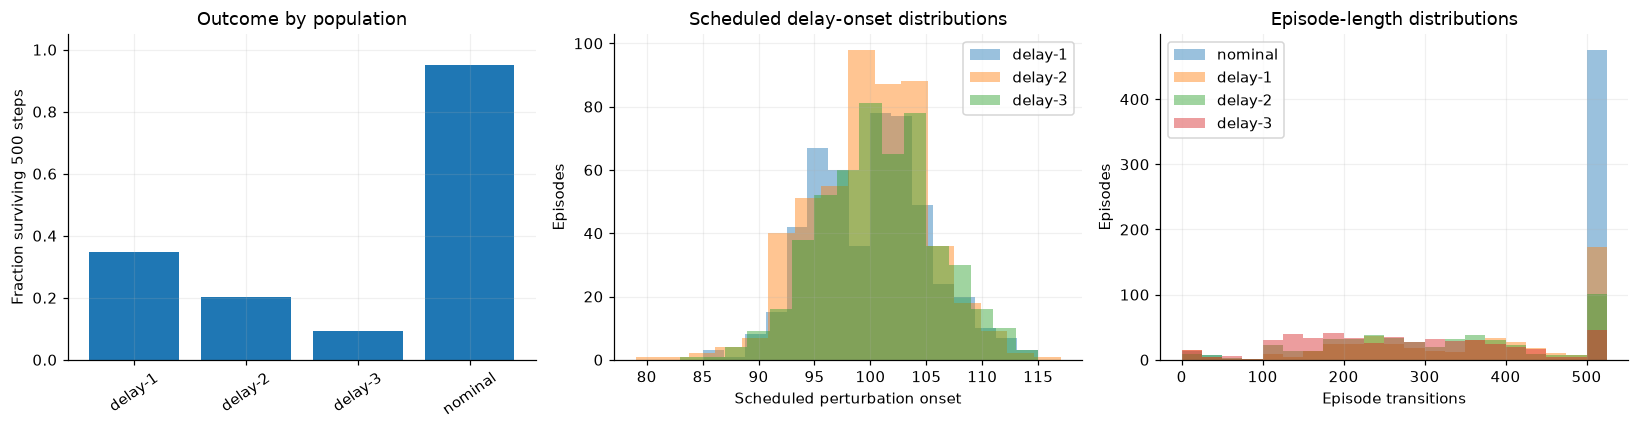

,success_rate,median_return,median_length
population,,,
delay-1,0.346,389.5,389.5
delay-2,0.202,323.0,323.0
delay-3,0.092,262.5,262.5
nominal,0.952,500.0,500.0


In [ ]:
# Plot episode outcome and perturbation-onset summaries.

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

outcome = (
    episodes.query("population in @EVALUATION_POPULATIONS")
    .groupby("population")
    .agg(
        success_rate=("survived_500", "mean"),
        median_return=("episode_return", "median"),
        median_length=("length", "median"),
    )
)
axes[0].bar(outcome.index, outcome.success_rate)
axes[0].set(
    ylabel="Fraction surviving 500 steps",
    title="Outcome by population",
    ylim=(0, 1.05),
)
axes[0].tick_params(axis="x", rotation=35)

for population in DELAY_POPULATIONS:
    values = episodes.loc[episodes.population == population, "onset"].dropna()
    axes[1].hist(values, bins=16, alpha=0.45, label=population)
axes[1].set(xlabel="Scheduled perturbation onset", ylabel="Episodes", title="Scheduled delay-onset distributions")
axes[1].legend()

for population in EVALUATION_POPULATIONS:
    values = episodes.loc[episodes.population == population, "length"]
    axes[2].hist(values, bins=np.arange(0, 526, 25), alpha=0.45, label=population)
axes[2].set(xlabel="Episode transitions", ylabel="Episodes", title="Episode-length distributions")
axes[2].legend()

figure_done("01_episode_protocol")
display(outcome.round(3))


### Findings: episode outcomes

- Nominal test survival is 95.2%: 476 of 500 reach the cutoff.
- Delay-1/2/3 survival is 34.6%, 20.2%, and 9.2%. Median lengths are 389.5, 323, and 262.5 steps.
- Scheduled onset is centered at step 100. Respectively, 21, 19, and 26 delayed-population episodes end before or at onset and contain no delayed transition.

Every severity now has both outcomes. Pre-onset failures reflect unperturbed behavior from random starts; they cannot be attributed to action delay.


### Example episode behavior

Show the first three evaluation episodes in each population, ordered by episode index. The table identifies every episode. Each column uses the same time axis, and each row uses the same state scale. Dotted vertical lines mark delay onset only when it occurs before episode end; crosses mark episode ends.

,population,episode_index,trajectory_id,length,onset
0,nominal,0,traj_20261018T024108372582Z_c87a6d2a,500,None
1,nominal,1,traj_20261018T024108407834Z_706c7bd6,500,None
2,nominal,2,traj_20261018T024108459463Z_06ab5e7c,500,None
3,delay-1,0,traj_20261018T024121548139Z_e592699a,500,103
4,delay-1,1,traj_20261018T024121574909Z_7df890cb,296,102
5,delay-1,2,traj_20261018T024121614793Z_68ff8242,229,105
6,delay-2,0,traj_20261018T024132609748Z_33a7fbb6,499,105
7,delay-2,1,traj_20261018T024132634936Z_9eeeed85,279,100
8,delay-2,2,traj_20261018T024132674798Z_0e88ef78,298,103
9,delay-3,0,traj_20261018T024143016350Z_8b6c6e5a,225,98


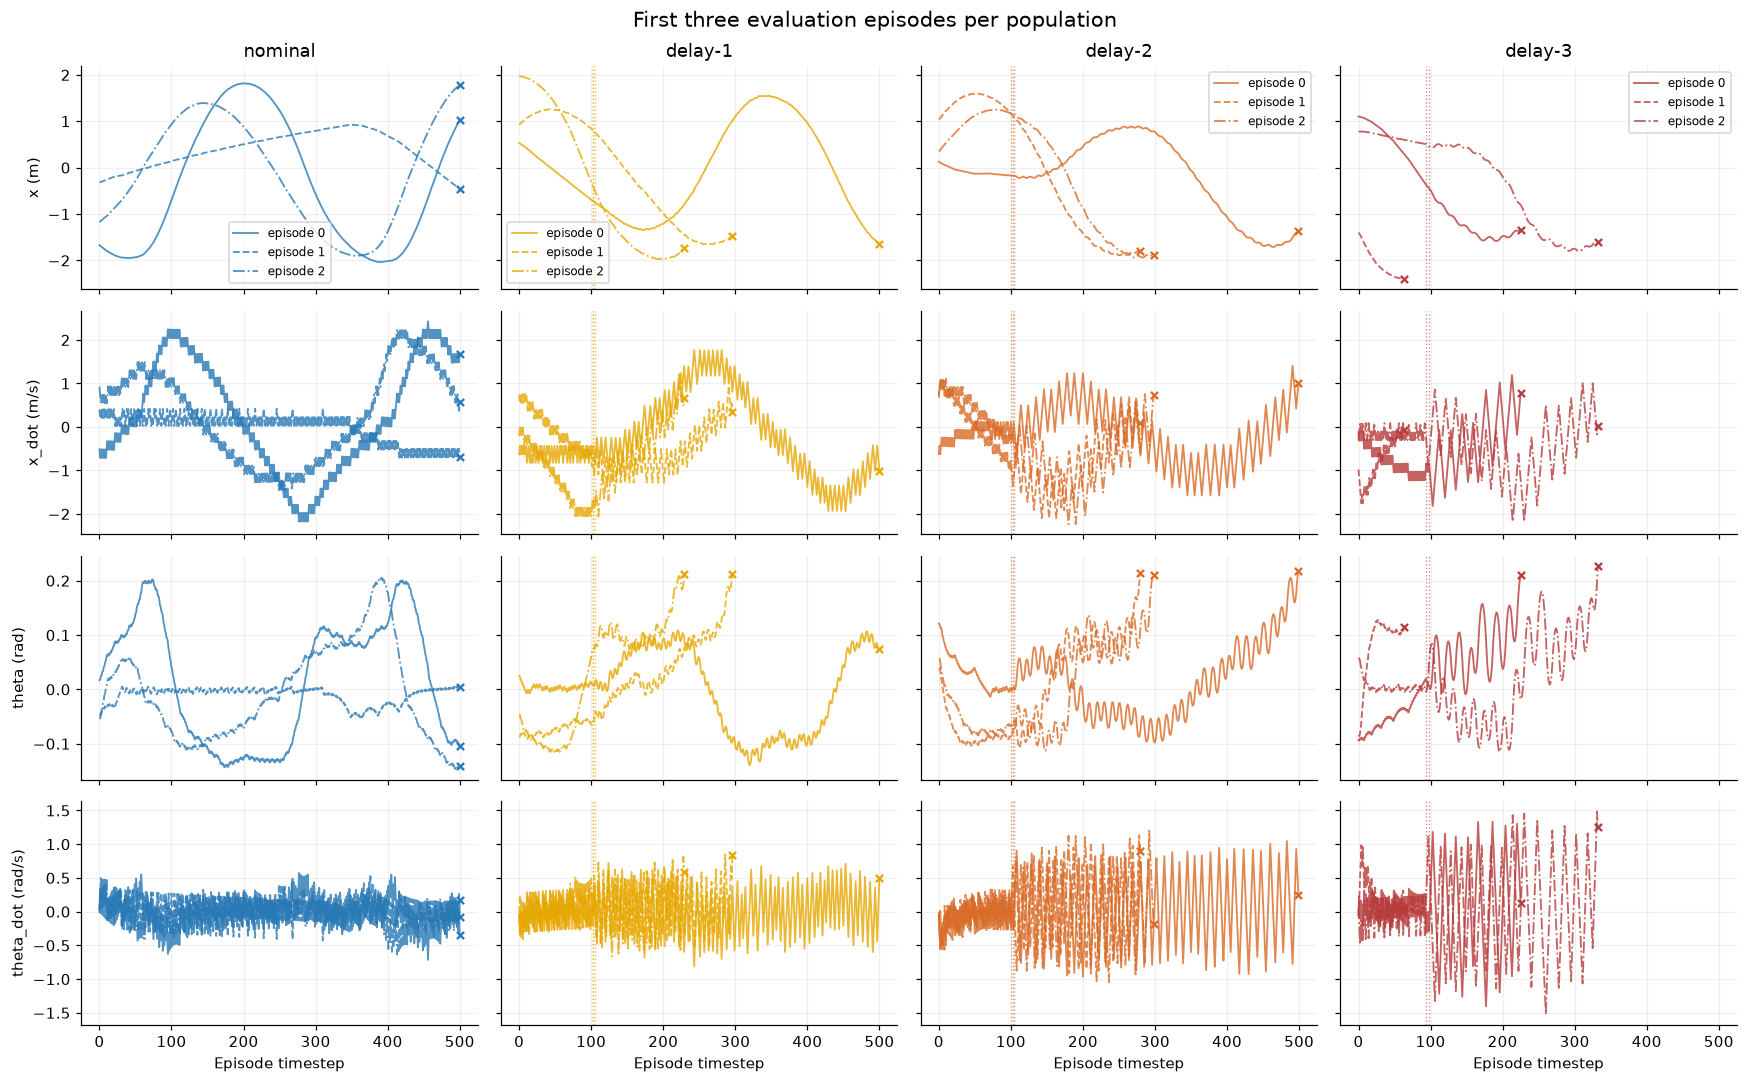

In [ ]:
# Plot the first three evaluation episodes from each population in the four state coordinates.

example_rows = {
    population: episodes.query("population == @population and role == 'evaluation'")
    .sort_values(["episode_index", "trajectory_id"]).head(3)
    for population in EVALUATION_POPULATIONS
}
example_records = {
    population: list(frame.itertuples(index=False))
    for population, frame in example_rows.items()
}
display(pd.concat(example_rows.values(), ignore_index=True)[
    ["population", "episode_index", "trajectory_id", "length", "onset"]
])

state_labels = ("x (m)", "x_dot (m/s)", "theta (rad)", "theta_dot (rad/s)")
example_styles = ("-", "--", "-.")
fig, axes = plt.subplots(
    4, len(EVALUATION_POPULATIONS), figsize=(16, 10),
    sharex=True, sharey="row", squeeze=False,
)
for col, population in enumerate(EVALUATION_POPULATIONS):
    for j, episode in enumerate(example_records[population]):
        trajectory = raw[population][episode.trajectory_id]
        states = trajectory.true_observations
        steps = np.arange(len(states))
        for component in range(4):
            ax = axes[component, col]
            ax.plot(steps, states[:, component], color=COLORS[population],
                    linestyle=example_styles[j], linewidth=1.2, alpha=.8,
                    label=f"episode {episode.episode_index}")
            ax.scatter(steps[-1], states[-1, component], marker="x",
                       color=COLORS[population], s=22, zorder=4)
            if (population in DELAY_POPULATIONS and pd.notna(episode.onset)
                    and 0 <= episode.onset < len(states) - 1):
                ax.axvline(episode.onset, color=COLORS[population],
                           linestyle=":", linewidth=.9, alpha=.6)
    axes[0, col].set_title(population)
    axes[0, col].legend(fontsize=8)
    axes[-1, col].set_xlabel("Episode timestep")
for component, label in enumerate(state_labels):
    axes[component, 0].set_ylabel(label)
fig.suptitle("First three evaluation episodes per population", fontsize=14)
figure_done("01b_first_three_evaluation_episodes")

**Findings.** The nominal examples start at different states and move across much of the track. They do not settle at a common right-side position. Observed delays add sustained velocity and angular oscillations, with larger excursions at higher severity. Early termination appears in every delayed population; delay-3 episode 1 ends before its scheduled intervention.


### Angular phase plane

Plot $\theta$ against $\dot\theta$ for the examples above. Each panel compares nominal with one delay population. Dotted paths show behavior before delay onset; solid delayed paths show behavior from onset onward. Circles mark onset and crosses mark episode ends.

These paths illustrate individual behavior. The later metrics compare the full populations.

Some random-initialization episodes terminate before the scheduled delay. Their full paths remain dotted, with an end cross and no onset circle. An onset at the final state also has no recorded delayed transition. The plot keeps these episodes and does not move their onset to the end.

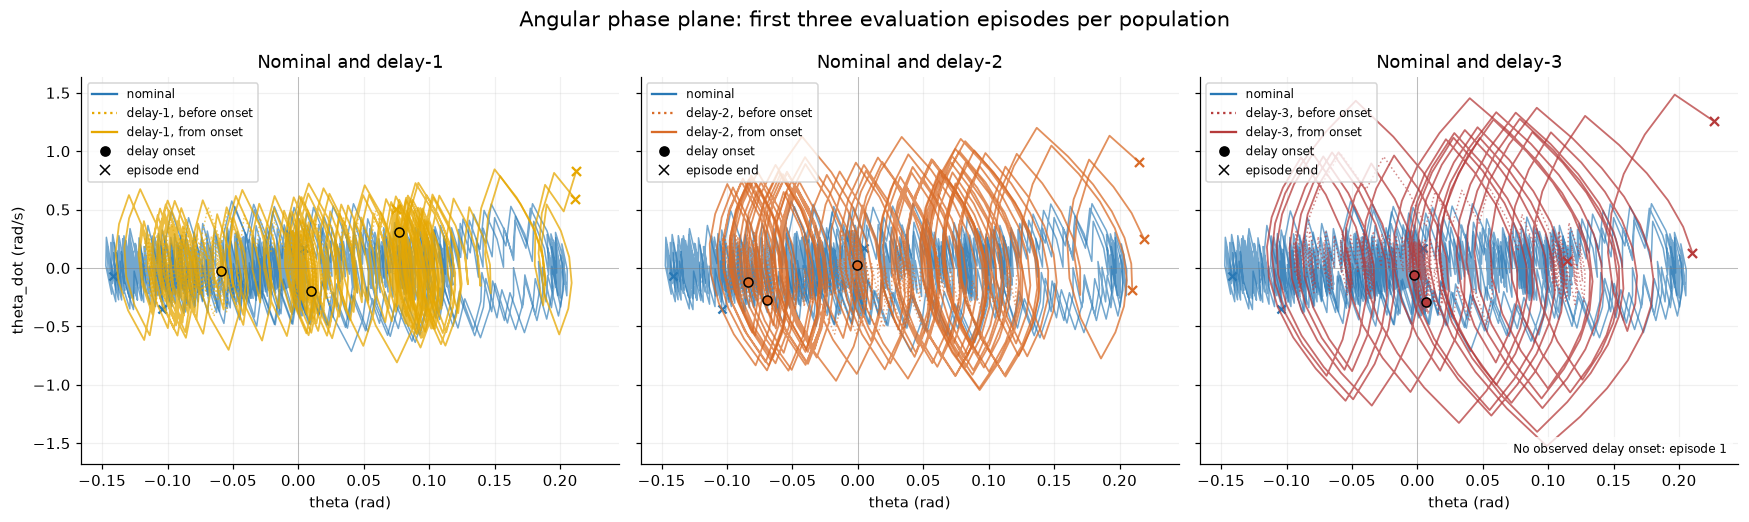

In [12]:
# Compare angular phase-plane paths for the same displayed examples, one delay population per panel.

from matplotlib.lines import Line2D

fig, axes = plt.subplots(1, len(DELAY_POPULATIONS), figsize=(16, 4.8),
                         sharex=True, sharey=True, squeeze=False)
for ax, population in zip(axes.flat, DELAY_POPULATIONS):
    for episode in example_records["nominal"]:
        states = raw["nominal"][episode.trajectory_id].true_observations
        ax.plot(states[:, 2], states[:, 3], color=COLORS["nominal"], alpha=.65, linewidth=1)
        ax.scatter(states[-1, 2], states[-1, 3], color=COLORS["nominal"], marker="x", s=28)
    unobserved_onsets = []
    for episode in example_records[population]:
        states = raw[population][episode.trajectory_id].true_observations
        # An onset at/after the final state never affects a recorded transition.
        onset_reached = pd.notna(episode.onset) and 0 <= episode.onset < len(states) - 1
        if onset_reached:
            onset = int(episode.onset)
            ax.plot(states[:onset + 1, 2], states[:onset + 1, 3],
                    color=COLORS[population], linestyle=":", linewidth=1, alpha=.6)
            ax.plot(states[onset:, 2], states[onset:, 3],
                    color=COLORS[population], linewidth=1.2, alpha=.75)
            ax.scatter(states[onset, 2], states[onset, 3], color=COLORS[population],
                       edgecolor="black", marker="o", s=35, zorder=5)
        else:
            # Preserve the full observed path; do not move onset to the episode end.
            ax.plot(states[:, 2], states[:, 3], color=COLORS[population],
                    linestyle=":", linewidth=1, alpha=.6)
            unobserved_onsets.append(str(episode.episode_index))
        ax.scatter(states[-1, 2], states[-1, 3], color=COLORS[population],
                   marker="x", s=35, zorder=5)
    if unobserved_onsets:
        ax.text(.98, .02, "No observed delay onset: episode " + ", ".join(unobserved_onsets),
                transform=ax.transAxes, ha="right", va="bottom", fontsize=8,
                bbox=dict(facecolor="white", alpha=.8, edgecolor="none"))
    ax.set(title=f"Nominal and {population}", xlabel="theta (rad)")
    ax.axhline(0, color="gray", linewidth=.6, alpha=.5)
    ax.axvline(0, color="gray", linewidth=.6, alpha=.5)
    ax.legend(handles=[
        Line2D([], [], color=COLORS["nominal"], label="nominal"),
        Line2D([], [], color=COLORS[population], linestyle=":", label=f"{population}, before onset"),
        Line2D([], [], color=COLORS[population], label=f"{population}, from onset"),
        Line2D([], [], color="black", marker="o", linestyle="none", label="delay onset"),
        Line2D([], [], color="black", marker="x", linestyle="none", label="episode end"),
    ], fontsize=8, loc="upper left")
axes[0, 0].set_ylabel("theta_dot (rad/s)")
fig.suptitle("Angular phase plane: first three evaluation episodes per population", fontsize=14)
figure_done("01c_example_phase_planes")

**Findings.** Nominal paths span a broad angle range. Delayed paths extend farther in angular velocity, especially for delay-2/3. Delay-3 episode 1 ends at step 63, before onset at 101; its dotted path is an unperturbed early failure.


### Optional $t$-replication inventory

The main grid fixes $t=200$. This cell lists fits under `artifacts/fit/familiarity/t-sweep`. That shared directory is not restricted to the RANDINIT experiment.

A stability experiment needs repeated independent bases at each $t$, fitted to the same RANDINIT data and evaluated with the same scoring protocol.


In [13]:
# Inventory repeated-t fits if they exist. This is descriptive only.

t_sweep_root = FIT_ROOT / "t-sweep"
t_rows = []

if t_sweep_root.exists():
    for candidate in sorted(path for path in t_sweep_root.iterdir() if path.is_dir()):
        try:
            fit = FitArtifact.load(candidate)
        except Exception:
            continue
        if fit.config.idk.representation not in set(REPRESENTATIONS.values()):
            continue
        t_rows.append(
            {
                "directory": candidate.name,
                "representation": fit.config.idk.representation,
                "psi": int(fit.config.idk.psi),
                "t": int(fit.config.idk.t),
                "random_state": fit.config.idk.random_state,
                "fit_id": fit.fit_id,
            }
        )

t_inventory = pd.DataFrame(t_rows)
if len(t_inventory):
    display(
        t_inventory.sort_values(["representation", "psi", "t", "random_state"])
    )
    display(
        t_inventory.groupby(["representation", "psi", "t"])
        .random_state.nunique()
        .rename("independent_basis_seeds")
        .to_frame()
    )
else:
    display(Markdown("No replicated `t-sweep` fits were found. The $t$ question remains open in this notebook."))


,directory,representation,psi,t,random_state,fit_id
20,state_psi-64_t-25_seed-101,state,64,25,101,00a08b7e8fc939412c49fb004abb0a9a83f453dc34cec8...
21,state_psi-64_t-25_seed-101-randinit2181,state,64,25,101,00a08b7e8fc939412c49fb004abb0a9a83f453dc34cec8...
22,state_psi-64_t-25_seed-202,state,64,25,202,cb156e5c83913b0457d6e8136b8dd61f307d32a42d64f7...
23,state_psi-64_t-25_seed-202-randinit2181,state,64,25,202,cb156e5c83913b0457d6e8136b8dd61f307d32a42d64f7...
24,state_psi-64_t-25_seed-303,state,64,25,303,dc649ab0550587c6ecab48a71dc1c453d1fadce4311321...
25,state_psi-64_t-25_seed-303-randinit2181,state,64,25,303,dc649ab0550587c6ecab48a71dc1c453d1fadce4311321...
26,state_psi-64_t-25_seed-404,state,64,25,404,075a767e4df48af4815557d49614e408285b5529e46b69...
27,state_psi-64_t-25_seed-404-randinit2181,state,64,25,404,075a767e4df48af4815557d49614e408285b5529e46b69...
28,state_psi-64_t-25_seed-505,state,64,25,505,50e869c63ad2bee86c49c2499506a973c0dd8c40e425a4...
29,state_psi-64_t-25_seed-505-randinit2181,state,64,25,505,50e869c63ad2bee86c49c2499506a973c0dd8c40e425a4...


independent_basis_seeds
representation psi t                           
state          64  25                         5
                   50                         5
                   100                        5
                   200                        5
                   400                        5

**Findings.** The inventory contains five distinct basis seeds at each of $t=25,50,100,200,400$, for state with $\psi=64$. These fits use the older `fit-nominal-500` dataset. Duplicate directory entries share fit IDs. They are not RANDINIT replications, and no $t$-stability result is established here.


[↑ Back to top](#notebook-top)

<a id="section-2"></a>

## 2. Prepared whole-segment familiarity and support

Prepared segments contain the first 300 transitions, or the full episode if shorter. They mix initial motion, pre-onset behavior, and any recorded post-onset behavior. Shorter episodes contribute less post-onset history.

For every query segment, scores are computed against the **independent reference nominal population** fitted with the same basis.

The core metrics are:

- `idk-familiarity`: native IDK similarity to the nominal reference bank. Higher means more familiar.
- `outside-mass`: average partition-level unsupported mass. Higher means less supported.
- `support-rate`: $1-\text{outside-mass}$. Higher means more supported.
- `idk-distance`, `cosine`, `js`, `kl`: comparison metrics.

`support-rate` is deliberately not called familiarity. A point can be supported by the basis while occupying a different set of supported regions than nominal reference experience.


### Metric definitions and reference aggregation

For a window or segment $W$, let $z_r$ be its represented rows and $\phi(z_r)$ its point features in the fitted IDK basis. Its mean embedding is

$$\mu_W=\frac{1}{n_W}\sum_{r=1}^{n_W}\phi(z_r).$$

Here $n_W$ is the number of represented rows. A window of $k$ transitions contains $k+1$ state rows in 4D and $k$ rows in the 8D, 5D, and 9D representations. $Q$ denotes a query window or segment; $R$ denotes a reference. $t$ is the number of partitions, $j$ indexes partitions, and $c$ indexes the $\psi$ isolation regions within a partition. The coordinate $\mu_{W,jc}$ is a region occupancy fraction.

For JS and KL, each partition needs probabilities that sum to 1. Append the outside probability $1-\sum_{c=1}^{\psi}\mu_{W,jc}$ as category $\psi+1$. Call the resulting probability vectors $q_j$ and $r_j$, and let $m_j=(q_j+r_j)/2$.

| Metric | Calculation for one query and reference | Interpretation and limitation |
| --- | --- | --- |
| IDK familiarity | $\mu_Q^\top\mu_R/t$ | Shared occupancy; depends on support and concentration as well as occupied regions. |
| IDK distance | $\lVert\mu_Q-\mu_R\rVert_2/\sqrt{t}$ | Difference between occupancy vectors; two unsupported zero vectors have zero distance. |
| Outside mass | $t^{-1}\sum_{j=1}^t(1-\sum_{c=1}^{\psi}\mu_{Q,jc})$ | Unsupported fraction of row–partition assignments; uses only the query. |
| Support rate | $1-\text{outside mass}$ | Supported fraction; does not measure similarity to the references. |
| Cosine | $\mu_Q^\top\mu_R/(\lVert\mu_Q\rVert_2\lVert\mu_R\rVert_2)$ | Occupancy direction; can hide changes in magnitude. Zero-vector comparisons return zero. |
| JS | $(2t)^{-1}\sum_j[\mathrm{KL}(q_j\Vert m_j)+\mathrm{KL}(r_j\Vert m_j)]$ | Symmetric divergence in $[0,\log 2]$; shared outside mass can conceal differences between unsupported observations. |
| KL | $t^{-1}\sum_j\mathrm{KL}(\widetilde q_j\Vert\widetilde r_j)$ | Directional divergence; depends on smoothing. |

$\mathrm{KL}(p\Vert q)=\sum_{c=1}^{\psi+1}p_c\log(p_c/q_c)$ uses natural logarithms. KL smooths **all** categories with $\widetilde q_{jc}=(q_{jc}+\epsilon)/(1+(\psi+1)\epsilon)$, and likewise for $r$, using $\epsilon=10^{-6}$. JS uses unsmoothed probabilities.

Outside mass of 0.40 means 40% of row–partition assignments are unsupported. It does not mean 40% of rows are outside every partition.

Each prepared query segment receives the mean pairwise score over 490 nominal reference segments. Window scoring samples up to two windows from each of 50 nominal reference episodes. This run has 100 reference windows for $k=5,10$ and 98 for $k=25,50$, because short episodes cannot supply every window. Those windows can come from anywhere in the reference episodes. All selected references have equal weight; there is no nearest-neighbor selection. Mean pairwise distance is not distance to the mean reference embedding. Outside mass and support rate use only the query.

The full window sweep uses familiarity, distance, outside mass, and cosine. JS and KL are currently computed for prepared segments only. Raw-score plots preserve the original metric direction. Alarm calculations negate familiarity and cosine; larger distance and outside mass are treated as more anomalous.

When $\mu_Q=0$, IDK distance is $\lVert\mu_R\rVert_2/\sqrt{t}$. Losing support can therefore reduce distance to a reference. Read distance alongside outside mass.


In [14]:
# Cache/provenance setup and helpers for whole-segment scoring.

protocol = {
    "version": PROTOCOL_VERSION,
    "fit_ids": sorted(artifact_audit.fit_id.dropna().tolist()),
    "input_files": [
        [str(path.relative_to(ROOT)), path.stat().st_size, path.stat().st_mtime_ns]
        for root in (GENERATED_ROOT, PREPARED_ROOT)
        for path in sorted(root.rglob("*.npz"))
    ],
    "representations": REPRESENTATIONS,
    "psis": PSIS,
    "primary_t": PRIMARY_T,
    "window_sizes": WINDOW_SIZES,
    "focus": [FOCUS_PSI, FOCUS_T, FOCUS_WINDOW],
    "query_stride": QUERY_STRIDE,
    "reference_stride": REFERENCE_STRIDE,
    "reference_episodes": REFERENCE_EPISODES,
    "reference_windows_per_episode": REFERENCE_WINDOWS_PER_EPISODE,
    "reference_ids": list(reference_selection.trajectory_ids),
    "alpha": ALPHA,
    "persistence": PERSISTENCE,
    "random_state": ANALYSIS_RANDOM_STATE,
    "configurations": [list(item) for item in CONFIGURATIONS],
    "software": software_versions(),
}
RUN_ID = hashlib.sha256(json.dumps(protocol, sort_keys=True).encode()).hexdigest()[:16]
CACHE = OUTPUT / RUN_ID
CACHE.mkdir(parents=True, exist_ok=True)

(CACHE / "protocol.json").write_text(json.dumps(protocol, indent=2), encoding="utf-8")
catalogue.to_csv(CACHE / "inventory.csv", index=False)
artifact_audit.to_csv(CACHE / "artifact_audit.csv", index=False)
episodes.to_parquet(CACHE / "episodes.parquet", index=False)

print("Numerical cache:", CACHE)


def unit_frame(artifact: EmbeddingArtifact) -> pd.DataFrame:
    frame = pd.DataFrame([unit.record() for unit in artifact.embeddings.units])
    if "source_trajectory_id" in frame.columns:
        frame["episode_id"] = frame["source_trajectory_id"].astype(str)
    else:
        frame["episode_id"] = frame["trajectory_id"].astype(str)
    return frame


def add_episode_outcomes(frame: pd.DataFrame, population: str) -> pd.DataFrame:
    meta = episodes.loc[
        episodes.population == population,
        ["trajectory_id", "length", "episode_return", "onset", "survived_500", "failure"],
    ].rename(columns={"trajectory_id": "episode_id"})
    out = frame.merge(meta, on="episode_id", how="left")
    out["population"] = population
    out["severity"] = severity_of(population)
    out["role"] = "calibration" if population == "calibration" else "evaluation"
    return out


def prepared_embedding(fit, rep, psi, t, population):
    path = embedding_path(rep, psi, population, t)
    if not path.exists():
        raise FileNotFoundError(
            f"Missing prepared embedding: {path}. Generate it with cartpole-embed before running this notebook."
        )
    artifact = EmbeddingArtifact.load(path)
    if artifact.config.fit_id != fit.fit_id:
        raise ValueError(f"{path}: embedding belongs to a different basis")
    return artifact


def score_whole_configuration(rep: str, psi: int, t: int) -> pd.DataFrame:
    fit = FitArtifact.load(fit_path(rep, psi, t))
    reference_artifact = prepared_embedding(fit, rep, psi, t, "reference")
    reference = reference_artifact.embeddings

    tables = []

    for population in QUERY_POPULATIONS:
        artifact = prepared_embedding(fit, rep, psi, t, population)
        sample = artifact.embeddings
        sample.compatible_with(reference)

        base = add_episode_outcomes(unit_frame(artifact), population)

        outside = partition_outside_mass(sample.values, t=t, psi=psi).mean(axis=1)

        for metric in WHOLE_METRICS:
            if metric == "outside-mass":
                values = outside
            elif metric == "support-rate":
                values = 1.0 - outside
            else:
                engine_metric = metric_engine_name(metric)
                values = reduce_references(
                    sample.values,
                    reference.values,
                    n_partitions=t,
                    metric=PYIDK_METRICS[engine_metric],
                    aggregation="mean",
                    metric_parameters=metric_parameters(metric),
                ).scores

            frame = base.copy()
            frame["representation"] = rep
            frame["psi"] = psi
            frame["t"] = t
            frame["metric"] = metric
            frame["score"] = values
            frame["anomaly"] = anomaly_oriented(metric, values)
            tables.append(frame)

    return pd.concat(tables, ignore_index=True)


Numerical cache: /Users/dma0523/code/research/cartpole-idk/artifacts/analysis/idk-familiarity-action-delay-v3/d3b90acef455d000


In [15]:
# Compute/reload whole-segment scores across the primary grid.

whole_tables = []
progress = []

for number, (rep, psi, t) in enumerate(WHOLE_CONFIGURATIONS, start=1):
    name = config_name(rep, psi, t)
    path = CACHE / f"whole_{name}.parquet"
    started = time.perf_counter()

    cached = path.exists() and not RERUN
    if not cached:
        scores = score_whole_configuration(rep, psi, t)
        scores.to_parquet(path, index=False)
        del scores

    table = pd.read_parquet(path)
    whole_tables.append(table)

    progress.append(
        {
            "configuration": name,
            "status": "cached" if cached else "computed",
            "rows": len(table),
            "seconds": time.perf_counter() - started,
        }
    )
    print(
        f"[{number}/{len(CONFIGURATIONS)}] {name}: "
        f"{progress[-1]['status']}, {len(table):,} rows",
        flush=True,
    )

whole_scores = pd.concat(whole_tables, ignore_index=True)
del whole_tables
gc.collect()

display(pd.DataFrame(progress).round(2))
display(
    whole_scores.groupby(["representation", "population", "metric"])
    .agg(n=("score", "size"), median=("score", "median"))
    .round(4)
)


[1/28] psi-8_t-200_state-randinit2181: computed, 17,045 rows
[2/28] psi-16_t-200_state-randinit2181: computed, 17,045 rows
[3/28] psi-32_t-200_state-randinit2181: computed, 17,045 rows
[4/28] psi-64_t-200_state-randinit2181: computed, 17,045 rows
[5/28] psi-128_t-200_state-randinit2181: computed, 17,045 rows
[6/28] psi-256_t-200_state-randinit2181: computed, 17,045 rows
[7/28] psi-512_t-200_state-randinit2181: computed, 17,045 rows
[8/28] psi-8_t-200_transition-randinit2181: computed, 17,045 rows
[9/28] psi-16_t-200_transition-randinit2181: computed, 17,045 rows
[10/28] psi-32_t-200_transition-randinit2181: computed, 17,045 rows
[11/28] psi-64_t-200_transition-randinit2181: computed, 17,045 rows
[12/28] psi-128_t-200_transition-randinit2181: computed, 17,045 rows
[13/28] psi-256_t-200_transition-randinit2181: computed, 17,045 rows
[14/28] psi-512_t-200_transition-randinit2181: computed, 17,045 rows
[15/28] psi-8_t-200_state_action-randinit2181: computed, 17,045 rows
[16/28] psi-16_t-20

,configuration,status,rows,seconds
0,psi-8_t-200_state-randinit2181,computed,17045,43.42
1,psi-16_t-200_state-randinit2181,computed,17045,71.55
2,psi-32_t-200_state-randinit2181,computed,17045,122.78
3,psi-64_t-200_state-randinit2181,computed,17045,209.89
4,psi-128_t-200_state-randinit2181,computed,17045,372.79
5,psi-256_t-200_state-randinit2181,computed,17045,677.39
6,psi-512_t-200_state-randinit2181,computed,17045,1274.16
7,psi-8_t-200_transition-randinit2181,computed,17045,40.70
8,psi-16_t-200_transition-randinit2181,computed,17045,66.93
9,psi-32_t-200_transition-randinit2181,computed,17045,113.18


n  median
representation population  metric                       
state          calibration cosine           3416  0.3437
                           idk-distance     3416  0.1993
                           idk-familiarity  3416  0.0085
                           js               3416  0.2521
                           kl               3416  3.3490
...                                          ...     ...
transition     nominal     idk-familiarity  3402  0.0091
                           js               3402  0.2475
                           kl               3402  3.3135
                           outside-mass     3402  0.4250
                           support-rate     3402  0.5750

[140 rows x 2 columns]

### Basis support across $\psi$

The left heatmaps show mean support for each population. Support is $1-\text{outside mass}$: the fraction of represented-row/partition assignments inside an isolation region, averaged within segments and then across segments. 

The right heatmaps show nominal support minus delayed support, in percentage points. Positive values mean the delayed population has less support. Zero means no mean support difference.

Compare calibration and nominal rows to check consistency between independent nominal populations. Compare columns to see how $\psi$ changes support and the separation between populations. All panels use $t=200$. These prepared segments describe behavior retrospectively; the later raw-window analysis measures detection timing.


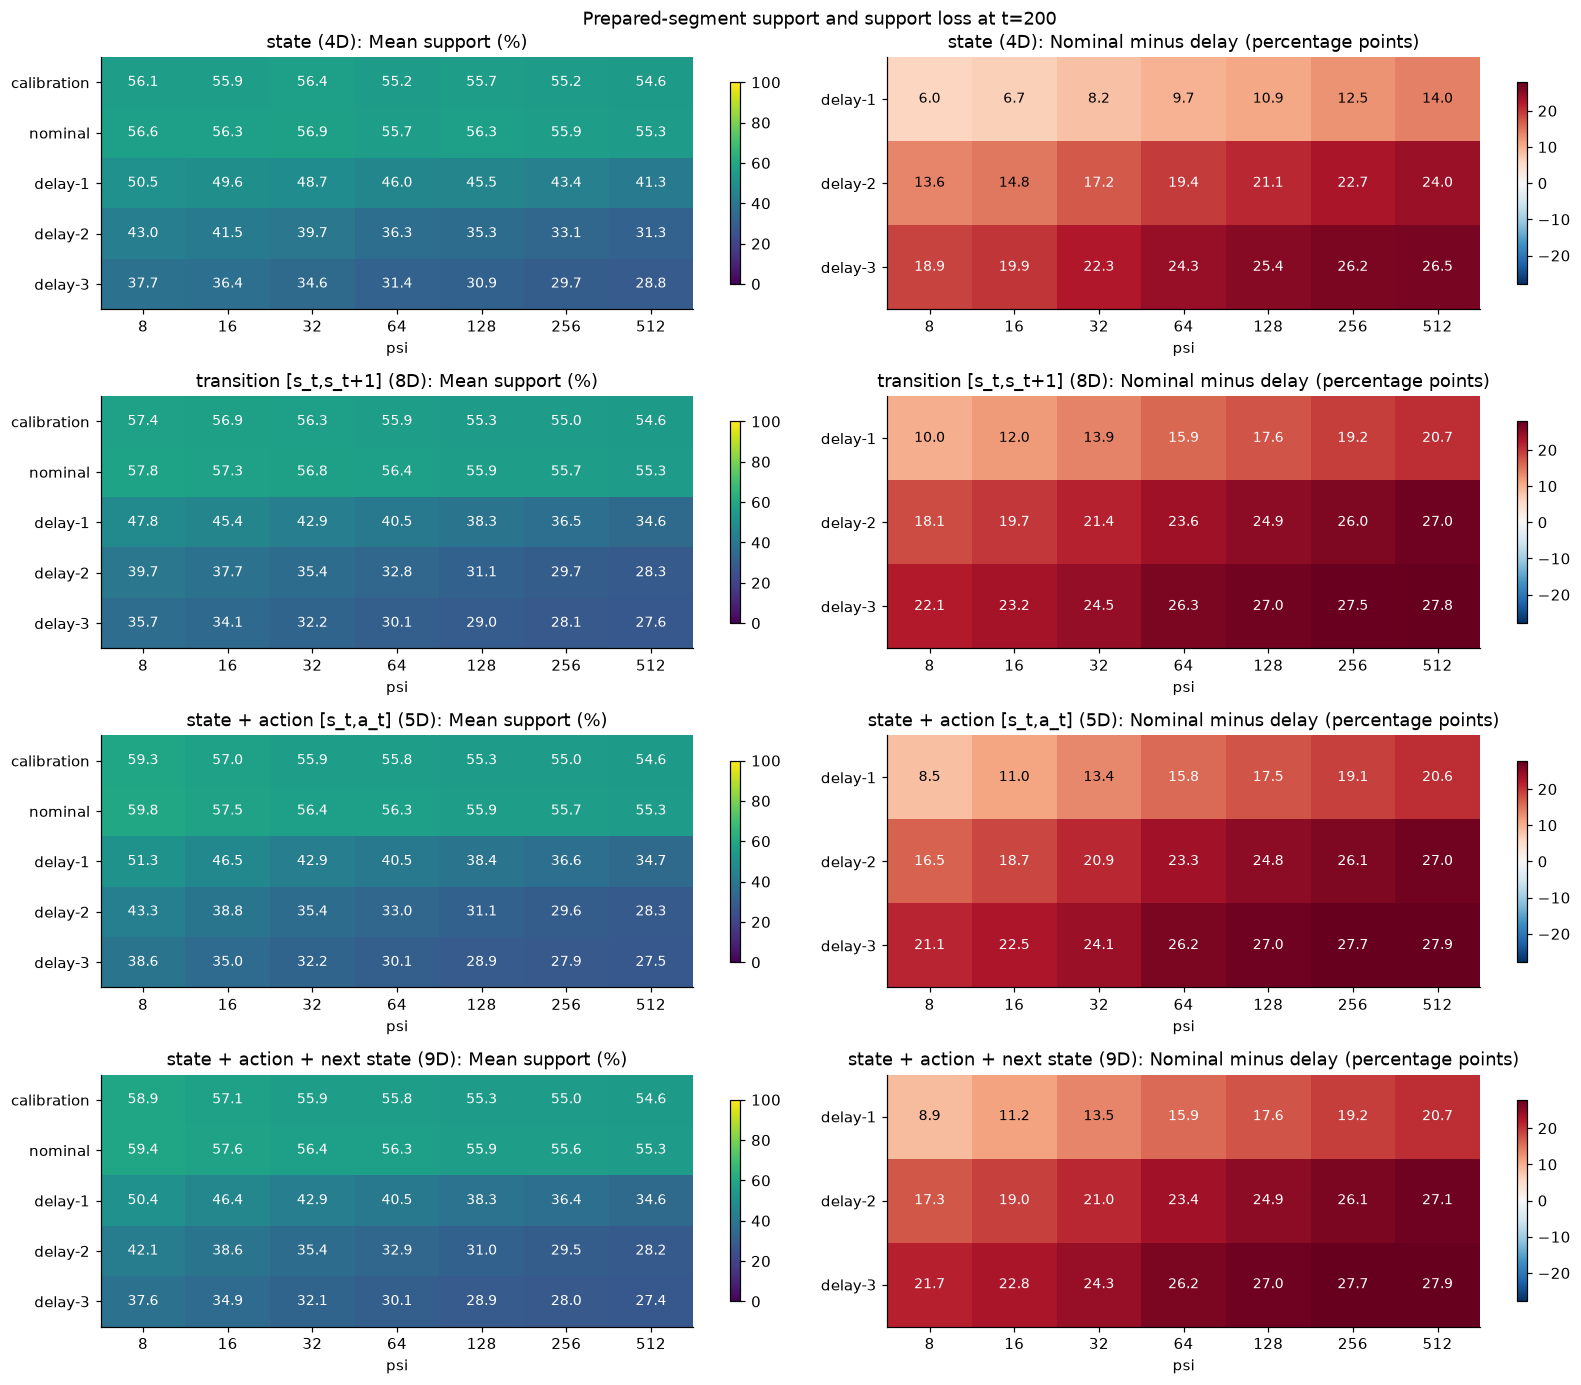

,representation,population,psi,mean_support,q25,q75,n
0,state,calibration,8,0.5612,0.5057,0.6252,488
1,state,calibration,16,0.5589,0.5340,0.5978,488
2,state,calibration,32,0.5644,0.5486,0.6003,488
3,state,calibration,64,0.5516,0.5412,0.5857,488
4,state,calibration,128,0.5566,0.5470,0.5953,488
...,...,...,...,...,...,...,...
135,transition,nominal,32,0.5675,0.5428,0.6071,486
136,transition,nominal,64,0.5641,0.5474,0.6001,486
137,transition,nominal,128,0.5593,0.5486,0.5912,486
138,transition,nominal,256,0.5567,0.5439,0.5936,486


In [16]:
# Compare absolute basis support and nominal-to-delay support loss across psi.

support_table = (
    whole_scores.query("metric == 'support-rate'")
    .groupby(["representation", "population", "psi"], as_index=False)
    .agg(mean_support=("score", "mean"),
         q25=("score", lambda x: x.quantile(.25)),
         q75=("score", lambda x: x.quantile(.75)), n=("score", "size"))
)
support_grids, loss_grids = {}, {}
for rep in REPRESENTATIONS:
    grid = support_table.query("representation == @rep").pivot(
        index="population", columns="psi", values="mean_support"
    ).reindex(index=QUERY_POPULATIONS, columns=PSIS) * 100
    support_grids[rep] = grid
    loss_grids[rep] = grid.loc[list(DELAY_POPULATIONS)].rsub(grid.loc["nominal"], axis=1)
limit = max(1., max(np.nanmax(np.abs(g.to_numpy())) for g in loss_grids.values()))
fig, axes = plt.subplots(len(REPRESENTATIONS), 2, figsize=(15, 3.2 * len(REPRESENTATIONS)), squeeze=False)
for row, rep in enumerate(REPRESENTATIONS):
    for col, (grid, cmap, low, high, label) in enumerate([
        (support_grids[rep], "viridis", 0, 100, "Mean support (%)"),
        (loss_grids[rep], "RdBu_r", -limit, limit, "Nominal minus delay (percentage points)"),
    ]):
        ax = axes[row, col]
        im = ax.imshow(grid, cmap=cmap, vmin=low, vmax=high, aspect="auto")
        ax.grid(False)
        ax.set_xticks(range(len(PSIS)), labels=PSIS)
        ax.set_yticks(range(len(grid)), labels=grid.index)
        ax.set(xlabel="psi", title=f"{REP_LABELS[rep]}: {label}")
        for y, x in np.ndindex(grid.shape):
            value = grid.iloc[y, x]
            rgba = im.cmap(im.norm(value))
            color = "black" if np.dot(rgba[:3], [.299, .587, .114]) > .55 else "white"
            ax.text(x, y, f"{value:.1f}" if np.isfinite(value) else "missing",
                    ha="center", va="center", color=color, fontsize=9)
        fig.colorbar(im, ax=ax, shrink=.8)
fig.suptitle(f"Prepared-segment support and support loss at t={PRIMARY_T}")
figure_done("02_support_vs_psi")
support_table.to_csv(CACHE / "whole_support.csv", index=False)
display(support_table.round(4))


### Findings: basis support

- Nominal test support is about 55–60% across the grid. Calibration support is within one percentage point of nominal test support.
- Support decreases with delay severity at every configuration. Delay-3 has the lowest support.
- Increasing $\psi$ widens the nominal-to-delay gap. For delay-1, the gap grows from 6 to 14 percentage points in state, and from roughly 8–10 to 21 points in the other representations.
- Transition and both action representations are nearly identical from $\psi=32$ onward. The 9D representation gives no clear additional support separation.


### Whole-segment departure separation

For each delay severity, compare prepared delayed segments with the independent nominal test segments.

AUROC measures score ordering, not the amount of unsupported mass or the fraction of failures. Familiarity, cosine, and support rate are negated; distance, outside mass, JS, and KL retain their signs.

Let $a_D$ and $a_N$ be anomaly-oriented scores from a delayed and a nominal segment. AUROC estimates $P(a_D>a_N)+\tfrac12P(a_D=a_N)$: 1 means perfect ordering in the declared direction, 0.5 means chance ordering, and 0 means completely reversed ordering.

The summary table also reports:

| Summary | Meaning |
| --- | --- |
| Average precision | Precision averaged over increases in recall as the score threshold changes; the no-skill baseline is the delayed fraction (approximately 0.5 here, with slightly unequal prepared counts). |
| KS | Largest vertical gap between the two score CDFs; detects differences in either direction. |
| Wasserstein | Area between the two score CDFs; measures distribution difference in score units. Its magnitude depends on the metric's scale. |

KS and Wasserstein here compare distributions of scalar scores. They are not distances between trajectory embeddings. None of these summaries sets the online alarm threshold.


,representation,psi,t,metric,delay_population,severity,n_nominal,n_delay,auroc,average_precision,ks,wasserstein_anomaly,median_nominal_anomaly,median_delay_anomaly
66,state,64,200,idk-distance,delay-1,1,486,485,0.469,0.459,0.192,0.015,0.180,0.182
67,state,64,200,idk-distance,delay-2,2,486,491,0.496,0.466,0.190,0.018,0.180,0.183
68,state,64,200,idk-distance,delay-3,3,486,485,0.559,0.485,0.296,0.021,0.180,0.186
63,state,64,200,idk-familiarity,delay-1,1,486,485,0.892,0.838,0.670,0.002,-0.009,-0.007
64,state,64,200,idk-familiarity,delay-2,2,486,491,0.955,0.921,0.898,0.003,-0.009,-0.005
65,state,64,200,idk-familiarity,delay-3,3,486,485,0.962,0.940,0.899,0.004,-0.009,-0.004
69,state,64,200,outside-mass,delay-1,1,486,485,0.948,0.874,0.866,0.097,0.433,0.534
70,state,64,200,outside-mass,delay-2,2,486,491,0.963,0.913,0.932,0.194,0.433,0.643
71,state,64,200,outside-mass,delay-3,3,486,485,0.969,0.929,0.922,0.243,0.433,0.706
360,state_action,64,200,idk-distance,delay-1,1,486,485,0.426,0.435,0.219,0.017,0.175,0.174


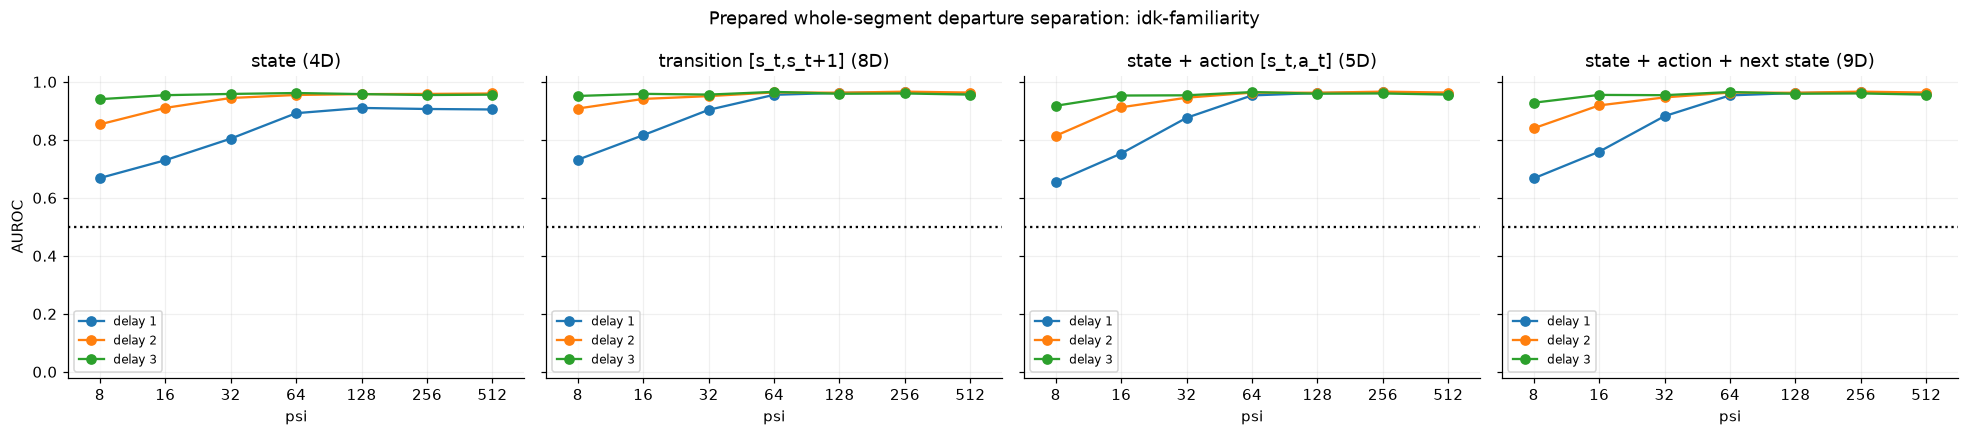

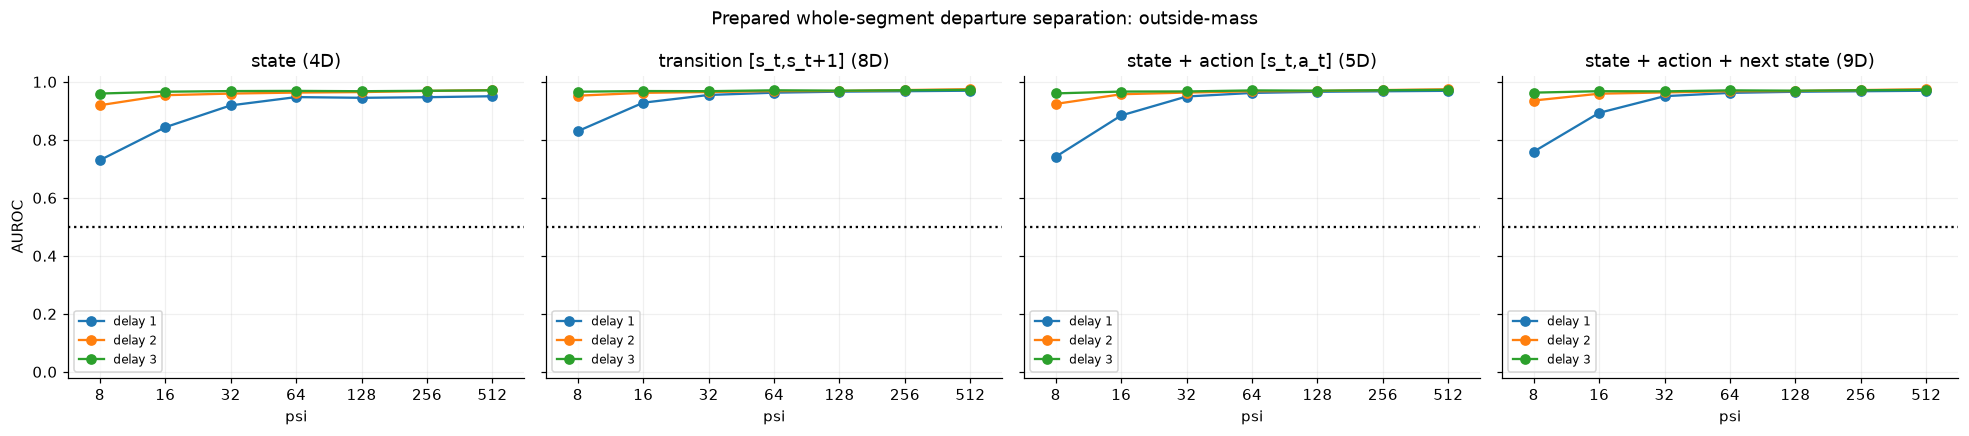

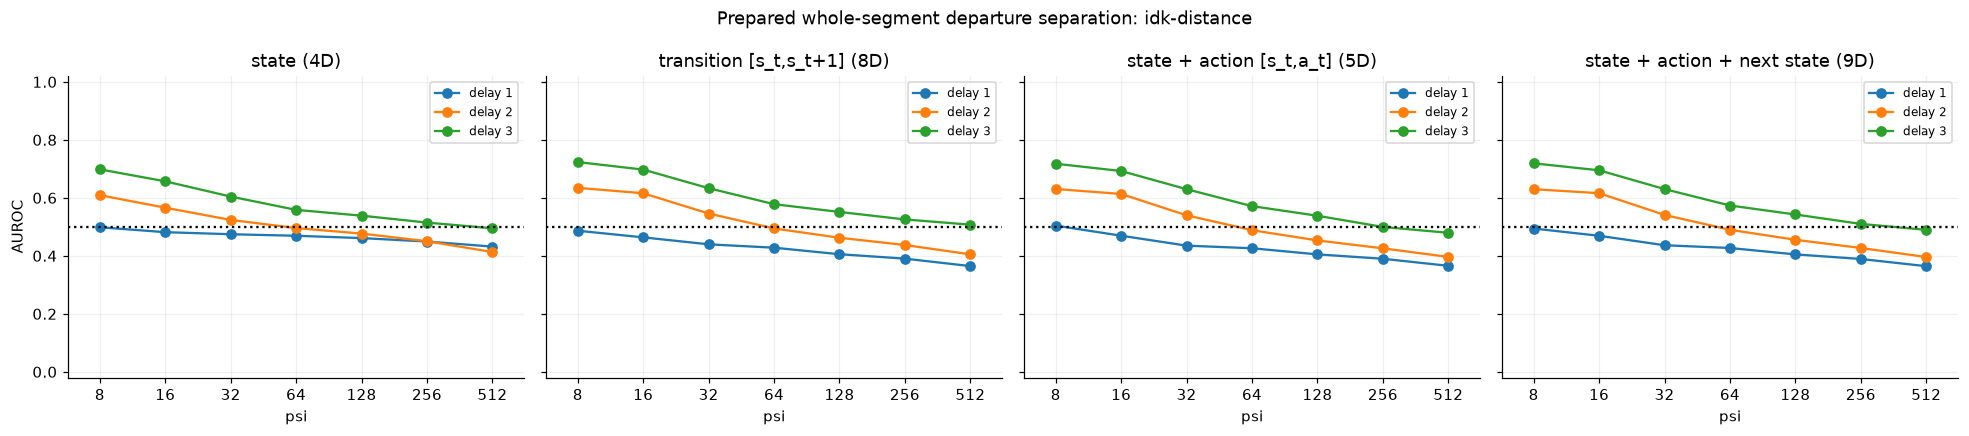

In [17]:
# Whole-segment separation summaries.

whole_separation_rows = []

for (rep, psi, t, metric), group in whole_scores.query(
    "population in @EVALUATION_POPULATIONS"
).groupby(["representation", "psi", "t", "metric"], sort=False):
    nominal = group[group.population == "nominal"]

    for delay_population in DELAY_POPULATIONS:
        delayed = group[group.population == delay_population]
        combined = pd.concat([nominal, delayed], ignore_index=True).dropna(subset=["anomaly"])
        if len(nominal) == 0 or len(delayed) == 0:
            continue

        labels = (combined.population == delay_population).astype(int)
        a = nominal.anomaly.dropna().to_numpy()
        b = delayed.anomaly.dropna().to_numpy()

        whole_separation_rows.append(
            {
                "representation": rep,
                "psi": psi,
                "t": t,
                "metric": metric,
                "delay_population": delay_population,
                "severity": severity_of(delay_population),
                "n_nominal": len(a),
                "n_delay": len(b),
                "auroc": roc_auc_score(labels, combined.anomaly),
                "average_precision": average_precision_score(labels, combined.anomaly),
                "ks": ks_2samp(a, b).statistic,
                "wasserstein_anomaly": wasserstein_distance(a, b),
                "median_nominal_anomaly": float(np.median(a)),
                "median_delay_anomaly": float(np.median(b)),
            }
        )

whole_separation = pd.DataFrame(whole_separation_rows)
whole_separation.to_csv(CACHE / "whole_separation.csv", index=False)

display(
    whole_separation.query(
        "psi == @FOCUS_PSI and metric in ['idk-familiarity', 'outside-mass', 'idk-distance']"
    )
    .sort_values(["representation", "metric", "severity"])
    .round(3)
)

for metric in ("idk-familiarity", "outside-mass", "idk-distance"):
    fig, axes = plt.subplots(1, len(REPRESENTATIONS), figsize=(4.5 * len(REPRESENTATIONS), 4), sharey=True)
    if len(REPRESENTATIONS) == 1:
        axes = [axes]
    for ax, rep in zip(axes, REPRESENTATIONS):
        for severity in (1, 2, 3):
            g = whole_separation.query(
                "representation == @rep and metric == @metric and severity == @severity"
            ).sort_values("psi")
            ax.plot(g.psi, g.auroc, marker="o", label=f"delay {severity}")
        ax.axhline(0.5, linestyle=":", color="black")
        ax.set(
            title=REP_LABELS[rep],
            xlabel="psi",
            ylabel="AUROC" if ax is axes[0] else None,
            ylim=(-0.02, 1.02),
        )
        psi_axis(ax)
        ax.legend(fontsize=8)
    fig.suptitle(f"Prepared whole-segment departure separation: {metric}")
    figure_done(f"03_whole_auroc_{metric.replace('-', '_')}")


### Findings: whole-segment separation

- Mild delay is harder to separate at small $\psi$. Delay-1 outside-mass AUROC rises from roughly 0.73–0.83 at $\psi=8$ to 0.95–0.96 at 64.
- Familiarity separation improves through roughly $\psi=64$–128. Transition and both action representations then give AUROC near 0.96 for all severities; state remains weaker for delay-1.
- IDK-distance ordering weakens as $\psi$ increases. At 512, AUROC is roughly 0.36–0.43 for delay-1/2 and 0.48–0.51 for delay-3. Whole-segment distance does not approach zero AUROC in this run.

Loss of support can shrink occupancy vectors and their distance to references. Greater distance is therefore not a reliable departure direction. The short-window results below show a much stronger reversal.


### Raw-score distributions

At the focus basis, each curve is an empirical CDF of the raw scores for one evaluation population. Each segment contributes one score. The vertical coordinate is the fraction of segments with score at or below the horizontal coordinate; 0.5 identifies the median.

A curve farther right indicates larger scores. Lower familiarity or cosine and higher outside mass are the expected departure directions. Distance may reverse direction. CDF height is a population fraction, not basis support or a failure probability. Calibration episodes are excluded.

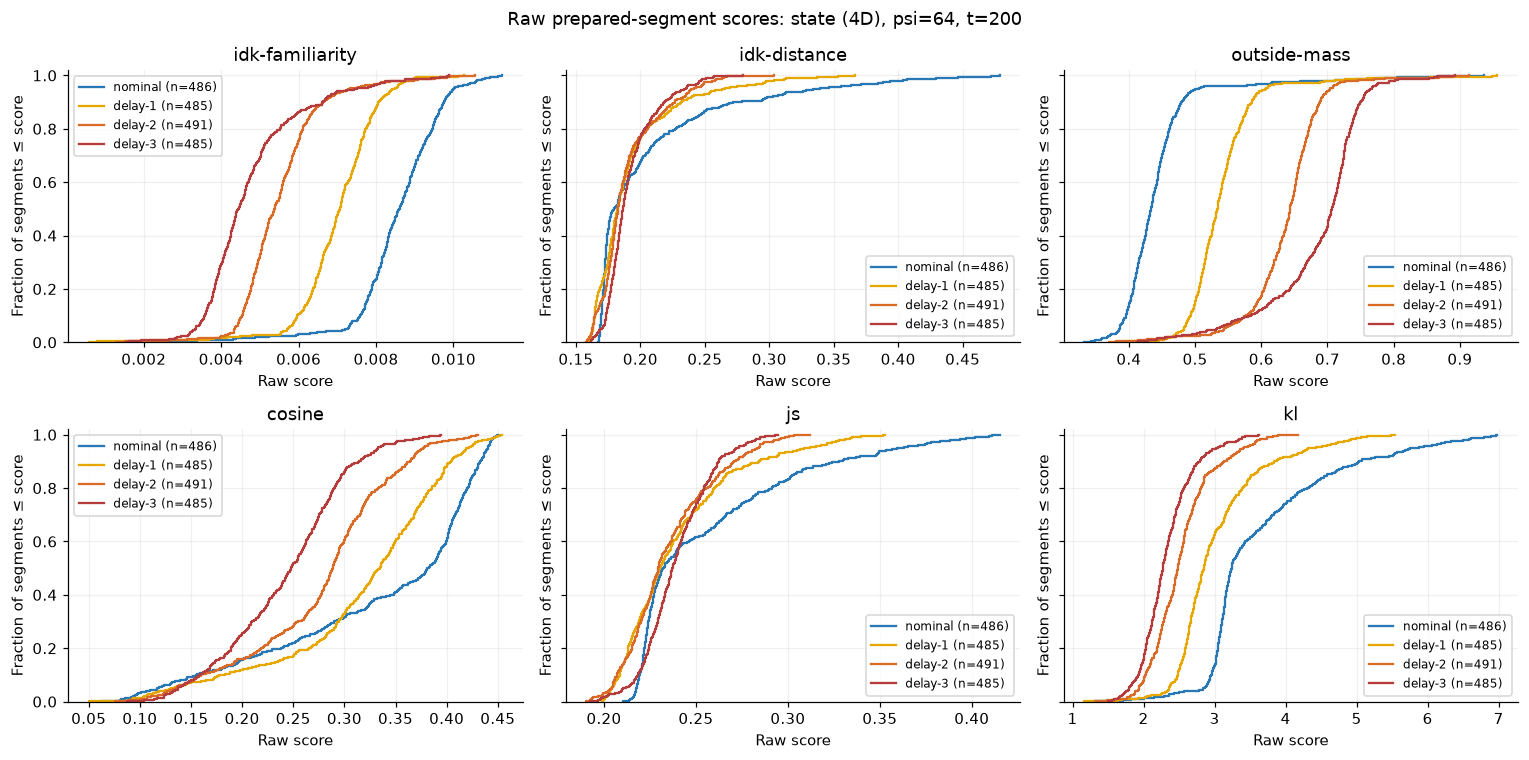

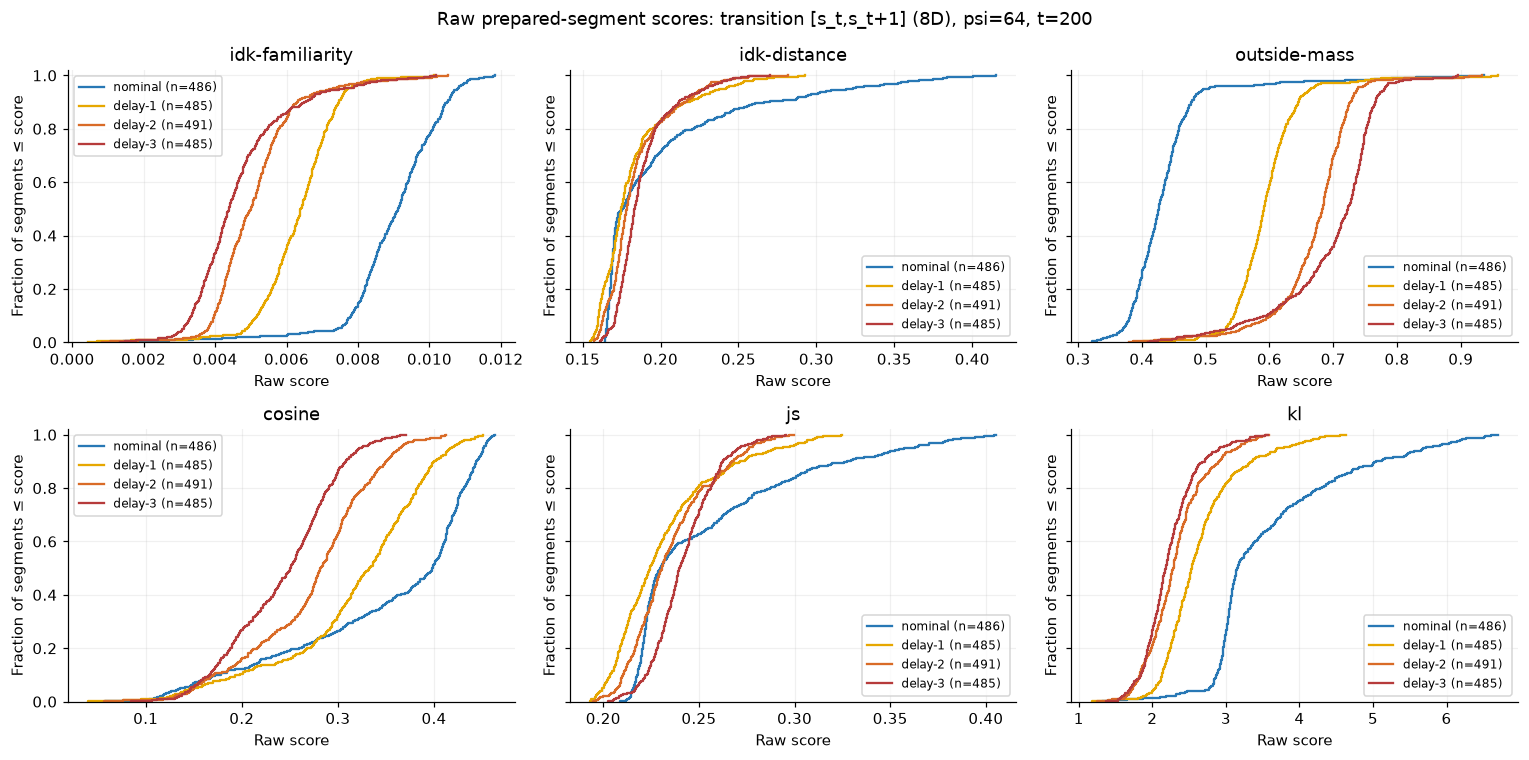

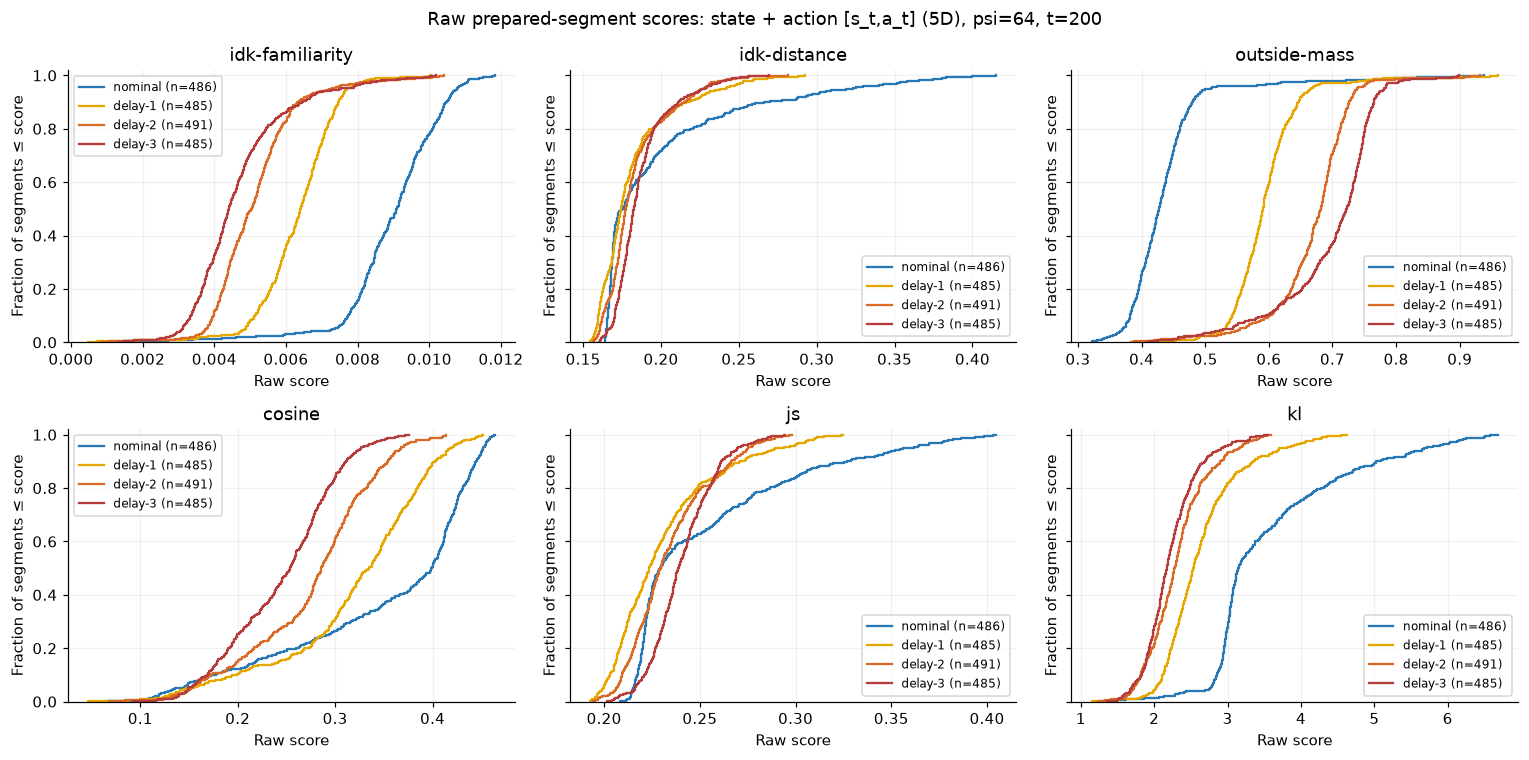

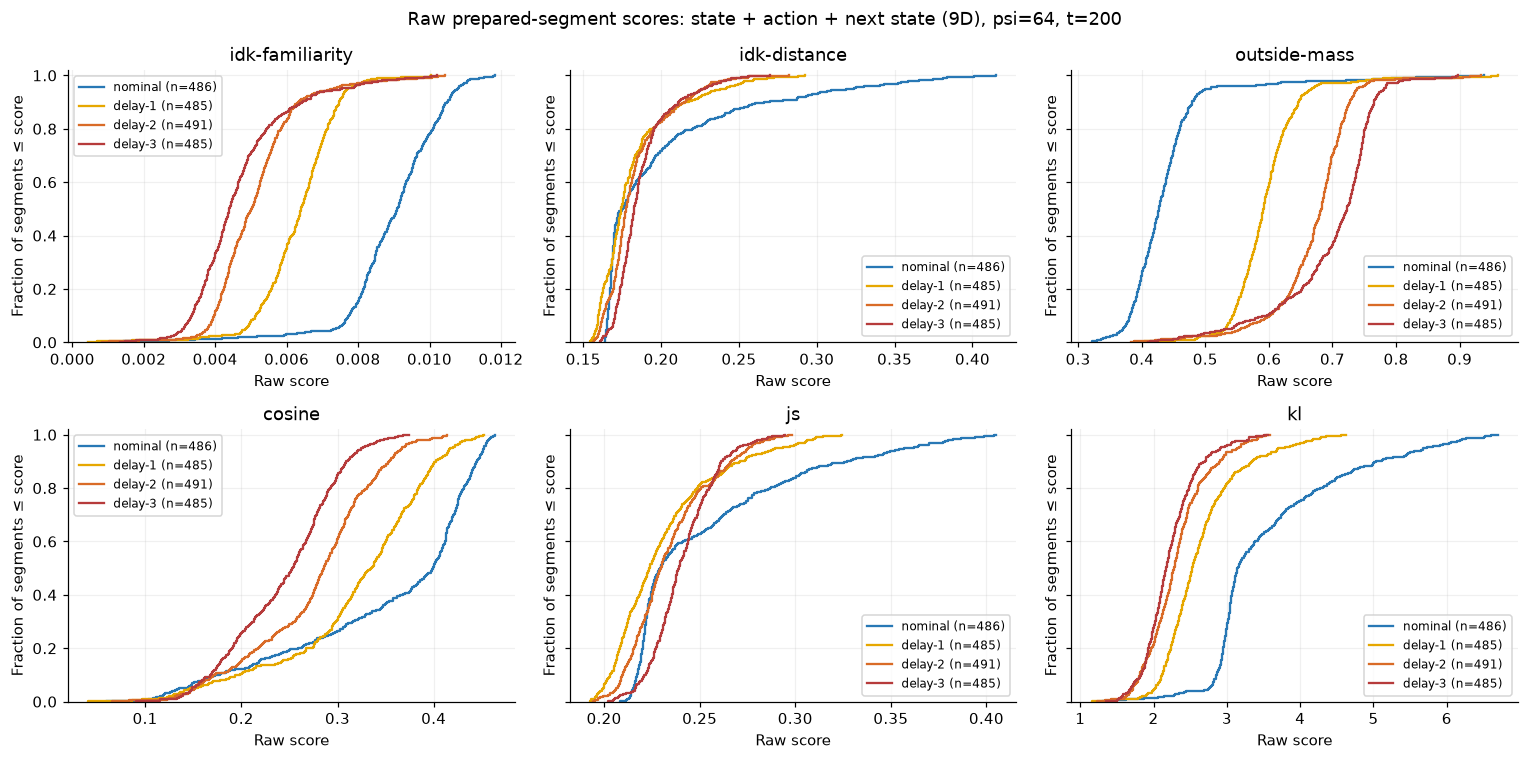

In [18]:
# Plot raw segment-score distributions for each representation at the focus basis.

RAW_CDF_METRICS = ("idk-familiarity", "idk-distance", "outside-mass", "cosine", "js", "kl")
segment_focus = whole_scores.query(
    "psi == @FOCUS_PSI and t == @FOCUS_T and population in @EVALUATION_POPULATIONS"
)
for rep in REPRESENTATIONS:
    fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
    for ax, metric in zip(axes.flat, RAW_CDF_METRICS):
        for population in EVALUATION_POPULATIONS:
            values = segment_focus.query(
                "representation == @rep and metric == @metric and population == @population"
            ).score.to_numpy(dtype=float)
            values = np.sort(values[np.isfinite(values)])
            if len(values) == 0:
                raise ValueError(f"No finite segment scores for {rep}, {metric}, {population}")
            # Include the lower endpoint so the empirical CDF starts at zero.
            ax.step(np.r_[values[0], values], np.arange(len(values) + 1) / len(values),
                    where="post", color=COLORS[population],
                    label=f"{population} (n={len(values)})")
        ax.set(title=metric, xlabel="Raw score", ylabel="Fraction of segments ≤ score", ylim=(0, 1.02))
        ax.legend(fontsize=8)
    fig.suptitle(f"Raw prepared-segment scores: {REP_LABELS[rep]}, psi={FOCUS_PSI}, t={FOCUS_T}")
    figure_done(f"10_segment_ecdfs_{rep}")

### Mean raw scores across $\psi$

Each point is the mean segment score for an evaluation population at $t=200$. Segments have equal weight. Similarity and distance scores have already been averaged over the reference bank. Panels within each metric share a vertical scale.

Changing $\psi$ changes the fitted regions. Compare the population curves and their gaps; raw levels across different bases are not a common calibrated scale of anomalousness.

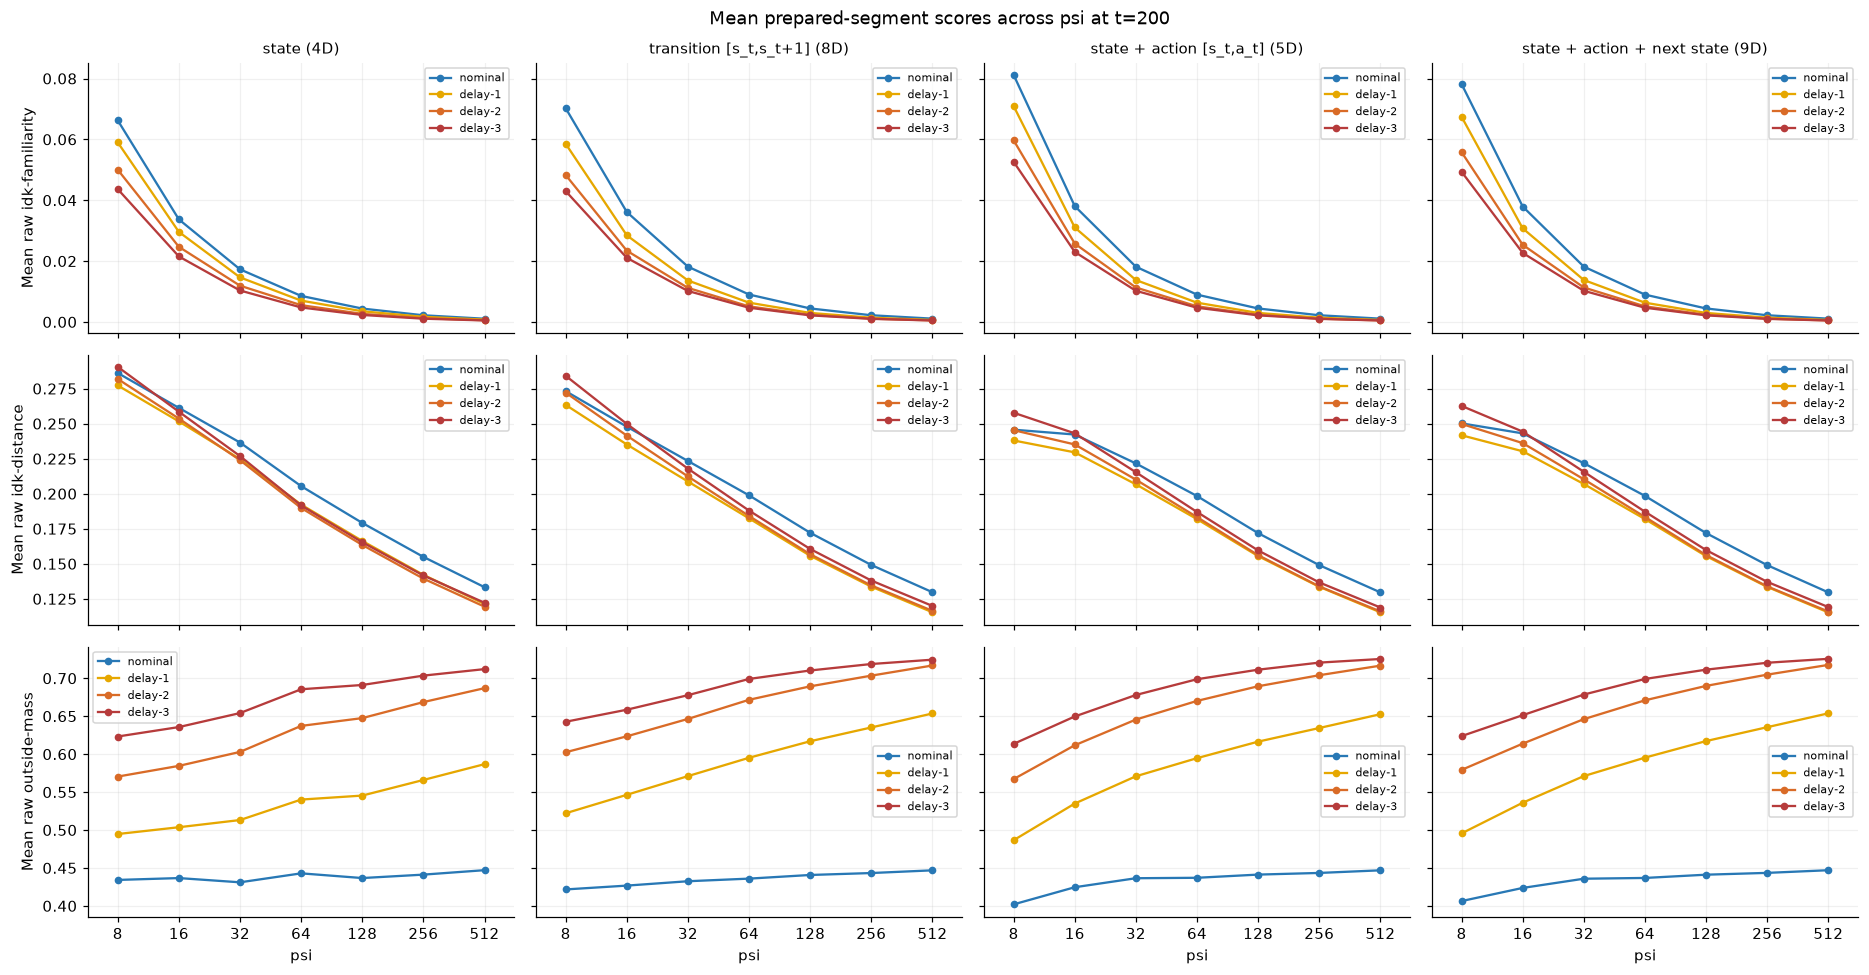

In [19]:
# Compare mean raw familiarity, distance, and outside mass across psi and populations.

RAW_MEAN_METRICS = ("idk-familiarity", "idk-distance", "outside-mass")
mean_segment_scores = (
    whole_scores.query("t == @PRIMARY_T and population in @EVALUATION_POPULATIONS and metric in @RAW_MEAN_METRICS")
    .groupby(["representation", "psi", "t", "population", "metric"], as_index=False)
    .agg(mean_score=("score", "mean"), n_segments=("score", "count"))
)
mean_segment_scores.to_csv(CACHE / "mean_raw_segment_scores.csv", index=False)
fig, axes = plt.subplots(len(RAW_MEAN_METRICS), len(REPRESENTATIONS),
                         figsize=(17, 9), sharex=True, sharey="row", squeeze=False)
for row, metric in enumerate(RAW_MEAN_METRICS):
    for col, rep in enumerate(REPRESENTATIONS):
        ax = axes[row, col]
        for population in EVALUATION_POPULATIONS:
            g = mean_segment_scores.query(
                "representation == @rep and metric == @metric and population == @population"
            ).sort_values("psi")
            ax.plot(g.psi, g.mean_score, marker="o", markersize=4,
                    color=COLORS[population], label=population)
        psi_axis(ax)
        if row == 0:
            ax.set_title(REP_LABELS[rep], fontsize=10)
        if col == 0:
            ax.set_ylabel(f"Mean raw {metric}")
        if row == len(RAW_MEAN_METRICS) - 1:
            ax.set_xlabel("psi")
        ax.legend(fontsize=7)
fig.suptitle(f"Mean prepared-segment scores across psi at t={PRIMARY_T}")
figure_done("11_mean_raw_segment_scores")

**Findings.** At $\psi=64$, delayed segments have lower familiarity and higher outside mass, with stronger shifts at greater delay. Distance and JS CDFs cross and overlap. KL is mostly smaller for delayed segments, reversing its declared anomaly direction. Cosine shows more overlap than familiarity.

Across $\psi$, mean familiarity and distance shrink for every population. Mean delayed outside mass rises while nominal outside mass stays near 0.40–0.45. Raw score levels change with the basis; separation must be assessed from the population distributions.


[↑ Back to top](#notebook-top)

<a id="section-3"></a>

## 3. Sliding-window familiarity on the original full episodes

Whole segments discard when departure begins. The main experiment therefore returns to the **original generated episodes** and scores sliding windows against windows from the independent reference population.

This section serves two distinct purposes:

1. **Onset-relative separation:** at a given number of steps before/after perturbation onset, can the score distinguish delayed from nominal experience?
2. **Online monitoring:** if a threshold is calibrated only on independent nominal calibration episodes, how quickly can it detect departure on held-out episodes?

The notebook keeps those questions separate so window length is not confused with alarm startup latency.


In [20]:
# Window-scoring cache helpers.

ROLE_BY_POP = {
    "calibration": "calibration",
    "nominal": "evaluation",
    "delay-1": "evaluation",
    "delay-2": "evaluation",
    "delay-3": "evaluation",
}


def window_path(rep, psi, t, population, k, aggregation="mean", detail=False):
    suffix = "detail" if detail else "core"
    return CACHE / (
        f"windows_{config_name(rep, psi, t)}_{population}_"
        f"k{k}_{aggregation}_{suffix}.parquet"
    )


def normalize_window_metrics(frame: pd.DataFrame) -> pd.DataFrame:
    frame = frame.copy()
    frame["metric"] = frame.metric.replace({"idk": "idk-familiarity"})
    frame["anomaly"] = np.nan

    for metric in frame.metric.unique():
        selected = frame.metric == metric
        frame.loc[selected, "anomaly"] = anomaly_oriented(
            metric, frame.loc[selected, "score"]
        )

    # Add support-rate as an interpretable mirror of outside mass.
    outside = frame[frame.metric == "outside-mass"].copy()
    if len(outside):
        outside["metric"] = "support-rate"
        outside["score"] = 1.0 - outside["score"]
        outside["anomaly"] = -outside["score"]
        frame = pd.concat([frame, outside], ignore_index=True)

    return frame


def add_window_identity(frame, rep, psi, t, population):
    frame = frame.copy()
    frame["representation"] = rep
    frame["psi"] = psi
    frame["t"] = t
    frame["population"] = population
    frame["severity"] = severity_of(population)
    frame["role"] = ROLE_BY_POP[population]

    if "source_trajectory_id" in frame.columns:
        frame["episode_id"] = frame["source_trajectory_id"].astype(str)
    else:
        frame["episode_id"] = frame["trajectory_id"].astype(str)

    return frame


In [21]:
# Compute/reload the full sliding-window sweep.

for number, (rep, psi, t) in enumerate(CONFIGURATIONS, start=1):
    fit = FitArtifact.load(fit_path(rep, psi, t))

    for population, selection in query_selections.items():
        pending = [
            k
            for k in WINDOW_SIZES
            if RERUN or not window_path(rep, psi, t, population, k).exists()
        ]
        if not pending:
            continue

        session = WindowAnalytics(
            fit,
            selection,
            {"nominal_reference": reference_selection},
        )

        for k in pending:
            path = window_path(rep, psi, t, population, k)
            started = time.perf_counter()

            config = WindowScoringConfig(
                window_length=k,
                query_stride=QUERY_STRIDE,
                reference_stride=REFERENCE_STRIDE,
                reference_windows_per_trajectory=REFERENCE_WINDOWS_PER_EPISODE,
                random_state=ANALYSIS_RANDOM_STATE,
                metrics=WINDOW_ENGINE_METRICS,
                aggregation="mean",
            )

            result = session.score(config)
            frame = add_window_identity(result.scores, rep, psi, t, population)
            frame = normalize_window_metrics(frame)

            keep = [
                "representation",
                "psi",
                "t",
                "population",
                "severity",
                "role",
                "trajectory_id",
                "episode_id",
                "window_length",
                "start_step",
                "end_step",
                "source_end_step",
                "metric",
                "score",
                "anomaly",
                "eligible_reference_count",
                "selected_count",
            ]
            keep = [column for column in keep if column in frame.columns]

            result.reference_windows.to_parquet(
                path.with_suffix(".references.parquet"),
                index=False,
            )
            result.skipped.to_parquet(
                path.with_suffix(".skipped.parquet"),
                index=False,
            )
            path.with_suffix(".json").write_text(
                json.dumps(result.metadata, indent=2),
                encoding="utf-8",
            )
            frame[keep].to_parquet(path, index=False)

            print(
                f"[{number}/{len(CONFIGURATIONS)}] {rep} psi={psi} t={t} "
                f"{population} k={k}: {len(frame):,} rows; "
                f"{time.perf_counter() - started:.1f}s",
                flush=True,
            )

            del result, frame
            gc.collect()

        del session
        gc.collect()

core_paths = [
    window_path(rep, psi, t, population, k)
    for rep, psi, t in CONFIGURATIONS
    for population in QUERY_POPULATIONS
    for k in WINDOW_SIZES
]

# Score times are aligned for display only. Reference windows come from anywhere.
onset_lookup = episodes.set_index(["population", "trajectory_id"]).onset
NOMINAL_ALIGNMENT_ONSET = int(round(episodes.loc[
    episodes.population.isin(DELAY_POPULATIONS), "onset"
].median()))


def load_window_scores(rep, psi, t, k, populations=QUERY_POPULATIONS, metrics=None):
    filters = [("metric", "in", list(metrics))] if metrics is not None else None
    frame = pd.concat([
        pd.read_parquet(window_path(rep, psi, t, pop, k), filters=filters)
        for pop in populations
    ], ignore_index=True)
    keys = pd.MultiIndex.from_frame(frame[["population", "episode_id"]])
    frame["analysis_onset"] = onset_lookup.reindex(keys).to_numpy()
    frame.loc[~frame.population.isin(DELAY_POPULATIONS), "analysis_onset"] = NOMINAL_ALIGNMENT_ONSET
    frame["relative_start"] = frame.start_step - frame.analysis_onset
    frame["relative_end"] = frame.end_step - frame.analysis_onset
    frame["relative_bin"] = (QUERY_STRIDE * np.rint(frame.relative_end / QUERY_STRIDE)).astype(int)
    return frame


def iter_window_groups(populations=QUERY_POPULATIONS, metrics=None):
    for rep, psi, t in CONFIGURATIONS:
        for k in WINDOW_SIZES:
            frame = load_window_scores(rep, psi, t, k, populations, metrics)
            for metric, group in frame.groupby("metric", sort=False):
                yield (rep, psi, t, k, metric), group


focus_scores = pd.concat([
    load_window_scores(rep, psi, t, FOCUS_WINDOW, EVALUATION_POPULATIONS)
    for rep, psi, t in CONFIGURATIONS if psi == FOCUS_PSI and t == FOCUS_T
], ignore_index=True)
print(f"Cached window score rows: {sum(pq.read_metadata(p).num_rows for p in core_paths):,}")
print("Focus plots include:", ", ".join(focus_scores.representation.unique()))
print("Nominal display anchor:", NOMINAL_ALIGNMENT_ONSET)


[1/28] state psi=8 t=200 calibration k=5: 238,760 rows; 5.4s
[1/28] state psi=8 t=200 calibration k=10: 236,260 rows; 5.2s
[1/28] state psi=8 t=200 calibration k=25: 228,870 rows; 5.6s
[1/28] state psi=8 t=200 calibration k=50: 216,755 rows; 5.7s
[1/28] state psi=8 t=200 nominal k=5: 238,550 rows; 5.2s
[1/28] state psi=8 t=200 nominal k=10: 236,050 rows; 5.4s
[1/28] state psi=8 t=200 nominal k=25: 228,655 rows; 5.6s
[1/28] state psi=8 t=200 nominal k=50: 216,630 rows; 5.7s
[1/28] state psi=8 t=200 delay-1 k=5: 179,550 rows; 4.0s
[1/28] state psi=8 t=200 delay-1 k=10: 177,050 rows; 4.1s
[1/28] state psi=8 t=200 delay-1 k=25: 169,645 rows; 4.2s
[1/28] state psi=8 t=200 delay-1 k=50: 157,580 rows; 4.4s
[1/28] state psi=8 t=200 delay-2 k=5: 157,875 rows; 3.6s
[1/28] state psi=8 t=200 delay-2 k=10: 155,375 rows; 3.6s
[1/28] state psi=8 t=200 delay-2 k=25: 147,925 rows; 3.8s
[1/28] state psi=8 t=200 delay-2 k=50: 135,730 rows; 3.9s
[1/28] state psi=8 t=200 delay-3 k=5: 134,705 rows; 2.9s
[1/

### Score curves

Lines show mean **raw window scores** across evaluation episodes; shading shows their interquartile range. The IQR describes variation across query episodes, not across reference windows and not uncertainty in the mean. Each query window has already been reduced to one score per metric.

Left panels use episode time; the gray band spans the observed delay-onset range. Right panels subtract each delayed episode's own onset and use the median delayed onset as a nominal display anchor. Endpoints are binned at the scoring stride. Reference scoring uses windows sampled anywhere in the nominal reference episodes.

The bottom row shows contributing episodes, using the familiarity scores. Later delayed curves can change because short episodes have ended. The onset-relative panels focus on −50 to +125 steps; the episode-time panels show the full recorded horizon.

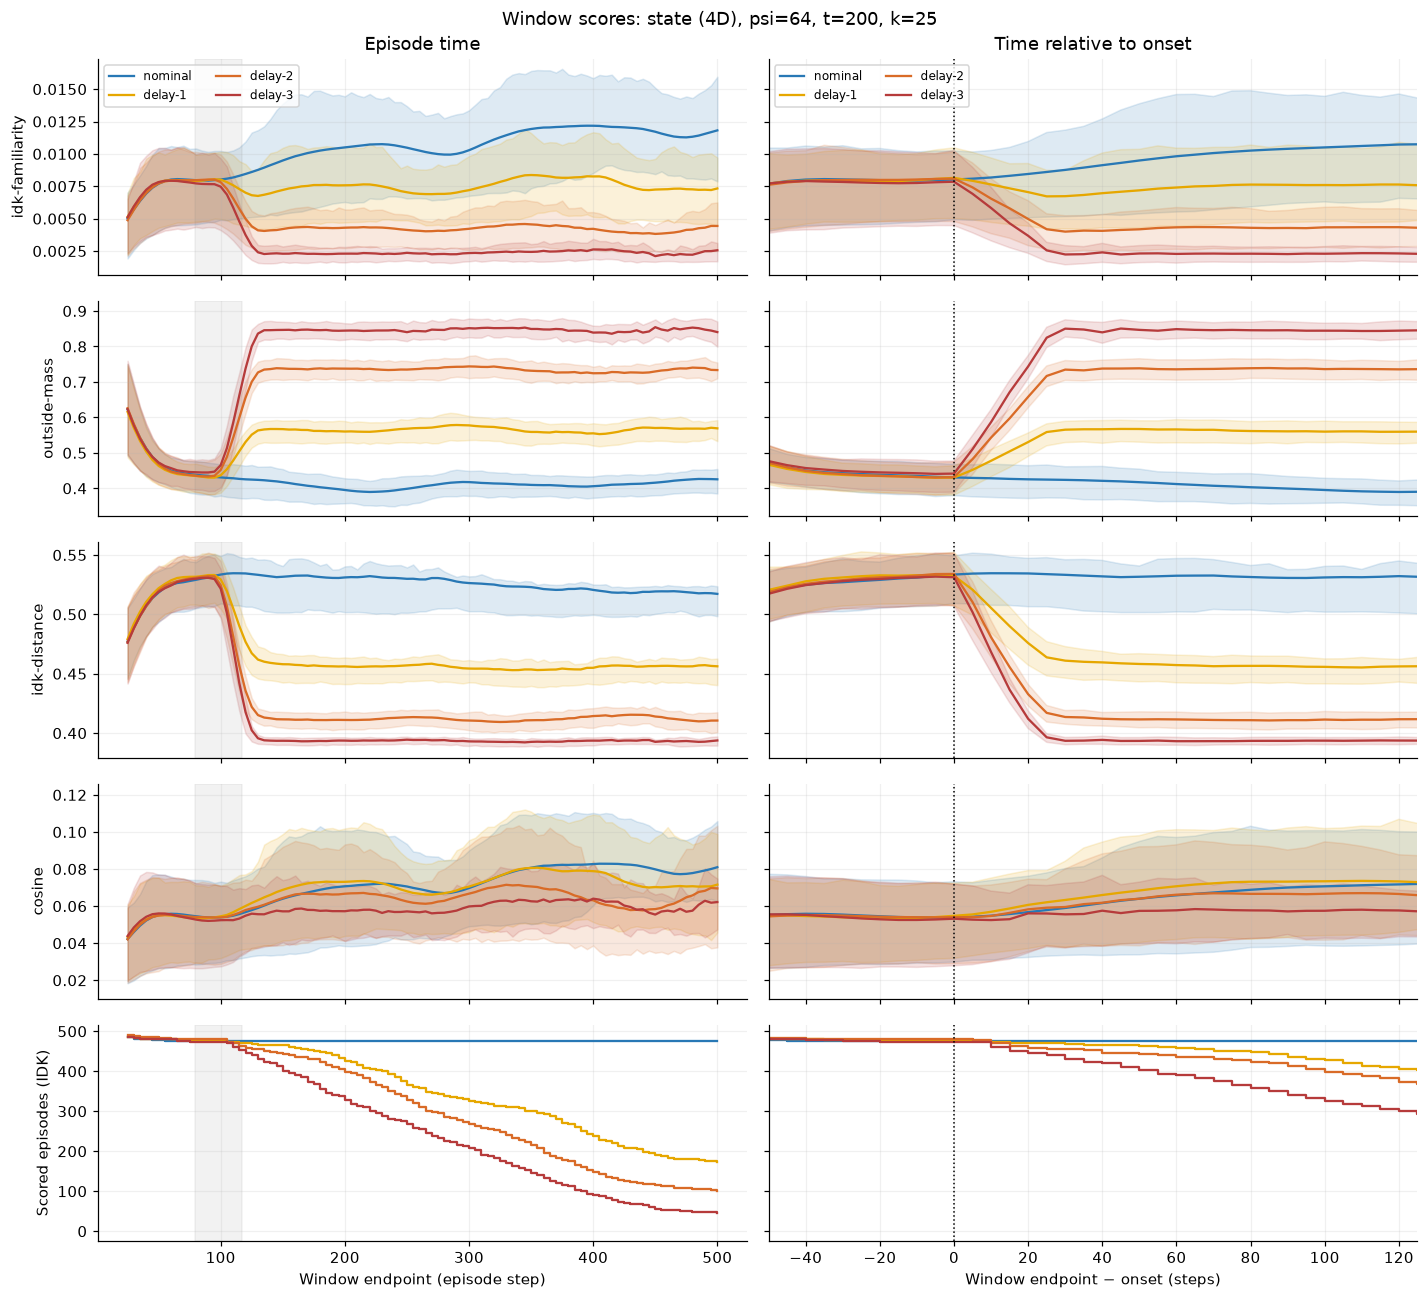

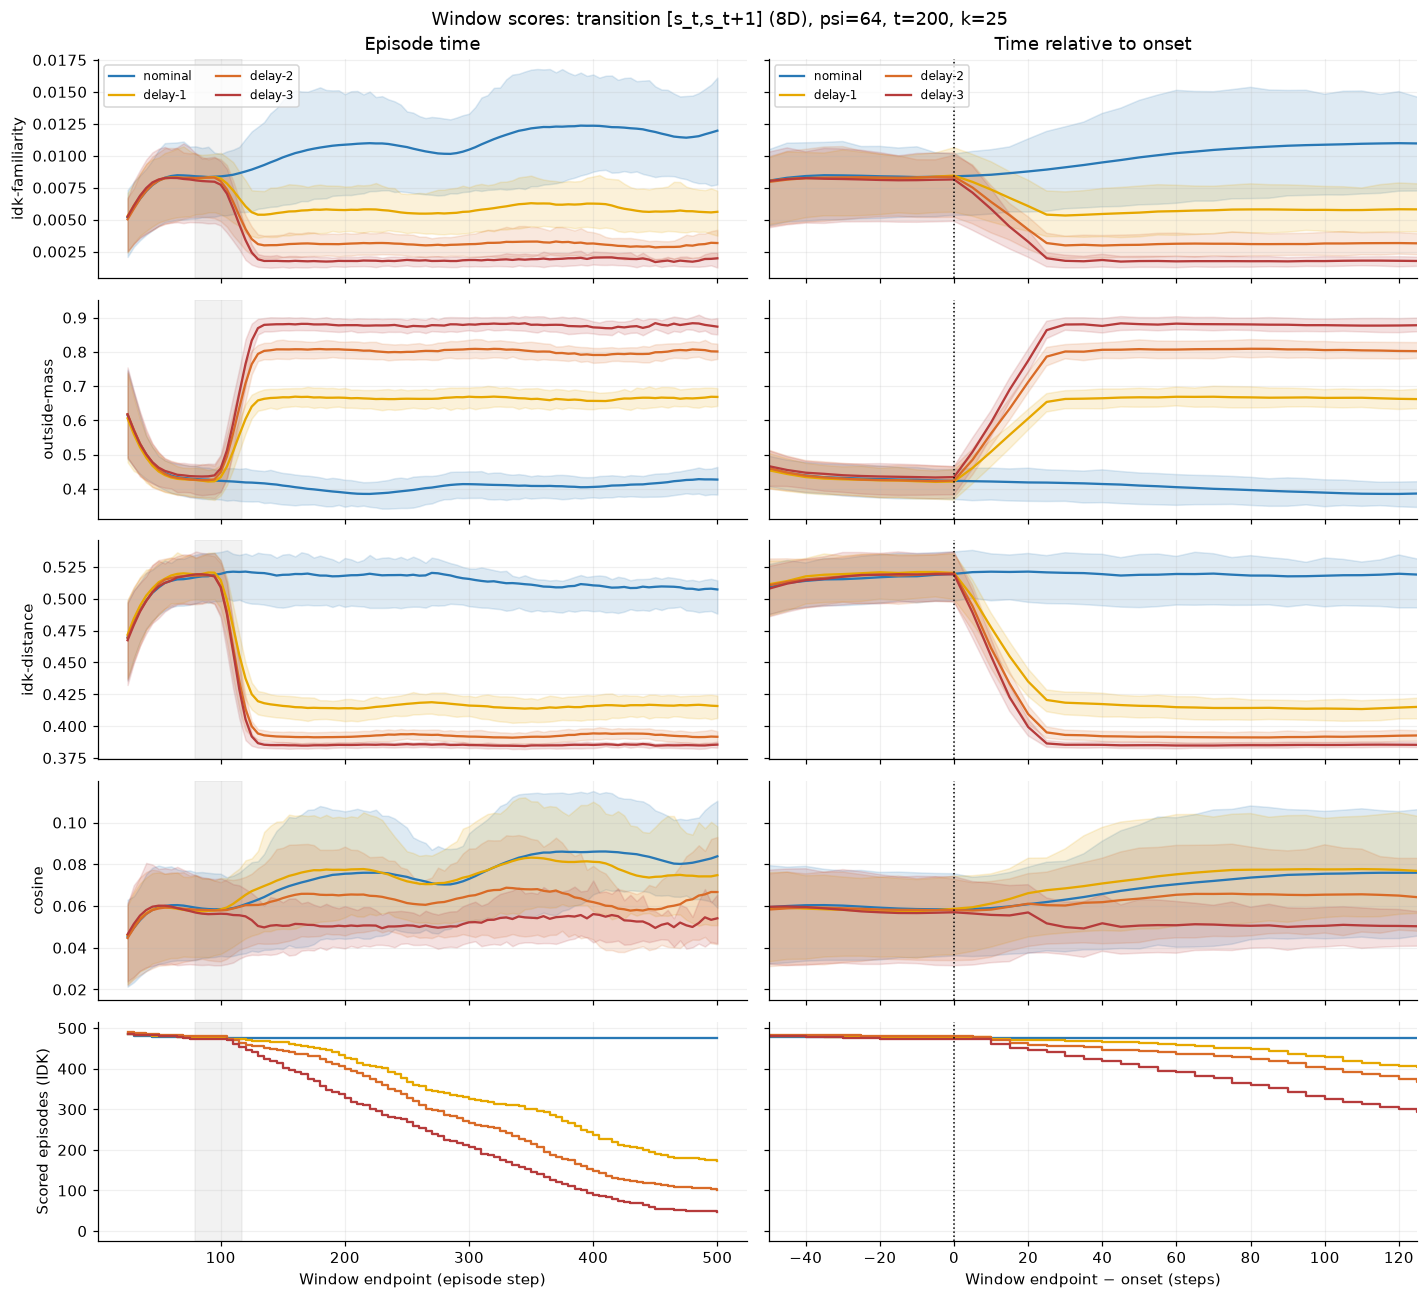

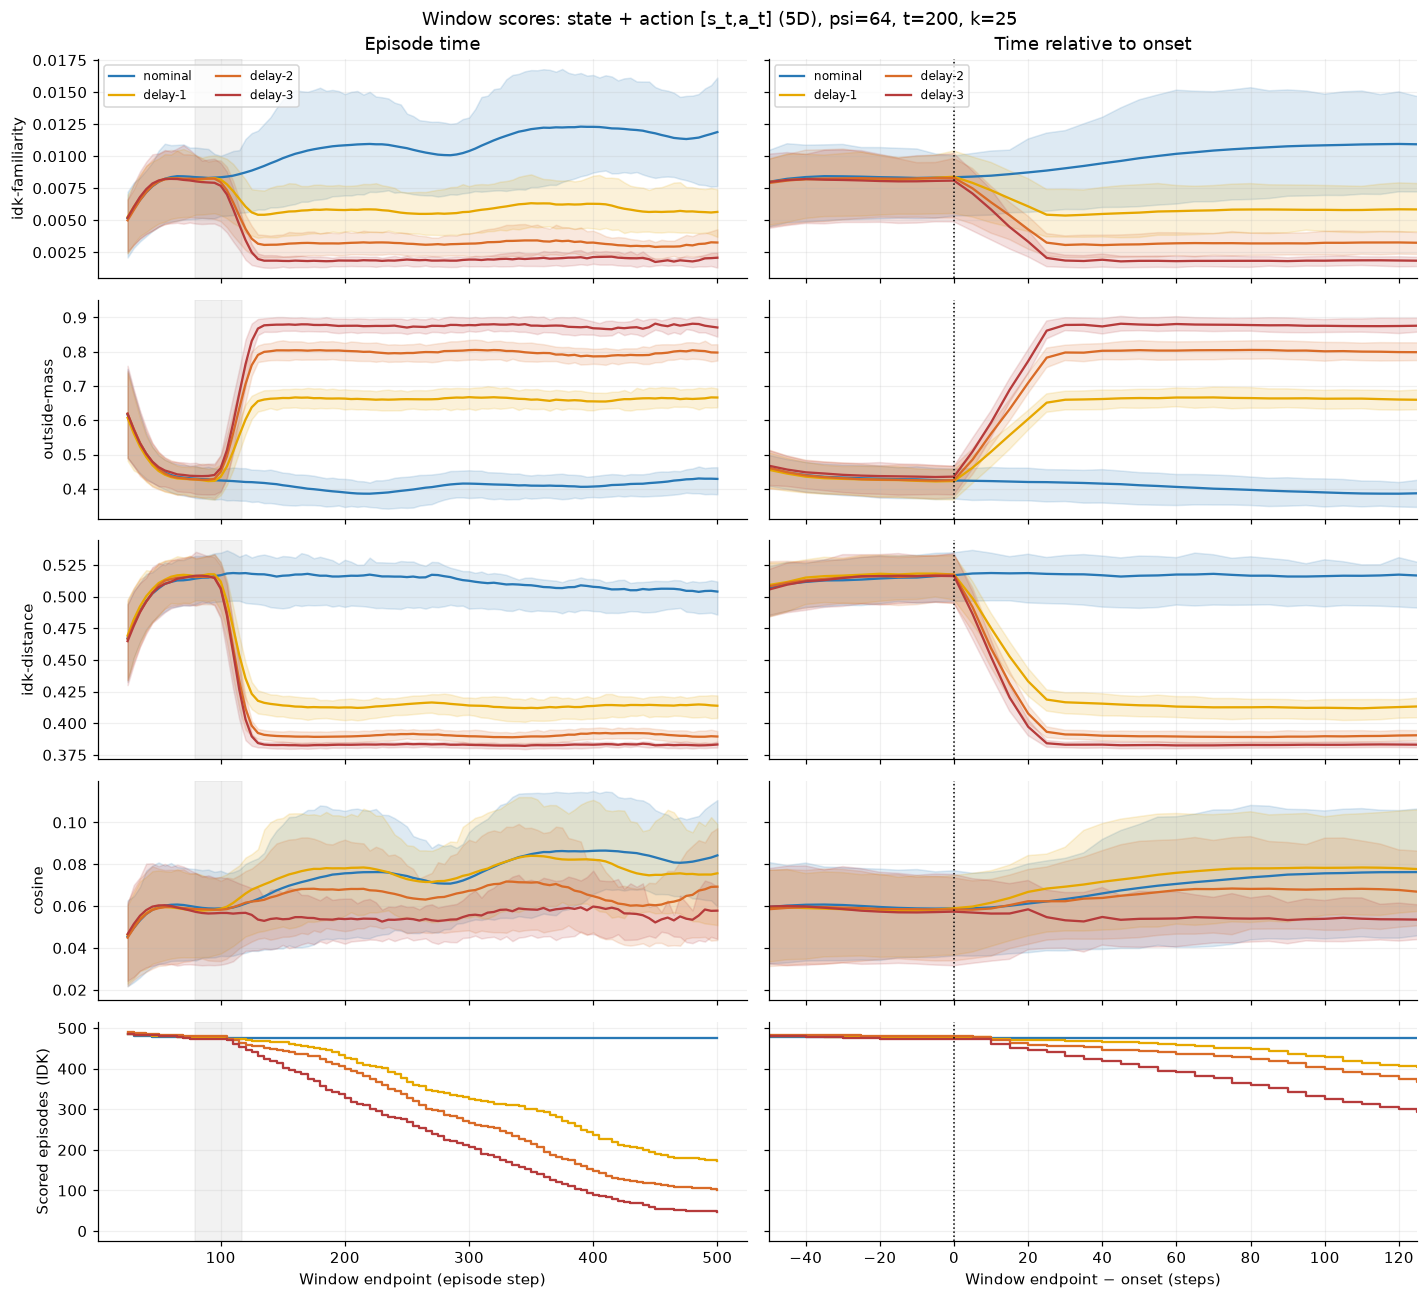

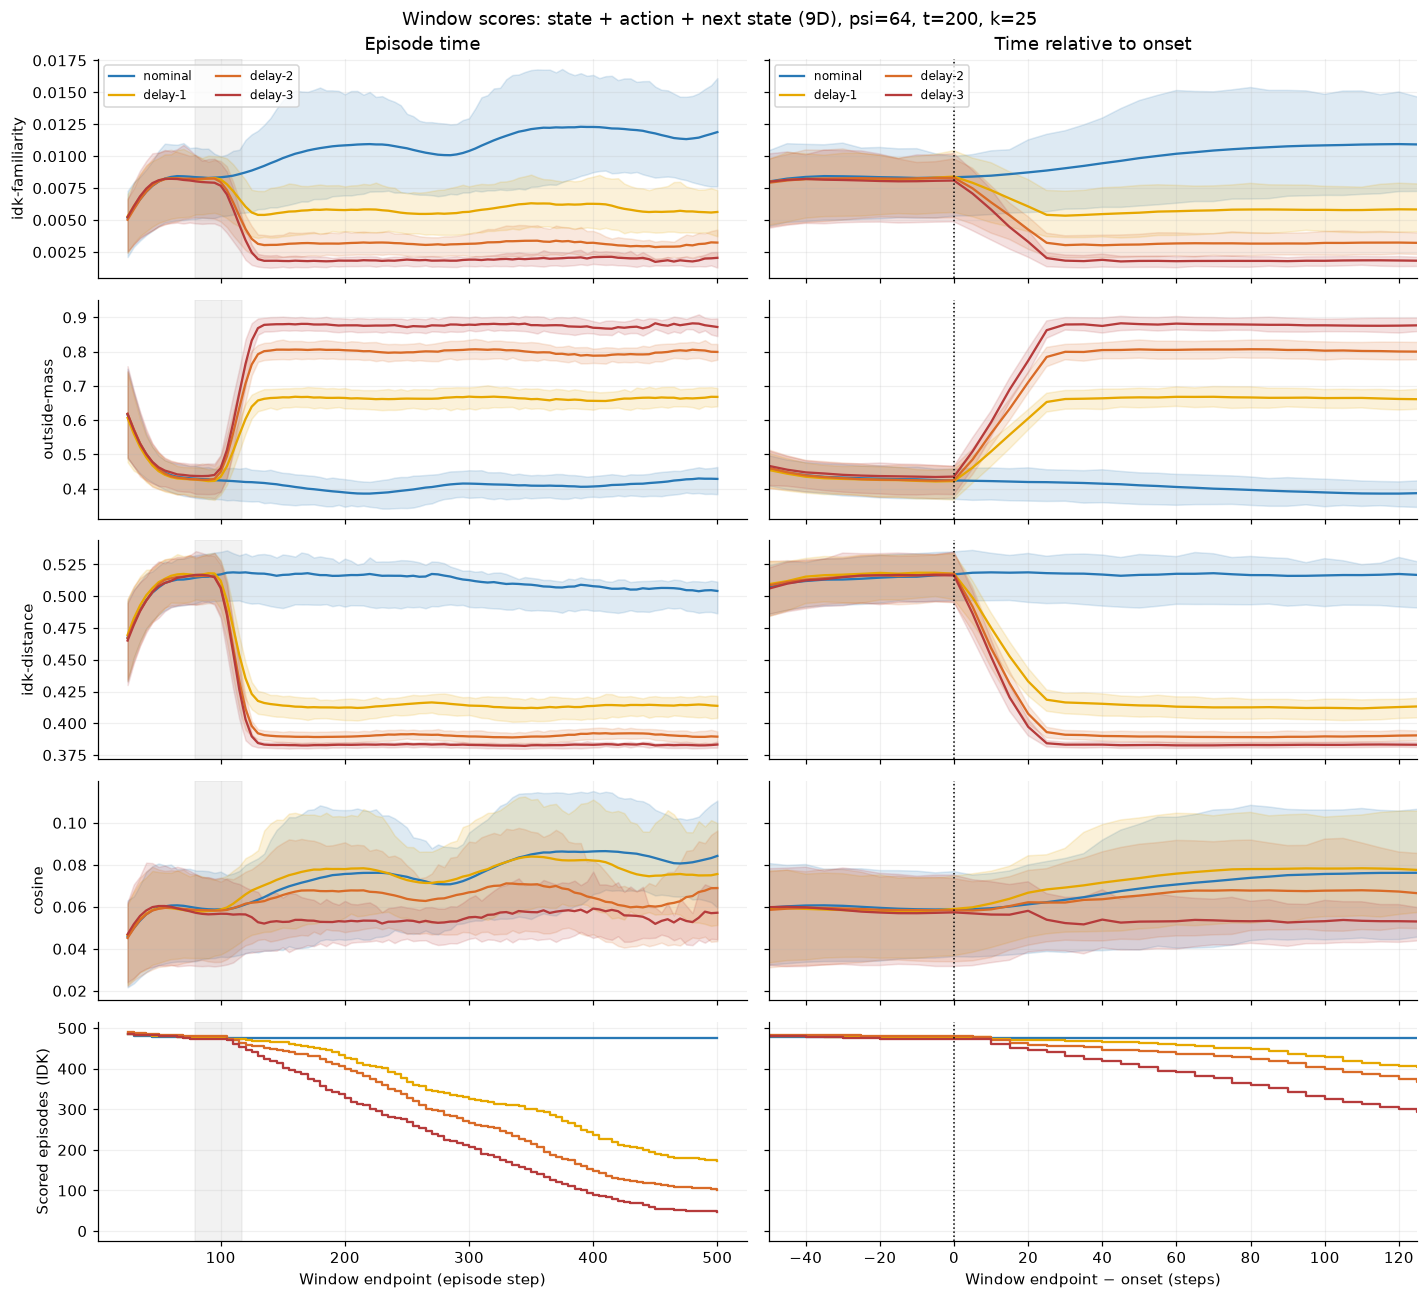

In [22]:
# Summarize cached window scores with means, episode IQRs, and contributing-episode counts.

CURVE_METRICS = ("idk-familiarity", "outside-mass", "idk-distance", "cosine")
RELATIVE_CURVE_LIMITS = (-50, 125)
curve_tables = {}
for coordinate in ("end_step", "relative_bin"):
    valid = focus_scores[focus_scores.metric.isin(CURVE_METRICS)].copy()
    valid = valid[np.isfinite(valid.score)]
    curve_tables[coordinate] = (
        valid.groupby(["representation", "population", "metric", coordinate], as_index=False)
        .agg(mean=("score", "mean"), median=("score", "median"),
             q25=("score", lambda x: x.quantile(.25)),
             q75=("score", lambda x: x.quantile(.75)),
             n=("episode_id", "nunique"))
    )
    curve_tables[coordinate].to_csv(CACHE / f"window_score_curves_{coordinate}.csv", index=False)
del valid
onset_range = episodes.loc[episodes.population.isin(DELAY_POPULATIONS), "onset"].agg(["min", "max"])

for rep in REPRESENTATIONS:
    fig, axes = plt.subplots(len(CURVE_METRICS) + 1, 2, figsize=(13, 12),
                             sharex="col", sharey="row", squeeze=False)
    for col, coordinate in enumerate(("end_step", "relative_bin")):
        for row, metric in enumerate(CURVE_METRICS):
            ax = axes[row, col]
            for population in EVALUATION_POPULATIONS:
                g = curve_tables[coordinate].query(
                    "representation == @rep and metric == @metric and population == @population"
                ).sort_values(coordinate)
                ax.plot(g[coordinate], g["mean"], color=COLORS[population], label=population)
                ax.fill_between(g[coordinate], g.q25, g.q75, color=COLORS[population], alpha=.15)
            if col == 0:
                ax.set_ylabel(metric)
        for population in EVALUATION_POPULATIONS:
            counts = curve_tables[coordinate].query(
                "representation == @rep and metric == 'idk-familiarity' and population == @population"
            ).sort_values(coordinate)
            axes[-1, col].step(counts[coordinate], counts.n, where="post",
                               color=COLORS[population], label=population)
        for ax in axes[:, col]:
            if coordinate == "end_step":
                ax.axvspan(onset_range["min"], onset_range["max"], color="gray", alpha=.1)
            else:
                ax.axvline(0, color="black", linestyle=":", linewidth=1)
                ax.set_xlim(*RELATIVE_CURVE_LIMITS)
        axes[0, col].legend(fontsize=8, ncol=2)
        axes[0, col].set_title("Episode time" if col == 0 else "Time relative to onset")
    axes[-1, 0].set(xlabel="Window endpoint (episode step)", ylabel="Scored episodes (IDK)")
    axes[-1, 1].set_xlabel("Window endpoint − onset (steps)")
    fig.suptitle(f"Window scores: {REP_LABELS[rep]}, psi={FOCUS_PSI}, t={FOCUS_T}, k={FOCUS_WINDOW}")
    figure_done(f"12_window_score_curves_{rep}")

**Findings.** Before onset, the population score curves largely overlap. After onset, familiarity falls, outside mass rises, and IDK distance falls. Delay-1 has the smallest response. Transition and both action representations show a larger mild-delay response than state; cosine remains broadly overlapping.

Early nominal windows also have low familiarity and high outside mass. This matters for thresholds calibrated over the entire episode. Later delayed curves describe fewer episodes as failures accumulate; all three delayed populations lose contributors.


[↑ Back to top](#notebook-top)

<a id="section-4"></a>

## 4. Onset-relative departure detection

For delayed episodes, time zero is the recorded delay onset. Nominal test episodes use step 100, the median scheduled onset, as a display and comparison anchor. Random starts mean this is not a shared physical phase. Reference windows still come from anywhere in the reference episodes.

Before onset, AUROC near 0.5 is a useful negative control. After onset, movement away from 0.5 indicates changed score ordering. Values below 0.5 indicate reversed ordering.

This analysis compares populations at each relative time. It does not set an alarm threshold or predict failure.


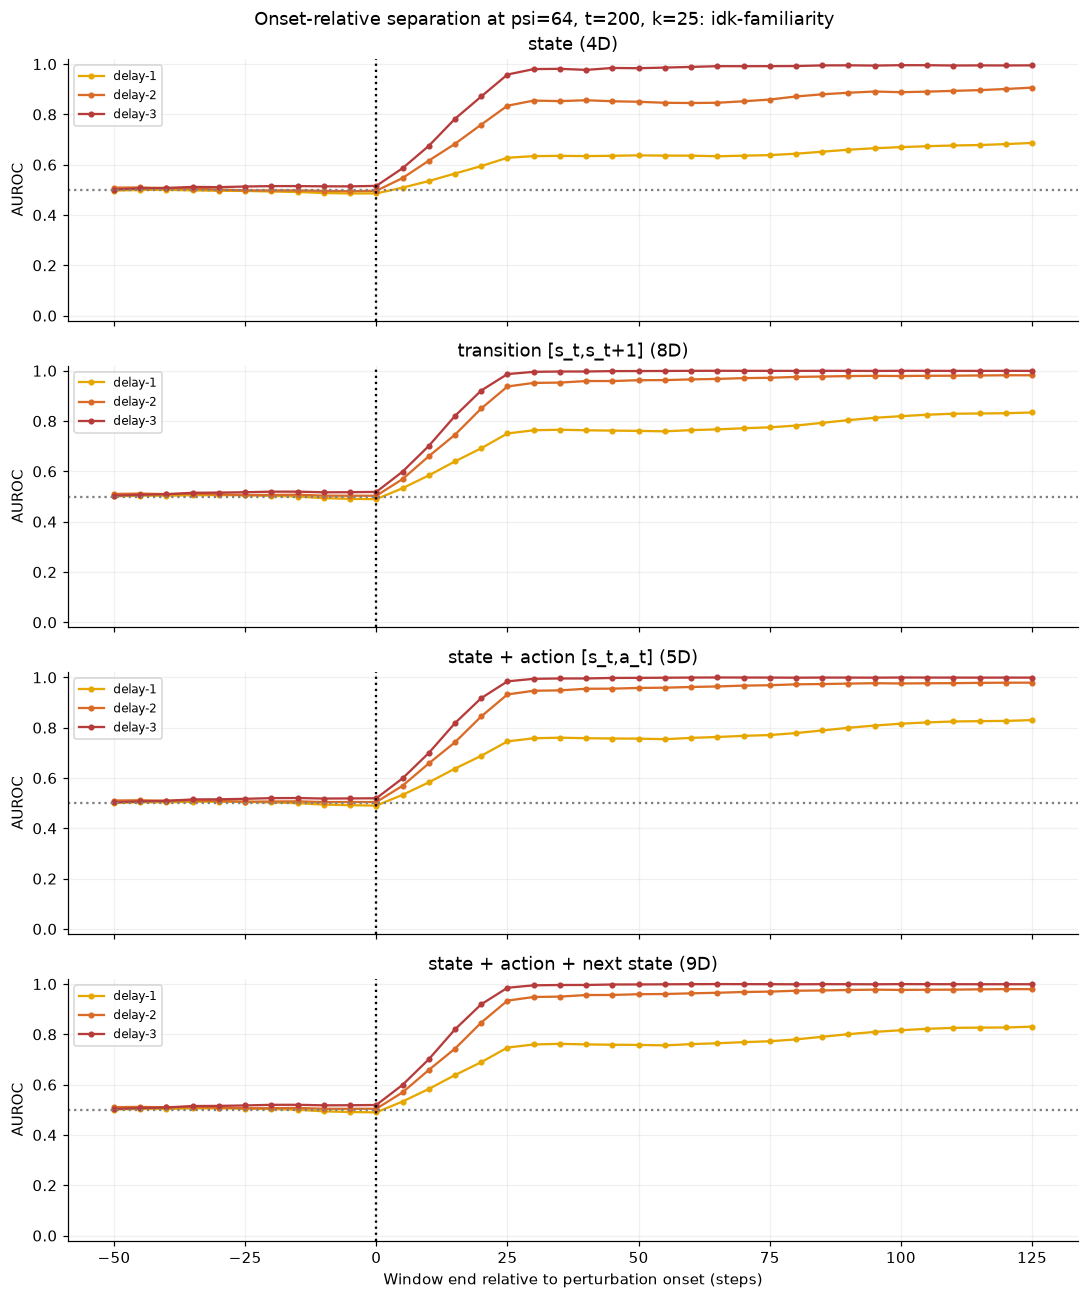

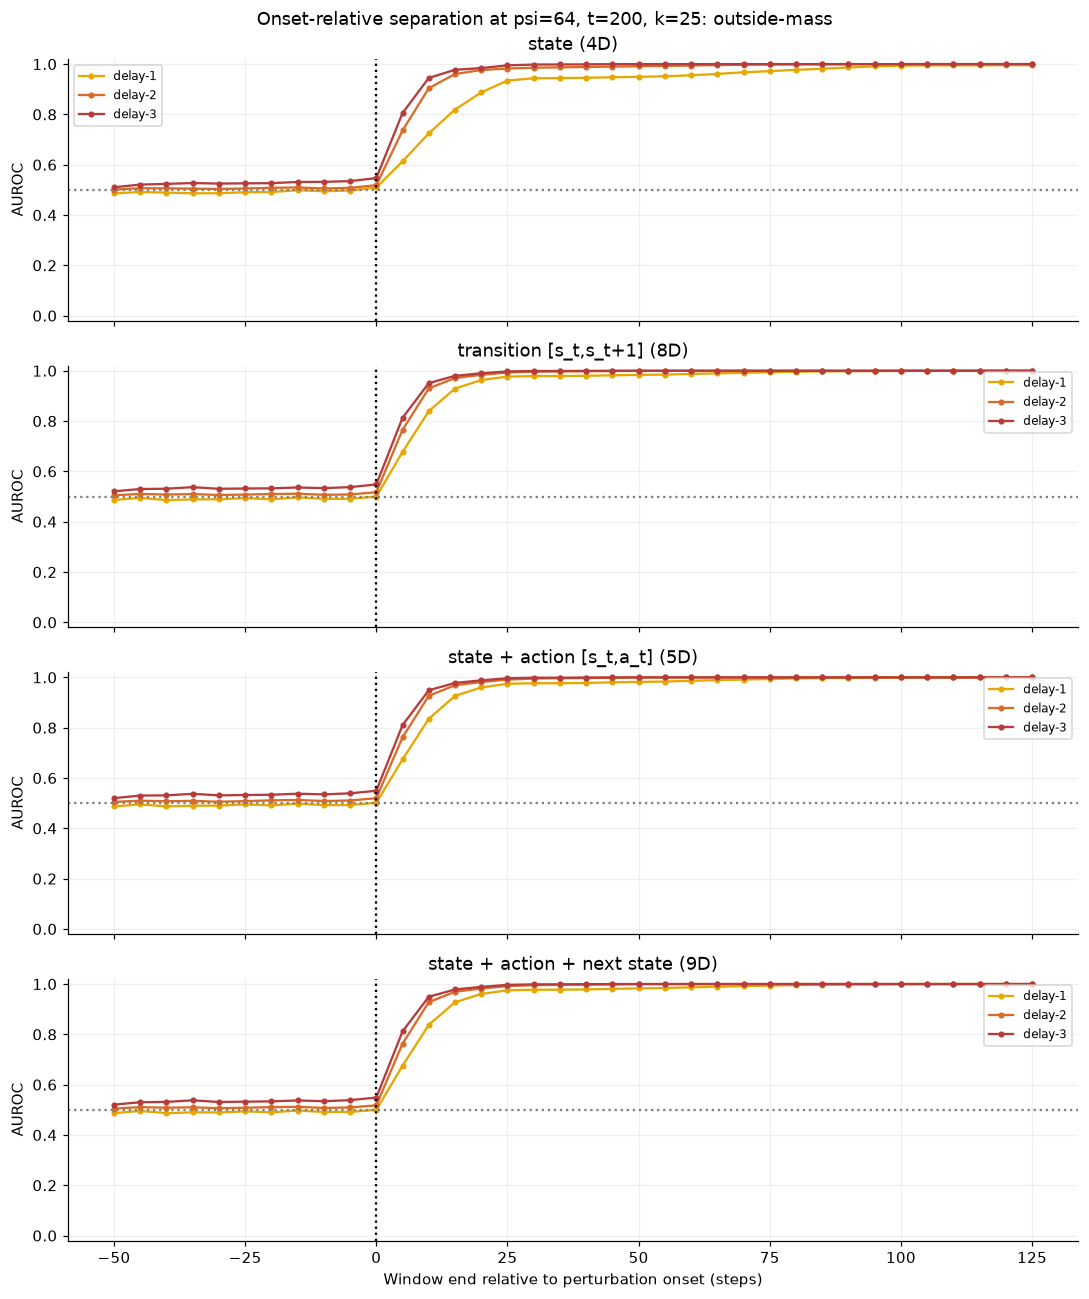

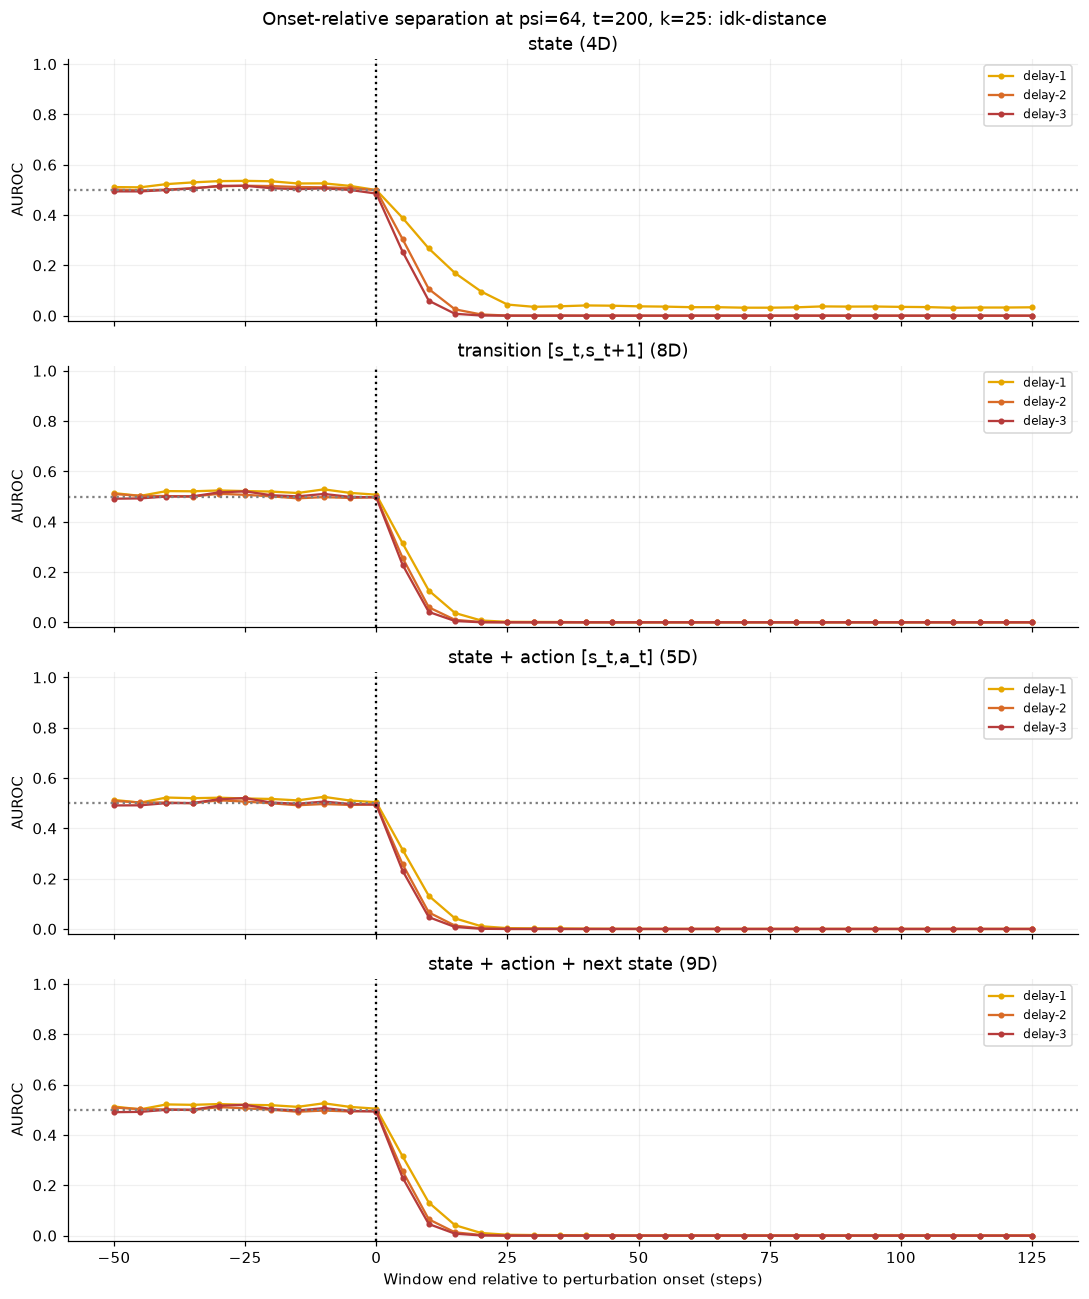

,representation,metric,relative_bin,delay_population,severity,n_nominal,n_delay,auroc
30,state,idk-familiarity,-25,delay-1,1,477,479,0.496
45,state,idk-familiarity,0,delay-1,1,476,479,0.486
60,state,idk-familiarity,25,delay-1,1,476,470,0.628
75,state,idk-familiarity,50,delay-1,1,476,464,0.637
31,state,idk-familiarity,-25,delay-2,2,477,481,0.498
...,...,...,...,...,...,...,...,...
2092,transition,outside-mass,50,delay-2,2,476,444,1.000
2048,transition,outside-mass,-25,delay-3,3,477,475,0.532
2063,transition,outside-mass,0,delay-3,3,476,474,0.548
2078,transition,outside-mass,25,delay-3,3,476,442,0.997


In [23]:
# Compute onset-relative AUROC curves at the focus psi/t/window.

onset_auc_rows = []

focus = focus_scores.query(
    "psi == @FOCUS_PSI and t == @FOCUS_T and window_length == @FOCUS_WINDOW "
    "and population in @EVALUATION_POPULATIONS"
)

for (rep, metric, relative_bin), group in focus.groupby(
    ["representation", "metric", "relative_bin"],
    sort=False,
):
    nominal = group[group.population == "nominal"]

    for delay_population in DELAY_POPULATIONS:
        delayed = group[group.population == delay_population]
        if len(nominal) < 10 or len(delayed) < 10:
            continue

        combined = pd.concat([nominal, delayed], ignore_index=True).dropna(subset=["anomaly"])
        labels = (combined.population == delay_population).astype(int)

        if labels.nunique() < 2:
            continue

        onset_auc_rows.append(
            {
                "representation": rep,
                "metric": metric,
                "relative_bin": int(relative_bin),
                "delay_population": delay_population,
                "severity": severity_of(delay_population),
                "n_nominal": len(nominal),
                "n_delay": len(delayed),
                "auroc": roc_auc_score(labels, combined.anomaly),
            }
        )

onset_auc = pd.DataFrame(onset_auc_rows)
onset_auc.to_csv(CACHE / "onset_relative_auroc.csv", index=False)

for metric in ("idk-familiarity", "outside-mass", "idk-distance"):
    fig, axes = plt.subplots(
        len(REPRESENTATIONS),
        1,
        figsize=(10, 3.0 * len(REPRESENTATIONS)),
        sharex=True,
        sharey=True,
    )
    if len(REPRESENTATIONS) == 1:
        axes = [axes]

    for ax, rep in zip(axes, REPRESENTATIONS):
        for delay_population in DELAY_POPULATIONS:
            g = onset_auc.query(
                "representation == @rep and metric == @metric "
                "and delay_population == @delay_population "
                "and -50 <= relative_bin <= 125"
            ).sort_values("relative_bin")
            ax.plot(
                g.relative_bin,
                g.auroc,
                marker="o",
                markersize=3,
                label=delay_population,
                color=COLORS[delay_population],
            )
        ax.axvline(0, linestyle=":", color="black")
        ax.axhline(0.5, linestyle=":", color="gray")
        ax.set(
            ylabel="AUROC",
            title=REP_LABELS[rep],
            ylim=(-0.02, 1.02),
        )
        ax.legend(fontsize=8)

    axes[-1].set_xlabel("Window end relative to perturbation onset (steps)")
    fig.suptitle(
        f"Onset-relative separation at psi={FOCUS_PSI}, t={FOCUS_T}, "
        f"k={FOCUS_WINDOW}: {metric}"
    )
    figure_done(f"04_onset_relative_{metric.replace('-', '_')}")

display(
    onset_auc.query(
        "metric in ['idk-familiarity', 'outside-mass'] and relative_bin in [-25, 0, 25, 50]"
    )
    .sort_values(["representation", "metric", "severity", "relative_bin"])
    .round(3)
)


### Findings: onset-relative separation

At $\psi=64$, $t=200$, $k=25$:

- Pre-onset AUROC stays close to 0.5, supporting the negative control.
- At +25 steps, familiarity AUROC is about 0.63/0.83/0.96 for delay-1/2/3 in state. The other representations give about 0.75/0.93–0.94/0.98–0.99.
- Outside-mass AUROC reaches roughly 0.94–1.00 by +25 steps. Mild delay separates more slowly than stronger delays.
- Distance AUROC falls almost to zero after onset. Delayed windows have smaller distances; the score still separates populations, with reversed ordering.

Delay-3 contributes 442 episodes at +25 steps and 325 at +100. Later separation describes the episodes still observed, not all 500.


[↑ Back to top](#notebook-top)

<a id="section-5"></a>

## 5. How much **post-onset experience** is needed?

Window length affects two different things:

- **Representation sample efficiency:** how much perturbed experience is needed before the representation distinguishes it from nominal?
- **Online alarm latency:** how long the detector must wait before a full window and persistence rule can fire.

To isolate the first question, this section uses the **first fully post-onset window** of length $k$ from each delayed episode and compares it with the first nominal window starting at or after step 100.

Window starts lie on the 5-step scoring grid, so they can be up to four steps after onset. Thus $k=50$ means approximately "after observing 50 perturbed transitions, how separable is the experience?" It does **not** include the extra persistence delay of the online alarm.

The analysis also reports coverage, because short failed episodes may terminate before a long post-onset window exists.


Episodes ending before scheduled onset provide no post-onset window. They remain in the population count used to calculate coverage.


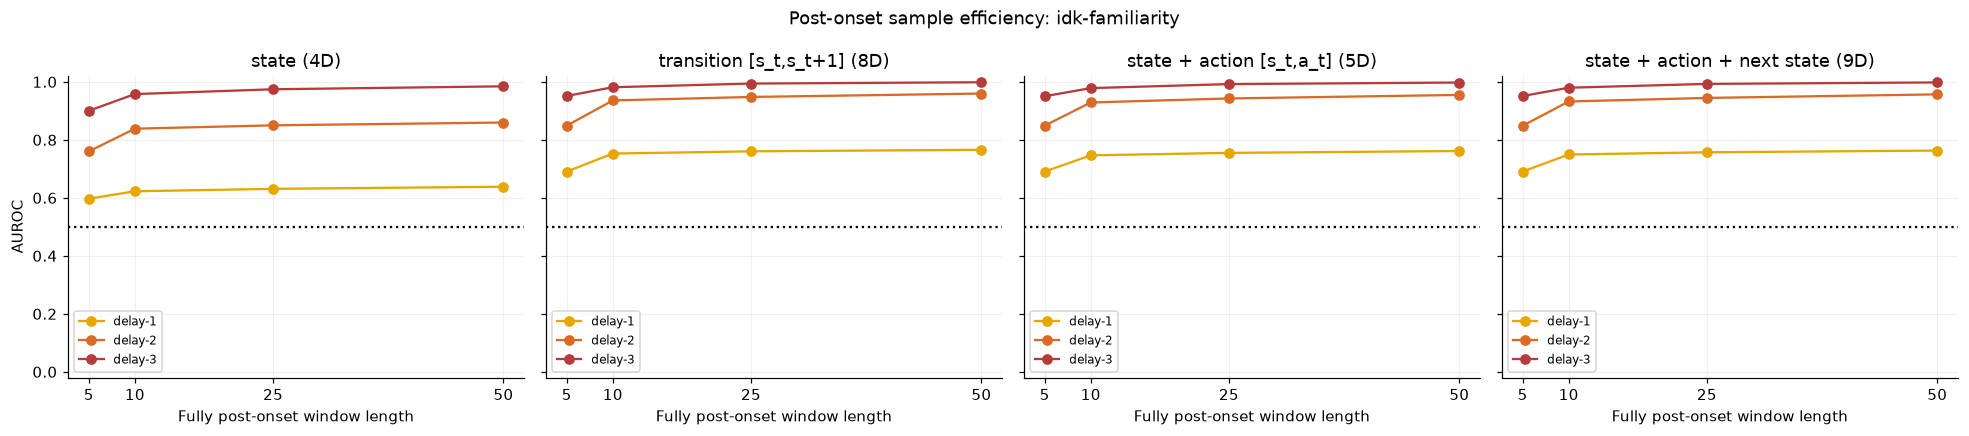

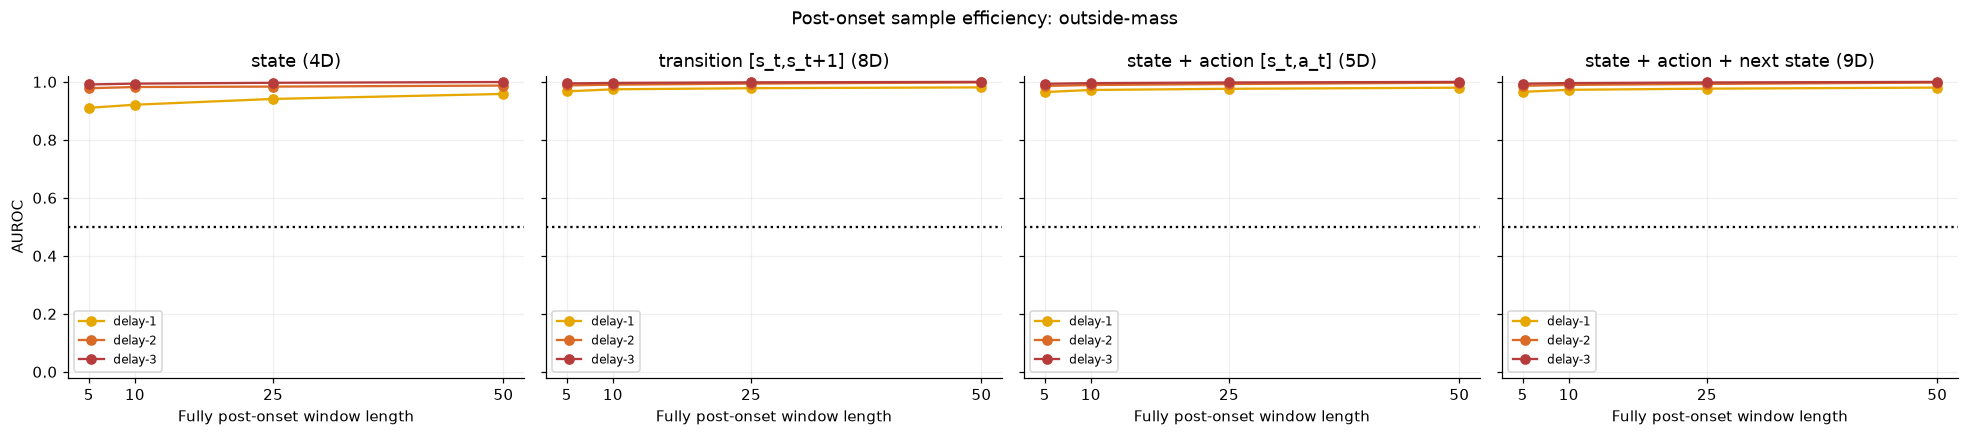

,representation,psi,t,window_length,metric,delay_population,severity,auroc,n_nominal,n_delay,delay_coverage,median_delay_window_start_after_onset
180,state,64,200,5,idk-familiarity,delay-1,1,0.597,476,475,0.950,2.0
195,state,64,200,10,idk-familiarity,delay-1,1,0.623,476,472,0.944,2.0
210,state,64,200,25,idk-familiarity,delay-1,1,0.631,476,469,0.938,2.0
225,state,64,200,50,idk-familiarity,delay-1,1,0.638,476,464,0.928,2.0
181,state,64,200,5,idk-familiarity,delay-2,2,0.760,476,475,0.950,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...
652,transition,64,200,50,outside-mass,delay-2,2,0.998,476,442,0.884,2.0
608,transition,64,200,5,outside-mass,delay-3,3,0.995,476,470,0.940,2.0
623,transition,64,200,10,outside-mass,delay-3,3,0.996,476,457,0.914,2.0
638,transition,64,200,25,outside-mass,delay-3,3,0.998,476,439,0.878,2.0


In [24]:
# Post-onset sample-efficiency analysis.

def first_window_after(group: pd.DataFrame, start_threshold) -> pd.DataFrame:
    eligible = group[group.start_step >= start_threshold].sort_values(["episode_id", "end_step"])
    return eligible.groupby("episode_id", as_index=False).head(1)


post_onset_rows = []
episode_counts = episodes.groupby("population").size().to_dict()

for (rep, psi, t, k, metric), group in iter_window_groups(populations=EVALUATION_POPULATIONS):
    nominal = group[group.population == "nominal"]
    nominal_first = first_window_after(nominal, NOMINAL_ALIGNMENT_ONSET)

    for delay_population in DELAY_POPULATIONS:
        delayed = group[group.population == delay_population].copy()
        delayed["actual_onset"] = delayed.episode_id.map(
            episodes.query("population == @delay_population")
            .set_index("trajectory_id")
            .onset
        )
        delayed_eligible = delayed[delayed.start_step >= delayed.actual_onset]
        delayed_first = (
            delayed_eligible.sort_values(["episode_id", "end_step"])
            .groupby("episode_id", as_index=False)
            .head(1)
        )

        if len(nominal_first) < 2 or len(delayed_first) < 2:
            continue

        combined = pd.concat(
            [
                nominal_first.assign(_label=0),
                delayed_first.assign(_label=1),
            ],
            ignore_index=True,
        ).dropna(subset=["anomaly"])

        if combined._label.nunique() < 2:
            continue

        post_onset_rows.append(
            {
                "representation": rep,
                "psi": psi,
                "t": t,
                "window_length": k,
                "metric": metric,
                "delay_population": delay_population,
                "severity": severity_of(delay_population),
                "auroc": roc_auc_score(combined._label, combined.anomaly),
                "n_nominal": len(nominal_first),
                "n_delay": len(delayed_first),
                "delay_coverage": len(delayed_first) / episode_counts[delay_population],
                "median_delay_window_start_after_onset": float(
                    np.median(delayed_first.start_step - delayed_first.actual_onset)
                ),
            }
        )

post_onset = pd.DataFrame(post_onset_rows)
post_onset.to_csv(CACHE / "post_onset_sample_efficiency.csv", index=False)

for metric in ("idk-familiarity", "outside-mass"):
    fig, axes = plt.subplots(
        1,
        len(REPRESENTATIONS),
        figsize=(4.5 * len(REPRESENTATIONS), 4),
        sharey=True,
    )
    if len(REPRESENTATIONS) == 1:
        axes = [axes]

    for ax, rep in zip(axes, REPRESENTATIONS):
        for delay_population in DELAY_POPULATIONS:
            g = post_onset.query(
                "representation == @rep and psi == @FOCUS_PSI and t == @FOCUS_T "
                "and metric == @metric and delay_population == @delay_population"
            ).sort_values("window_length")
            ax.plot(
                g.window_length,
                g.auroc,
                marker="o",
                label=delay_population,
                color=COLORS[delay_population],
            )
        ax.axhline(0.5, linestyle=":", color="black")
        ax.set(
            title=REP_LABELS[rep],
            xlabel="Fully post-onset window length",
            ylabel="AUROC" if ax is axes[0] else None,
            ylim=(-0.02, 1.02),
        )
        ax.set_xticks(WINDOW_SIZES)
        ax.legend(fontsize=8)

    fig.suptitle(f"Post-onset sample efficiency: {metric}")
    figure_done(f"05_post_onset_sample_efficiency_{metric.replace('-', '_')}")

display(
    post_onset.query(
        "psi == @FOCUS_PSI and t == @FOCUS_T "
        "and metric in ['idk-familiarity', 'outside-mass']"
    )
    .sort_values(["representation", "metric", "severity", "window_length"])
    .round(3)
)


### Findings: amount of post-onset history

- Five post-onset steps give outside-mass AUROC of about 0.91–1.00. For mild delay, transition and action representations start near 0.97, versus 0.91 for state.
- Familiarity needs more history. Delay-1 AUROC rises from 0.60 to 0.64 for state and from 0.69 to about 0.76 for the other representations as $k$ grows from 5 to 50. Most improvement occurs by $k=10$.
- Delay-2/3 separate more strongly. At $k=50$, familiarity AUROC is about 0.96/1.00 outside the state representation.
- Coverage declines with history. Delay-1/2/3 coverage is 95%/95%/94% at $k=5$ and 92.8%/88.4%/80.4% at $k=50$.

Longer-window results exclude more early failures. High post-onset AUROC alone does not establish a useful online alarm.


[↑ Back to top](#notebook-top)

<a id="section-6"></a>

## 6. Nominal-calibrated online alarms

Alarm thresholds are calibrated **only** on the independent nominal calibration population.

For each episode and metric:

1. compute the anomaly score on each sliding window;
2. require `PERSISTENCE` consecutive windows above threshold;
3. summarize the maximum sustained anomaly per calibration episode;
4. choose a threshold targeting a per-episode nominal false-alarm probability of `ALPHA`.

The same threshold is then applied without refitting to:

- held-out nominal test episodes;
- delay-1;
- delay-2;
- delay-3.

For delayed episodes, a timely departure detection must occur **after perturbation onset and before episode termination**.

A recovered delayed episode can legitimately trigger a departure alarm; that is not a nominal false positive. Whether departure predicts eventual failure is analyzed separately.


### Threshold and timing definitions

Let $a_i(e)$ be the anomaly-oriented score for episode $i$ at window endpoint $e$. Familiarity and cosine are negated; distance and outside mass retain their signs. For stride $s$ and persistence $h$, define

$$b_i(e)=\min_{r=0,\ldots,h-1}a_i(e-rs),\qquad A_i=\max_e b_i(e).$$

For $n$ nominal calibration episodes with at least one complete scored window, sort their $A_i$ values and use rank $r=\lceil(n+1)(1-\alpha)\rceil$ as the threshold $\tau$. At $k=25$, $n=488$, $\alpha=0.10$, and $r=441$. The count changes with window size. Episodes with scores but fewer than three consecutive windows receive $A_i=-\infty$; episodes without any score are omitted from calibration. If the rank exceeds $n$, use $\tau=+\infty$. An alarm requires **strict** exceedance, $b_i(e)>\tau$. The target is a per-episode nominal false-alarm rate and assumes future nominal episodes follow the calibration distribution.

- **First alarm:** the first scored endpoint satisfying the persistence rule.
- **Timely detection:** that first alarm is after onset and strictly before episode end.
- **Pre-onset alarm:** the first alarm is at or before onset. Later crossings do not reclassify that episode as a timely detection.
- **Nominal false alarm:** any first alarm in a nominal evaluation episode.
- **Latency:** steps from onset to a timely alarm.
- **Lead time:** steps from a timely alarm to episode end. For surviving episodes, this ends at the 500-step cutoff, not at failure.

Latency and lead-time summaries include detected episodes only. Detection fractions include all evaluation episodes, including those too short to raise an alarm or ending before scheduled delay onset. Such episodes cannot have a timely post-onset detection; the population label records the scheduled intervention.

Only complete windows are scored. The earliest possible alarm endpoint is $k+(h-1)s$ **from episode start**. With $k=25$, $h=3$, and $s=5$, this is step 35. It is not a minimum delay after perturbation onset: online windows can straddle onset. Overlapping windows also mean consecutive scores are dependent.


In [25]:
# Calibrate and evaluate persistent online alarms.

def sustained_trace(group: pd.DataFrame):
    ordered = group.sort_values("end_step")
    trace = ordered.anomaly.rolling(PERSISTENCE, min_periods=PERSISTENCE).min()
    return ordered, trace


def calibration_threshold(group: pd.DataFrame) -> float:
    maxima = []

    for episode_id, values in group.groupby("episode_id"):
        _, trace = sustained_trace(values)
        maxima.append(trace.max() if trace.notna().any() else -np.inf)

    if not maxima:
        return np.inf

    rank = int(np.ceil((len(maxima) + 1) * (1 - ALPHA)))
    return float(np.sort(maxima)[rank - 1]) if rank <= len(maxima) else np.inf


def calibrate_and_detect() -> pd.DataFrame:
    rows = []
    keys = ["representation", "psi", "t", "window_length", "metric"]

    for key, group in iter_window_groups(metrics=ALARM_METRICS):
        identity = dict(zip(keys, key))

        calibration = group[group.population == "calibration"]
        threshold = calibration_threshold(calibration)

        for population in EVALUATION_POPULATIONS:
            population_episodes = episodes.query("population == @population")
            by_episode = {
                episode_id: values
                for episode_id, values in group[group.population == population].groupby("episode_id")
            }

            for episode in population_episodes.itertuples(index=False):
                values = by_episode.get(episode.trajectory_id, group.iloc[:0])
                ordered, trace = sustained_trace(values)

                endpoints = ordered.loc[trace > threshold, "end_step"]
                first_alarm = float(endpoints.iloc[0]) if len(endpoints) else np.nan

                if population in DELAY_POPULATIONS:
                    pre_onset = np.isfinite(first_alarm) and first_alarm <= episode.onset
                    timely = (
                        np.isfinite(first_alarm)
                        and episode.onset < first_alarm < episode.length
                    )
                    latency = first_alarm - episode.onset if timely else np.nan
                    lead_time = episode.length - first_alarm if timely else np.nan
                else:
                    pre_onset = False
                    timely = False
                    latency = np.nan
                    lead_time = np.nan

                rows.append(
                    {
                        **identity,
                        "population": population,
                        "severity": severity_of(population),
                        "episode_id": episode.trajectory_id,
                        "length": episode.length,
                        "onset": episode.onset,
                        "survived_500": episode.survived_500,
                        "failure": episode.failure,
                        "threshold": threshold,
                        "first_alarm": first_alarm,
                        "has_score": len(values) > 0,
                        "can_alarm": bool(trace.notna().any()),
                        "alarm": np.isfinite(first_alarm),
                        "pre_onset_alarm": pre_onset,
                        "timely_detection": timely,
                        "latency": latency,
                        "lead_time": lead_time,
                    }
                )

    return pd.DataFrame(rows)


alarm_episodes = calibrate_and_detect()


def wilson_interval(successes: int, total: int):
    if total == 0:
        return np.nan, np.nan
    z = 1.959963984540054
    rate = successes / total
    scale = 1 + z * z / total
    center = (rate + z * z / (2 * total)) / scale
    radius = (
        z
        * np.sqrt(rate * (1 - rate) / total + z * z / (4 * total * total))
        / scale
    )
    return center - radius, center + radius


summary_rows = []
keys = ["representation", "psi", "t", "window_length", "metric"]

for key, group in alarm_episodes.groupby(keys, sort=False):
    nominal = group[group.population == "nominal"]

    fpr_low, fpr_high = wilson_interval(int(nominal.alarm.sum()), len(nominal))

    for delay_population in DELAY_POPULATIONS:
        delayed = group[group.population == delay_population]
        det_low, det_high = wilson_interval(
            int(delayed.timely_detection.sum()),
            len(delayed),
        )

        failures = delayed[delayed.failure.astype(bool)]
        recoveries = delayed[~delayed.failure.astype(bool)]

        summary_rows.append(
            {
                **dict(zip(keys, key)),
                "delay_population": delay_population,
                "severity": severity_of(delay_population),
                "nominal_fpr": nominal.alarm.mean(),
                "nominal_fpr_low": fpr_low,
                "nominal_fpr_high": fpr_high,
                "timely_detection_rate": delayed.timely_detection.mean(),
                "detection_low": det_low,
                "detection_high": det_high,
                "pre_onset_alarm_rate": delayed.pre_onset_alarm.mean(),
                "unscorable_fraction": 1 - delayed.can_alarm.mean(),
                "median_latency": delayed.latency.median(),
                "median_lead_time": delayed.lead_time.median(),
                "failure_rate": delayed.failure.mean(),
                "failure_detection_rate": (
                    failures.timely_detection.mean() if len(failures) else np.nan
                ),
                "recovered_departure_detection_rate": (
                    recoveries.timely_detection.mean() if len(recoveries) else np.nan
                ),
                "n_nominal": len(nominal),
                "n_delay": len(delayed),
            }
        )

alarm_summary = pd.DataFrame(summary_rows)
alarm_episodes.to_parquet(CACHE / "alarm_episodes.parquet", index=False)
alarm_summary.to_csv(CACHE / "alarm_summary.csv", index=False)

display(
    alarm_summary.query(
        "psi == @FOCUS_PSI and t == @FOCUS_T and window_length == @FOCUS_WINDOW"
    )
    .sort_values(["representation", "metric", "severity"])
    .round(3)
)


,representation,psi,t,window_length,metric,delay_population,severity,nominal_fpr,nominal_fpr_low,nominal_fpr_high,...,detection_high,pre_onset_alarm_rate,unscorable_fraction,median_latency,median_lead_time,failure_rate,failure_detection_rate,recovered_departure_detection_rate,n_nominal,n_delay
177,state,64,200,25,cosine,delay-1,1,0.096,0.073,0.125,...,0.011,0.068,0.036,3.0,390.0,0.654,0.003,0.000,500,500
178,state,64,200,25,cosine,delay-2,2,0.096,0.073,0.125,...,0.014,0.082,0.026,6.0,343.0,0.798,0.003,0.010,500,500
179,state,64,200,25,cosine,delay-3,3,0.096,0.073,0.125,...,0.011,0.076,0.036,1.0,400.0,0.908,0.000,0.022,500,500
171,state,64,200,25,idk-distance,delay-1,1,0.100,0.077,0.129,...,0.008,0.016,0.036,NaN,NaN,0.654,0.000,0.000,500,500
172,state,64,200,25,idk-distance,delay-2,2,0.100,0.077,0.129,...,0.008,0.012,0.026,NaN,NaN,0.798,0.000,0.000,500,500
173,state,64,200,25,idk-distance,delay-3,3,0.100,0.077,0.129,...,0.008,0.002,0.036,NaN,NaN,0.908,0.000,0.000,500,500
168,state,64,200,25,idk-familiarity,delay-1,1,0.104,0.080,0.134,...,0.020,0.094,0.036,171.0,230.0,0.654,0.000,0.023,500,500
169,state,64,200,25,idk-familiarity,delay-2,2,0.104,0.080,0.134,...,0.222,0.084,0.026,51.0,315.0,0.798,0.100,0.525,500,500
170,state,64,200,25,idk-familiarity,delay-3,3,0.104,0.080,0.134,...,0.611,0.086,0.036,41.0,109.5,0.908,0.542,0.826,500,500
174,state,64,200,25,outside-mass,delay-1,1,0.088,0.066,0.116,...,0.039,0.070,0.036,171.0,100.0,0.654,0.034,0.000,500,500


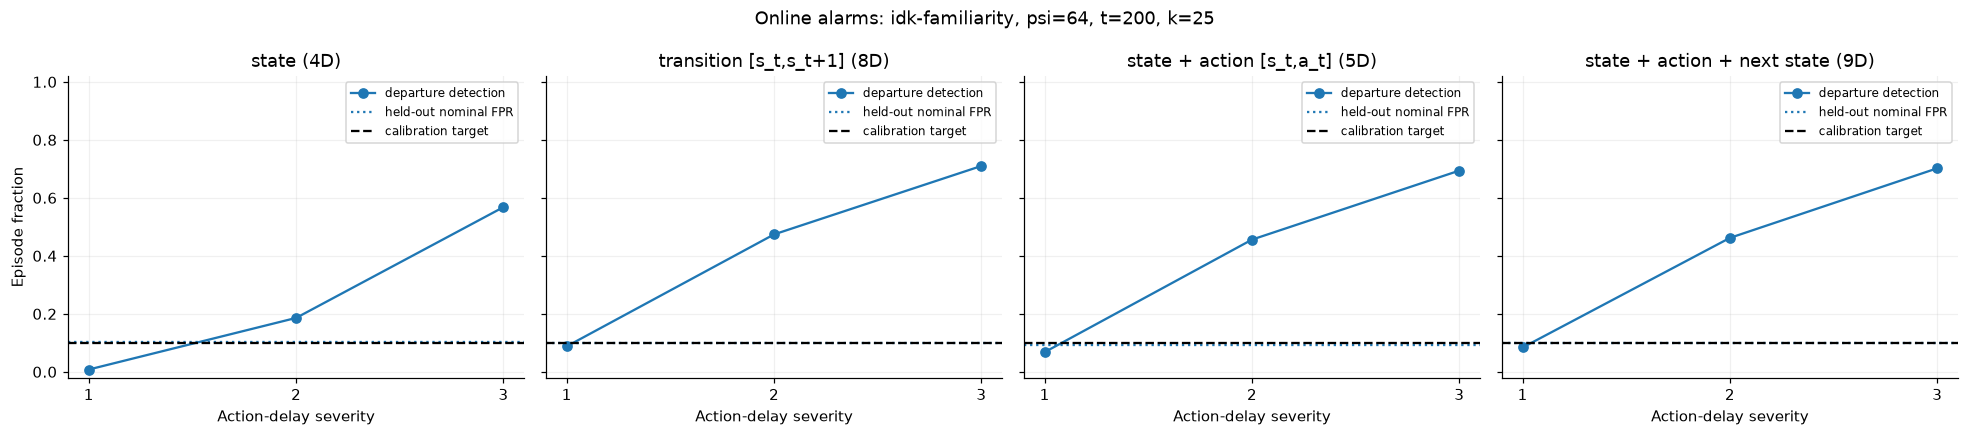

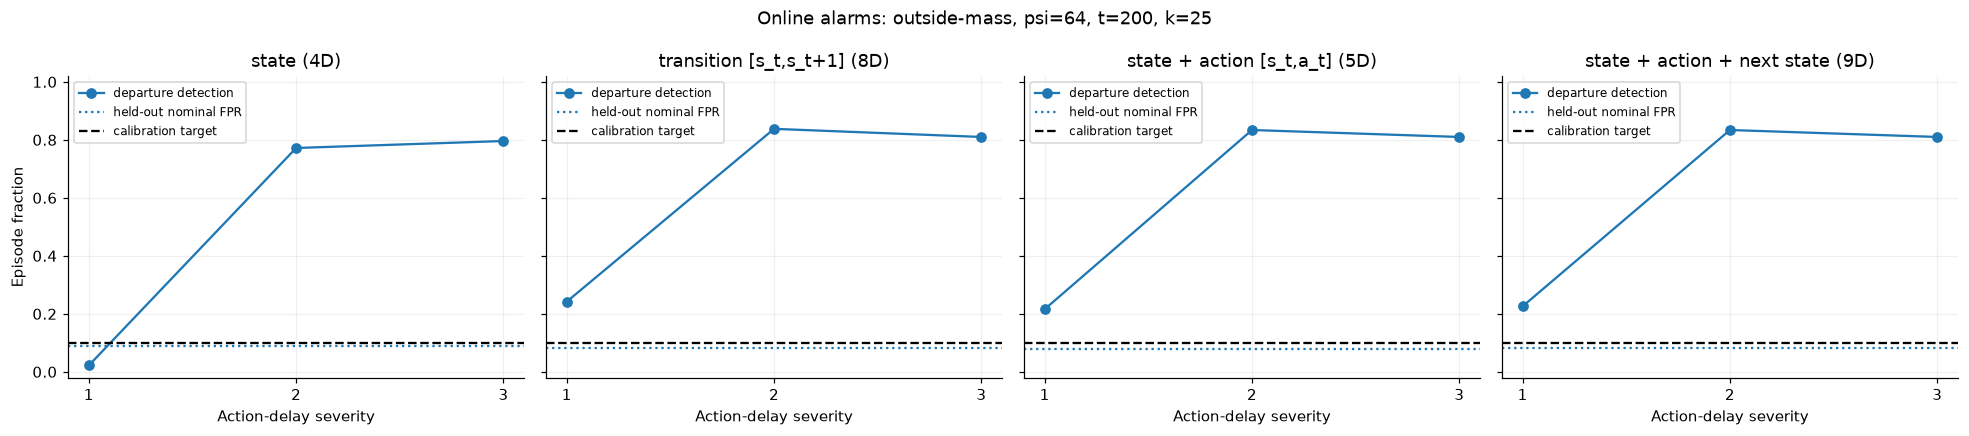

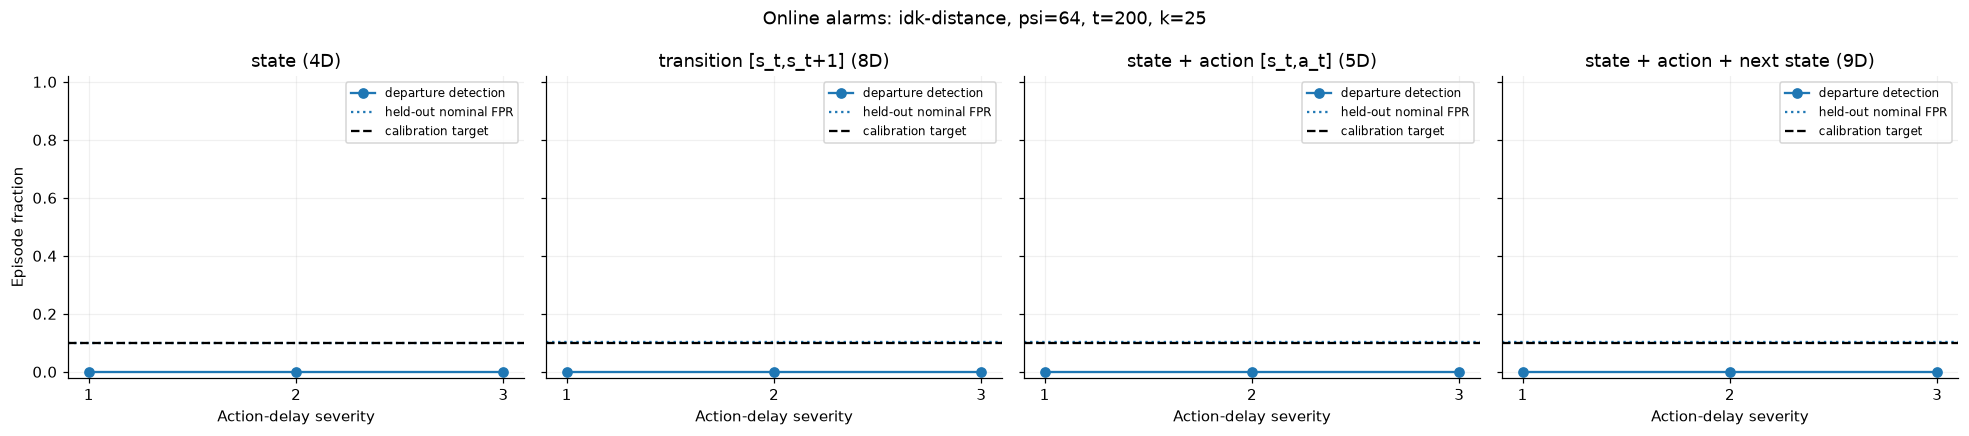

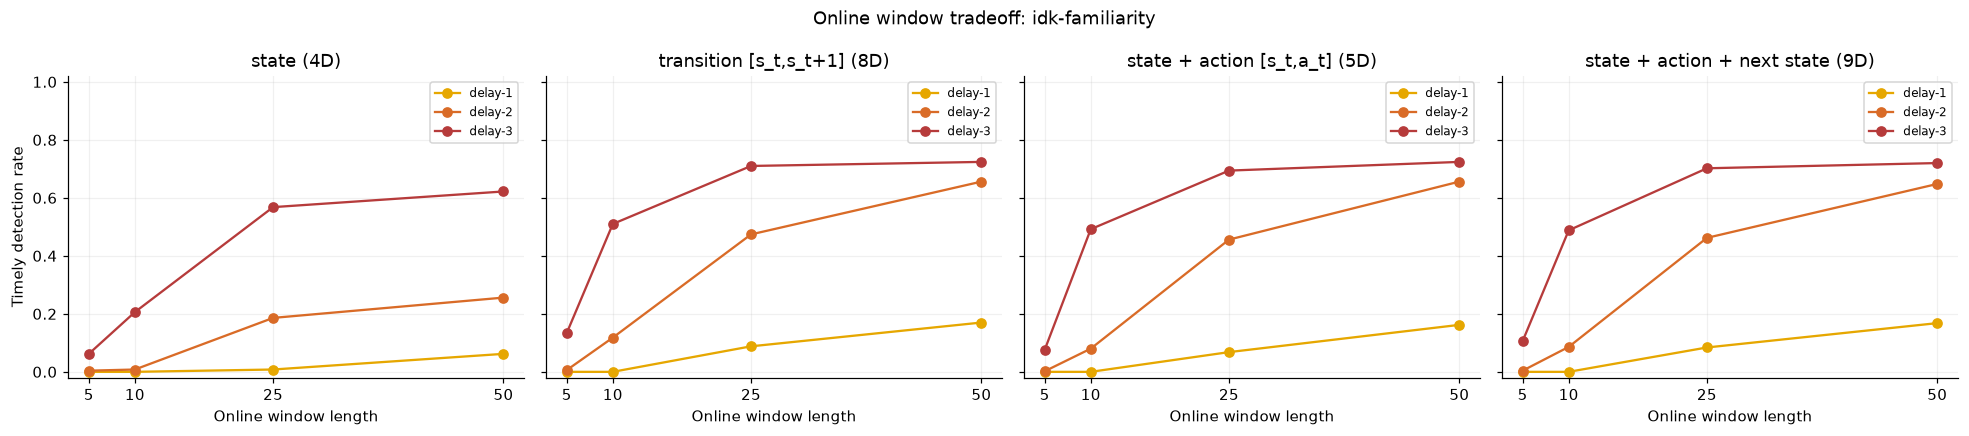

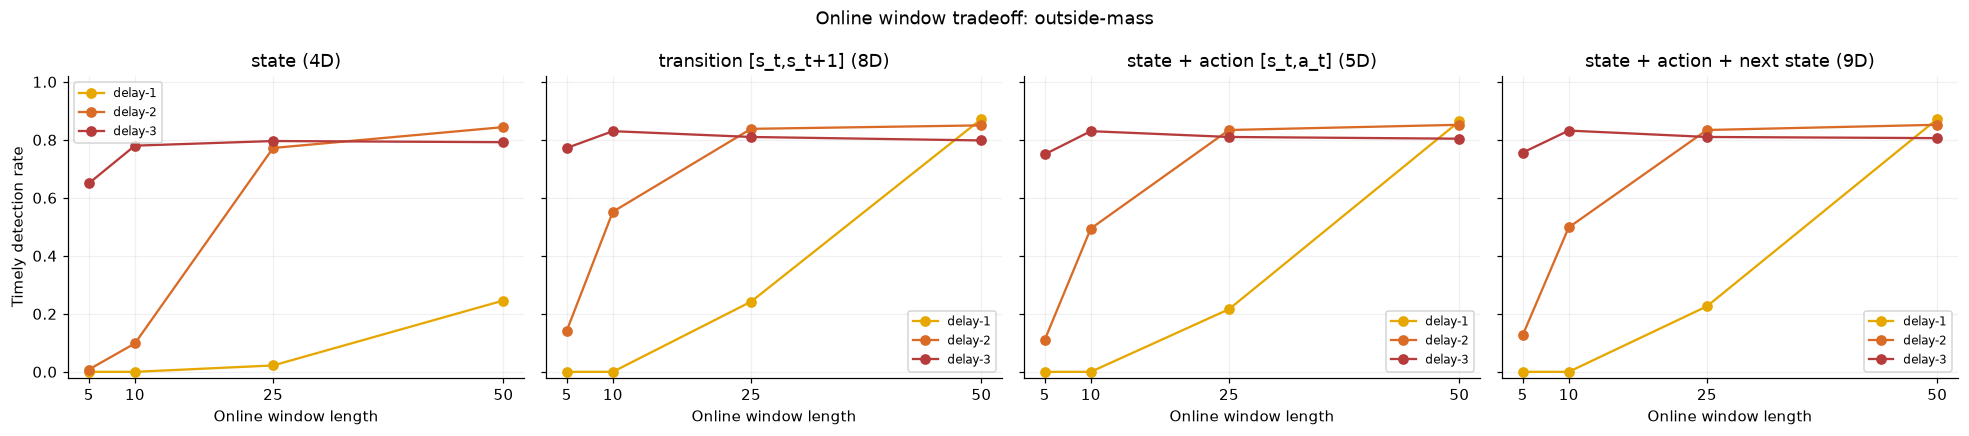

In [26]:
# Plot focus alarm behavior by delay severity and representation.

for metric in ("idk-familiarity", "outside-mass", "idk-distance"):
    fig, axes = plt.subplots(
        1,
        len(REPRESENTATIONS),
        figsize=(4.5 * len(REPRESENTATIONS), 4),
        sharey=True,
    )
    if len(REPRESENTATIONS) == 1:
        axes = [axes]

    for ax, rep in zip(axes, REPRESENTATIONS):
        g = alarm_summary.query(
            "representation == @rep and psi == @FOCUS_PSI and t == @FOCUS_T "
            "and window_length == @FOCUS_WINDOW and metric == @metric"
        ).sort_values("severity")

        ax.plot(
            g.severity,
            g.timely_detection_rate,
            marker="o",
            label="departure detection",
        )
        ax.axhline(
            g.nominal_fpr.iloc[0] if len(g) else np.nan,
            linestyle=":",
            label="held-out nominal FPR",
        )
        ax.axhline(ALPHA, linestyle="--", color="black", label="calibration target")
        ax.set(
            title=REP_LABELS[rep],
            xlabel="Action-delay severity",
            ylabel="Episode fraction" if ax is axes[0] else None,
            ylim=(-0.02, 1.02),
            xticks=(1, 2, 3),
        )
        ax.legend(fontsize=8)

    fig.suptitle(
        f"Online alarms: {metric}, psi={FOCUS_PSI}, t={FOCUS_T}, k={FOCUS_WINDOW}"
    )
    figure_done(f"06_alarm_severity_{metric.replace('-', '_')}")


# Window-length tradeoff at the focus psi/t.
for metric in ("idk-familiarity", "outside-mass"):
    fig, axes = plt.subplots(
        1,
        len(REPRESENTATIONS),
        figsize=(4.5 * len(REPRESENTATIONS), 4),
        sharey=True,
    )
    if len(REPRESENTATIONS) == 1:
        axes = [axes]

    for ax, rep in zip(axes, REPRESENTATIONS):
        for delay_population in DELAY_POPULATIONS:
            g = alarm_summary.query(
                "representation == @rep and psi == @FOCUS_PSI and t == @FOCUS_T "
                "and metric == @metric and delay_population == @delay_population"
            ).sort_values("window_length")
            ax.plot(
                g.window_length,
                g.timely_detection_rate,
                marker="o",
                label=delay_population,
                color=COLORS[delay_population],
            )
        ax.set(
            title=REP_LABELS[rep],
            xlabel="Online window length",
            ylabel="Timely detection rate" if ax is axes[0] else None,
            ylim=(-0.02, 1.02),
            xticks=WINDOW_SIZES,
        )
        ax.legend(fontsize=8)

    fig.suptitle(f"Online window tradeoff: {metric}")
    figure_done(f"07_window_alarm_tradeoff_{metric.replace('-', '_')}")


### Findings: online alarms

At $\psi=64$, $t=200$, $k=25$:

- Outside mass detects only 2.2% of delay-1 with state, versus 21.6–24.2% with transition and action representations. Delay-2/3 detection is 77.2–83.8% and 79.6–81.0%.
- Familiarity detects 0.8–8.8% of delay-1, 18.6–47.4% of delay-2, and 56.8–71.0% of delay-3.
- Nominal FPR is 8.0–8.8% for outside mass and 9.4–10.4% for familiarity. IDK distance gives no timely detections with the greater-distance rule.

The nominal calibration includes unfamiliar early motion from random starts. An alarm must exceed those episode-wide extremes. This helps explain why strong post-onset AUROC can coexist with poor mild-delay detection. Pre-onset first alarms and early termination also reduce timely detection.

**Window-size plots.** At $k=50$, outside-mass detection of delay-1 rises to 86.4–87.2% for transition and action representations, versus 24.6% for state. Delay-3 stays near 79–81%. Longer windows improve the balance across severities here; each window size has its own threshold and reference bank.


### Individual alarm traces

Show the first three evaluation episodes in each population at the focus basis and window size. The selectors below default to transition and outside mass. Each panel is one episode.

Thin lines show individual window anomaly scores; thick lines show the minimum over the required consecutive windows. An alarm occurs when the thick line first exceeds the threshold. Markers show onset, first alarm, and episode end. A pre-onset first alarm is labeled separately.

If the episode ends before scheduled onset, the plot omits the onset line and labels the delay as unobserved. Any recorded alarm is still shown.

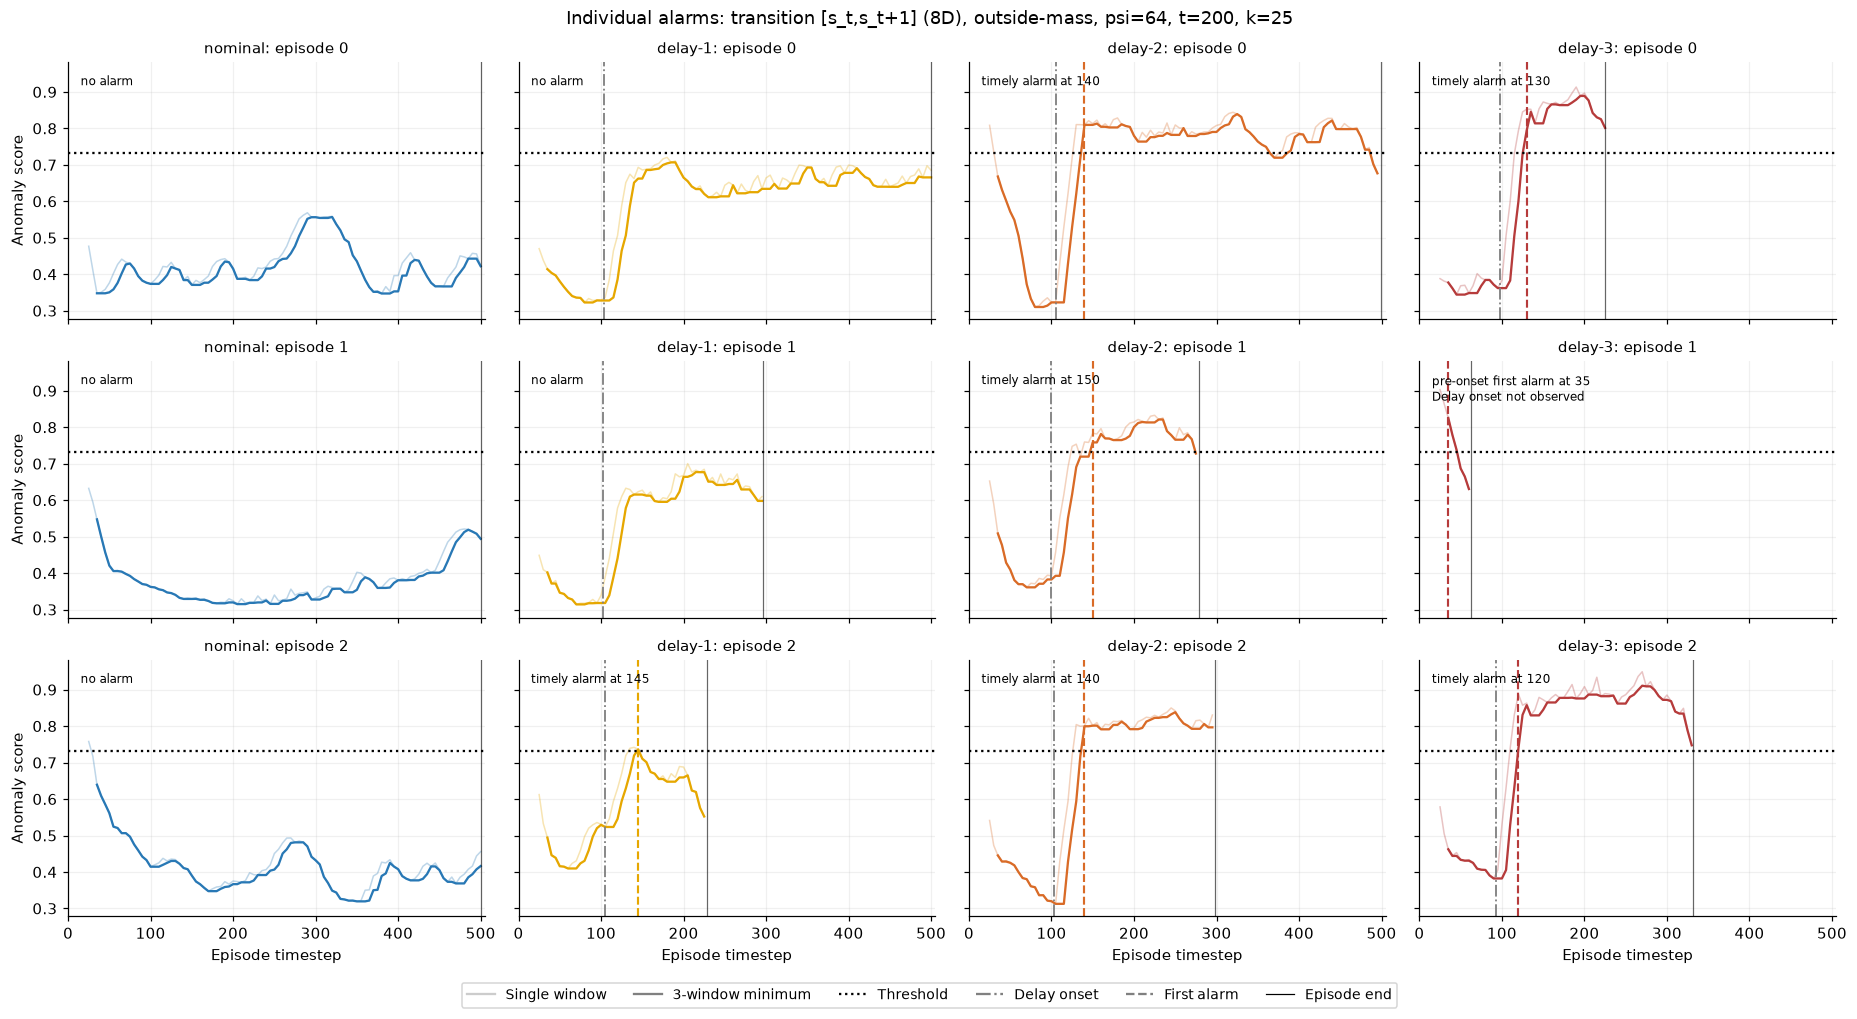

In [27]:
# Show per-episode window scores, persistence, and the recorded alarm decisions.

from matplotlib.lines import Line2D

ALARM_TRACE_REPRESENTATION = "transition"
ALARM_TRACE_METRIC = "outside-mass"
trace_scores = focus_scores.query(
    "representation == @ALARM_TRACE_REPRESENTATION and metric == @ALARM_TRACE_METRIC"
)
trace_alarms = alarm_episodes.query(
    "representation == @ALARM_TRACE_REPRESENTATION and metric == @ALARM_TRACE_METRIC "
    "and psi == @FOCUS_PSI and t == @FOCUS_T and window_length == @FOCUS_WINDOW"
)
fig, axes = plt.subplots(3, len(EVALUATION_POPULATIONS), figsize=(17, 9),
                         sharex=True, sharey=True, squeeze=False)
for col, population in enumerate(EVALUATION_POPULATIONS):
    for row, episode in enumerate(example_records[population]):
        ax = axes[row, col]
        values = trace_scores[(trace_scores.population == population) &
                              (trace_scores.episode_id == episode.trajectory_id)]
        decision = trace_alarms[(trace_alarms.population == population) &
                                (trace_alarms.episode_id == episode.trajectory_id)]
        if len(decision) != 1:
            raise ValueError(f"Expected one alarm record for {population}/{episode.trajectory_id}")
        decision = decision.iloc[0]
        ordered, sustained = sustained_trace(values)
        ax.plot(ordered.end_step, ordered.anomaly, color=COLORS[population], alpha=.3, linewidth=1)
        ax.plot(ordered.end_step, sustained, color=COLORS[population], linewidth=1.5)
        if np.isfinite(decision.threshold):
            ax.axhline(decision.threshold, color="black", linestyle=":")
        onset_reached = pd.notna(episode.onset) and 0 <= episode.onset < episode.length
        if population in DELAY_POPULATIONS and onset_reached:
            ax.axvline(episode.onset, color="gray", linestyle="-.", linewidth=1.2)
        ax.axvline(episode.length, color="black", linestyle="-", linewidth=.8, alpha=.6)
        if np.isfinite(decision.first_alarm):
            ax.axvline(decision.first_alarm, color=COLORS[population], linestyle="--", linewidth=1.4)
            status = "pre-onset first alarm" if decision.pre_onset_alarm else (
                "timely alarm" if decision.timely_detection else "nominal false alarm" if population == "nominal" else "alarm at episode end"
            )
            status += f" at {int(decision.first_alarm)}"
        else:
            status = "no alarm"
        if population in DELAY_POPULATIONS and not onset_reached:
            status += "\nDelay onset not observed"
        ax.text(.03, .95, status, transform=ax.transAxes, va="top", fontsize=8)
        ax.set_title(f"{population}: episode {episode.episode_index}", fontsize=10)
        ax.set_xlim(0, episodes.length.max() + QUERY_STRIDE)
        if col == 0:
            ax.set_ylabel("Anomaly score")
        if row == 2:
            ax.set_xlabel("Episode timestep")
fig.legend(handles=[
    Line2D([], [], color="gray", alpha=.4, label="Single window"),
    Line2D([], [], color="gray", linewidth=1.5, label=f"{PERSISTENCE}-window minimum"),
    Line2D([], [], color="black", linestyle=":", label="Threshold"),
    Line2D([], [], color="gray", linestyle="-.", label="Delay onset"),
    Line2D([], [], color="gray", linestyle="--", label="First alarm"),
    Line2D([], [], color="black", linewidth=.8, label="Episode end"),
], loc="lower center", bbox_to_anchor=(.5, -.035), ncol=6, fontsize=9)
fig.suptitle(f"Individual alarms: {REP_LABELS[ALARM_TRACE_REPRESENTATION]}, {ALARM_TRACE_METRIC}, "
             f"psi={FOCUS_PSI}, t={FOCUS_T}, k={FOCUS_WINDOW}")
figure_done("13_individual_alarm_traces")

**Example findings.** The three nominal examples produce no alarms. Only delay-1 episode 2 alarms, at step 145; episodes 0 and 1 remain below threshold. All three delay-2 examples alarm after onset. Delay-3 episodes 0 and 2 alarm at steps 130 and 120. Episode 1 alarms at 35 and ends at 63, before scheduled onset at 101, so it is a pre-onset alarm rather than delay detection.


### Detection timing

Each curve shows the fraction of **all** episodes in one delayed population detected by a given number of steps after onset. Missed detections, pre-onset first alarms, and episodes ending before scheduled onset remain in the denominator. A plateau below 1 means some episodes were not detected in time.

These curves use the existing alarm decisions and their calibrated thresholds. They do not choose a new threshold at each time.

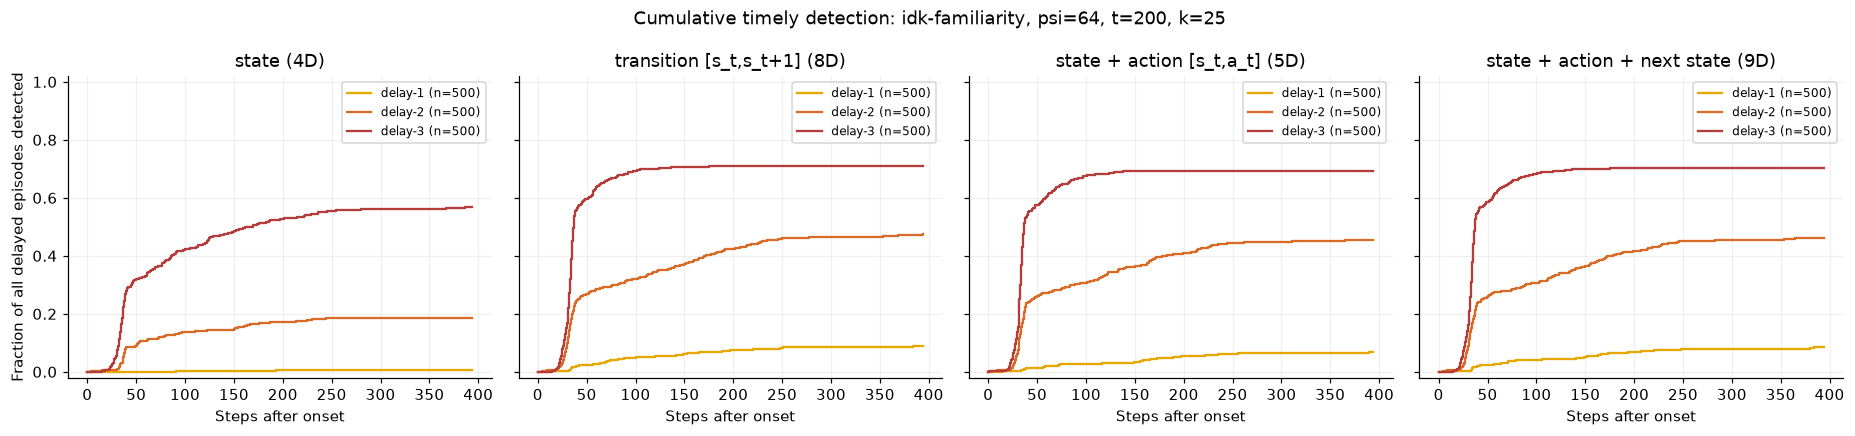

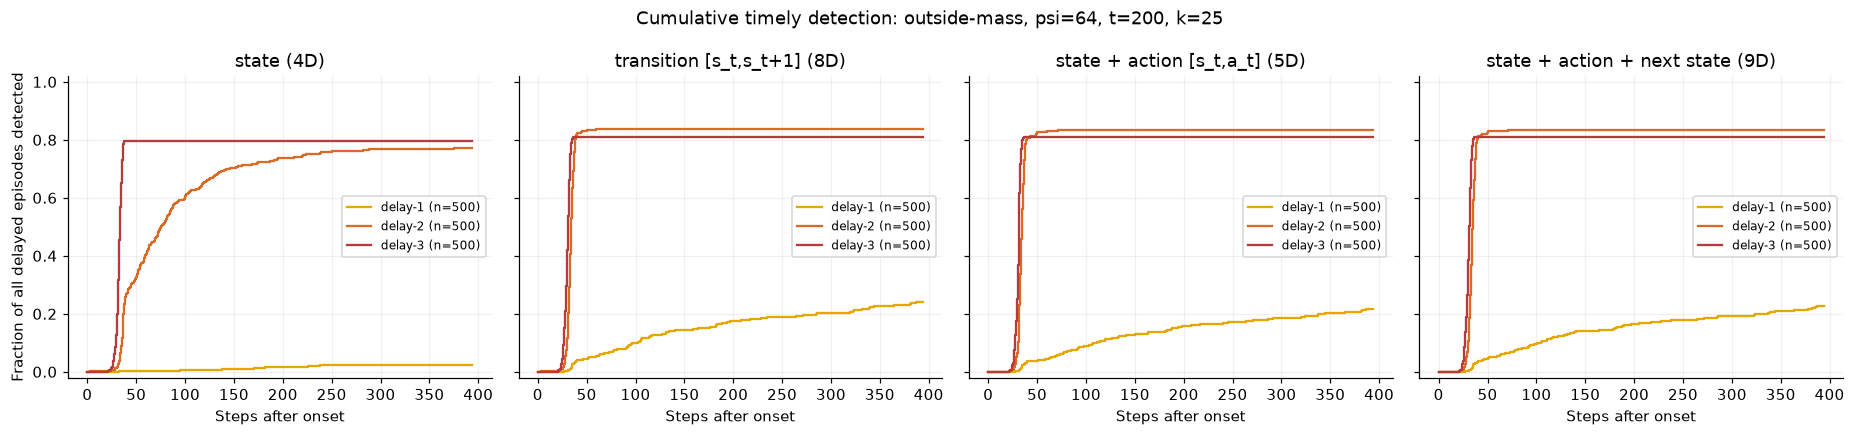

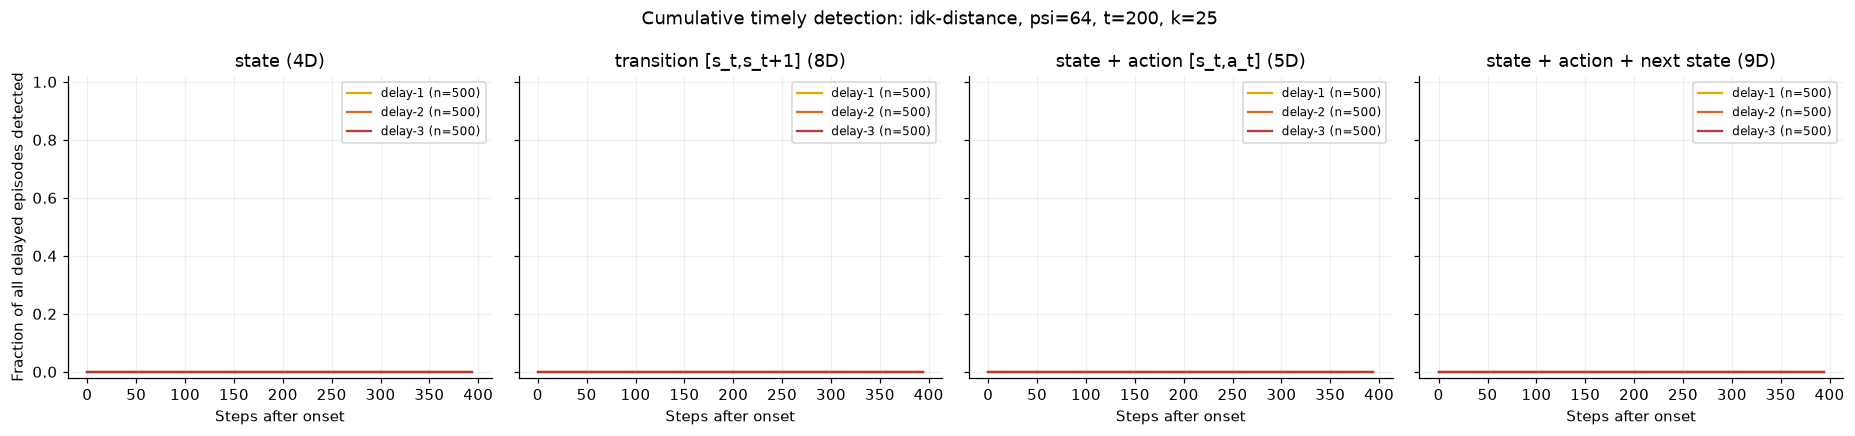

In [28]:
# Plot cumulative timely detection using every delayed episode as the denominator.

TIMING_METRICS = ("idk-familiarity", "outside-mass", "idk-distance")
timing_focus = alarm_episodes.query(
    "psi == @FOCUS_PSI and t == @FOCUS_T and window_length == @FOCUS_WINDOW "
    "and population in @DELAY_POPULATIONS and metric in @TIMING_METRICS"
)
last_latency = timing_focus.latency.max()
horizons = np.arange(0, max(1, int(np.ceil(last_latency)) if np.isfinite(last_latency) else 1) + 1)
detection_curve_rows = []
for metric in TIMING_METRICS:
    fig, axes = plt.subplots(1, len(REPRESENTATIONS), figsize=(17, 4), sharex=True, sharey=True, squeeze=False)
    for ax, rep in zip(axes.flat, REPRESENTATIONS):
        for population in DELAY_POPULATIONS:
            g = timing_focus.query("representation == @rep and metric == @metric and population == @population")
            if len(g) == 0:
                raise ValueError(f"Missing alarm records: {rep}, {metric}, {population}")
            latencies = np.sort(g.loc[g.timely_detection, "latency"].dropna().to_numpy())
            rates = np.searchsorted(latencies, horizons, side="right") / len(g)
            ax.step(horizons, rates, where="post", color=COLORS[population], label=f"{population} (n={len(g)})")
            detection_curve_rows.append(pd.DataFrame({
                "representation": rep, "metric": metric, "population": population,
                "steps_after_onset": horizons, "fraction_detected": rates, "n_episodes": len(g),
            }))
        ax.set(title=REP_LABELS[rep], xlabel="Steps after onset", ylim=(-.02, 1.02))
        ax.legend(fontsize=8)
    axes[0, 0].set_ylabel("Fraction of all delayed episodes detected")
    fig.suptitle(f"Cumulative timely detection: {metric}, psi={FOCUS_PSI}, t={FOCUS_T}, k={FOCUS_WINDOW}")
    figure_done(f"14_detection_timing_{metric}")
pd.concat(detection_curve_rows, ignore_index=True).to_csv(CACHE / "detection_timing_curves.csv", index=False)

### Window size and conditional timing

These points show median latency and median time from alarm to episode end **among timely detections only**. Missing points mean no timely detections. Read them with the detection-rate plots above: a shorter median can reflect a smaller detected subset.

Every severity contains both failures and survivors. Time to episode end mixes early termination with the 500-step cutoff; it is not uniformly lead time to failure.

Each window size has its own reference bank and calibrated threshold. Online windows can include pre-onset observations. A larger window therefore need not produce a later alarm.


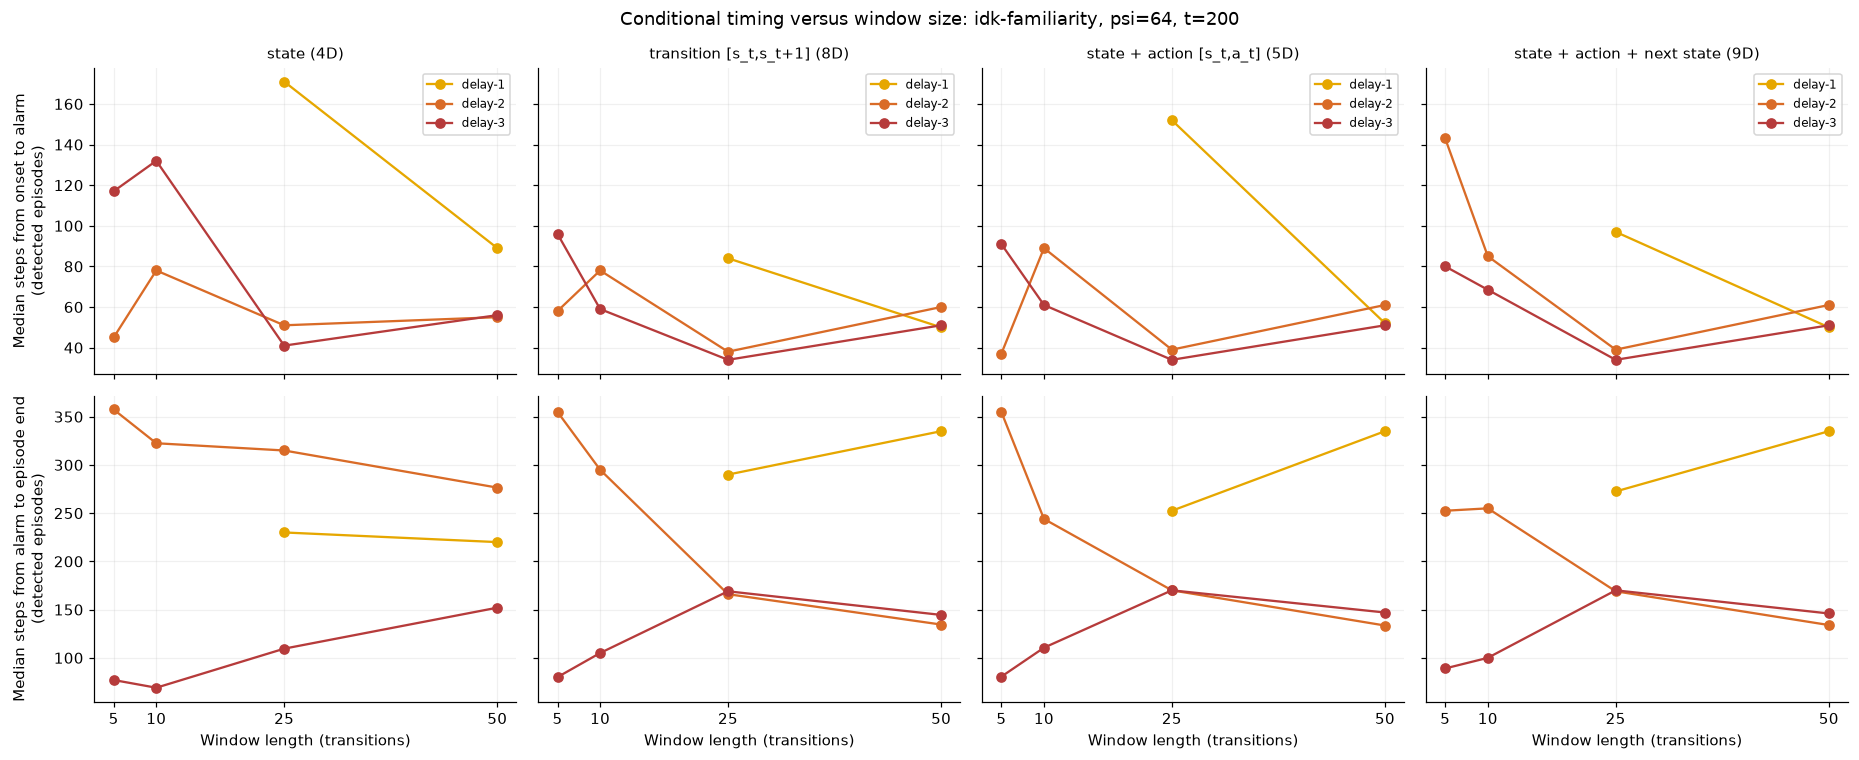

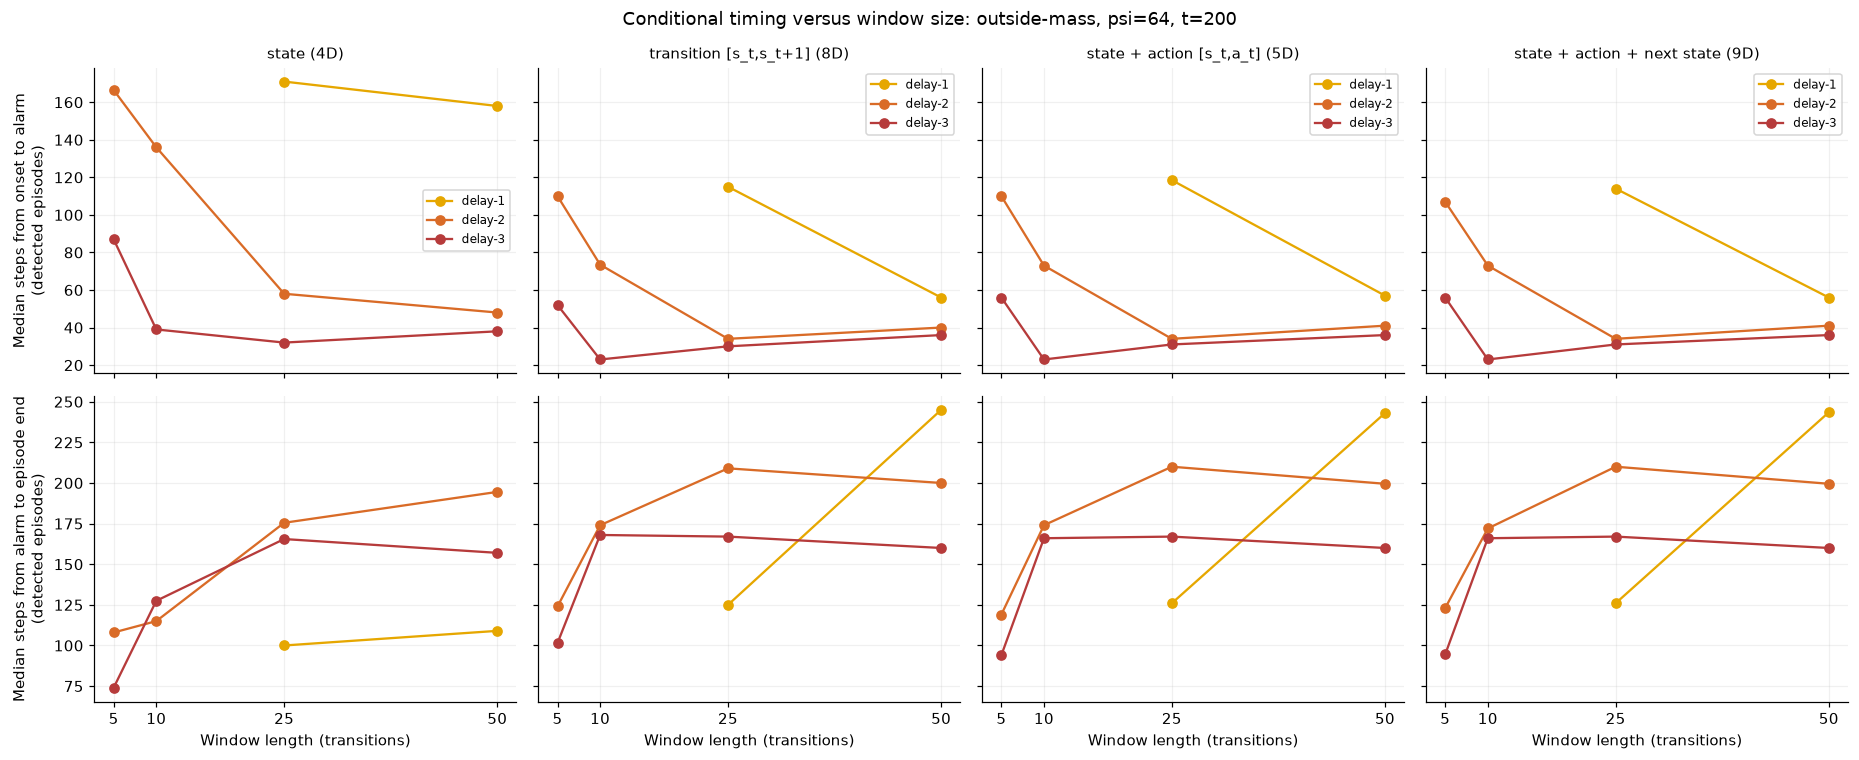

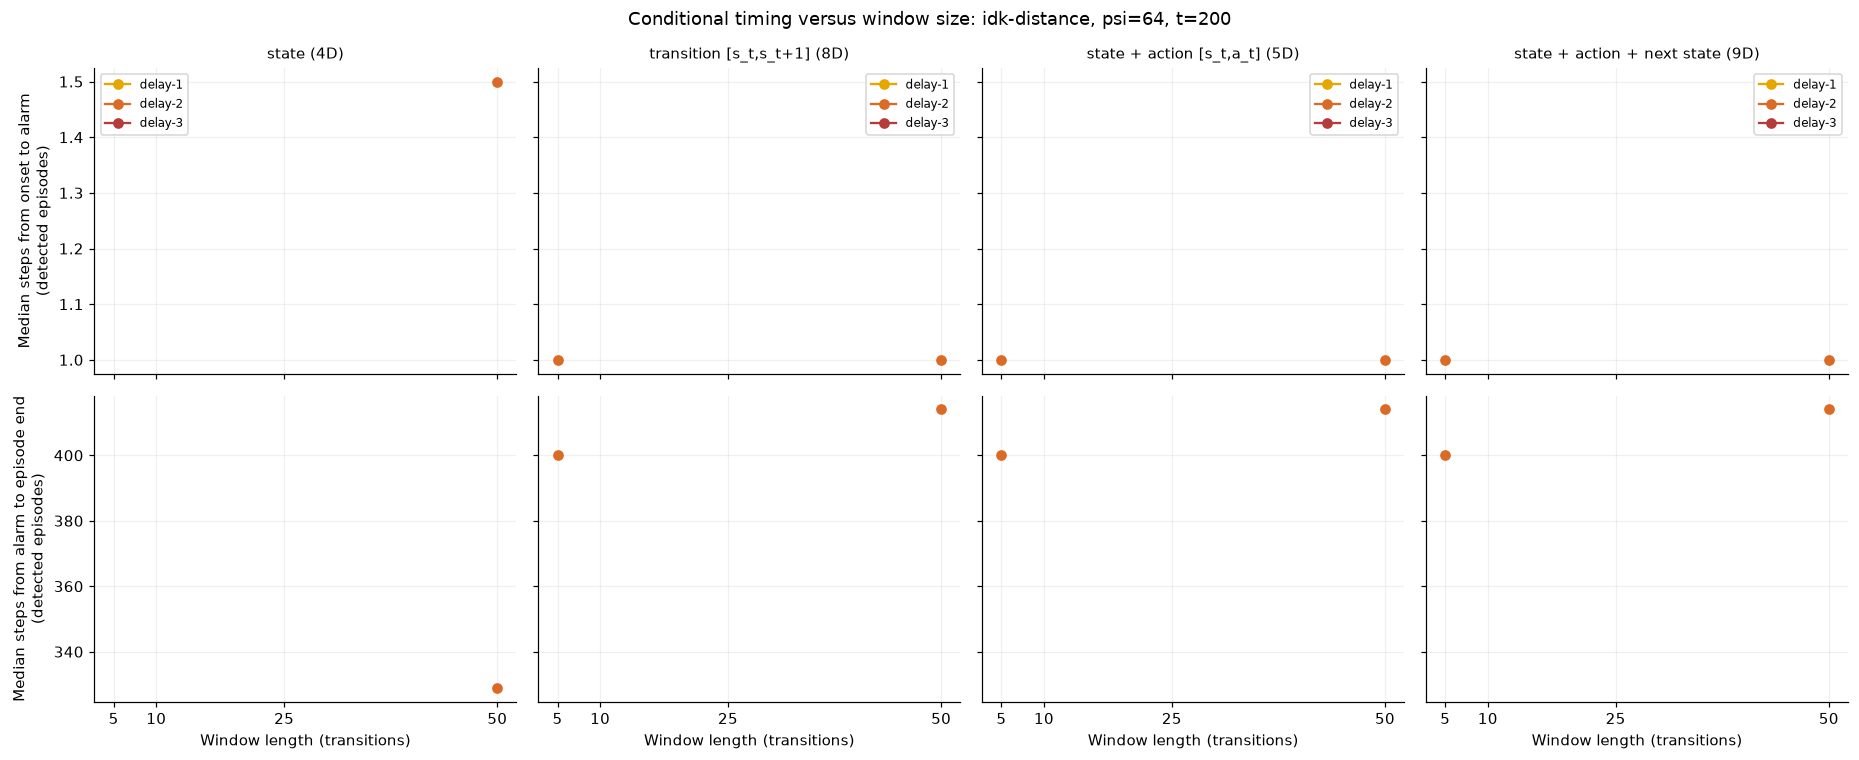

In [29]:
# Compare conditional detection latency and time to episode end across window sizes.

for metric in TIMING_METRICS:
    timing_by_window = alarm_summary.query("psi == @FOCUS_PSI and t == @FOCUS_T and metric == @metric")
    if not timing_by_window.median_latency.notna().any():
        display(Markdown(f"**{metric}:** no timely detections at this focus basis across the window sizes; conditional timing is undefined."))
        continue
    fig, axes = plt.subplots(2, len(REPRESENTATIONS), figsize=(17, 7),
                             sharex=True, sharey="row", squeeze=False)
    for col, rep in enumerate(REPRESENTATIONS):
        for population in DELAY_POPULATIONS:
            g = timing_by_window.query("representation == @rep and delay_population == @population").sort_values("window_length")
            for row, value in enumerate(("median_latency", "median_lead_time")):
                axes[row, col].plot(g.window_length, g[value], marker="o", color=COLORS[population], label=population)
        axes[0, col].set_title(REP_LABELS[rep], fontsize=10)
        axes[0, col].legend(fontsize=8)
        axes[1, col].set(xlabel="Window length (transitions)", xticks=WINDOW_SIZES)
    axes[0, 0].set_ylabel("Median steps from onset to alarm\n(detected episodes)")
    axes[1, 0].set_ylabel("Median steps from alarm to episode end\n(detected episodes)")
    fig.suptitle(f"Conditional timing versus window size: {metric}, psi={FOCUS_PSI}, t={FOCUS_T}")
    figure_done(f"15_window_timing_{metric}")

**Findings.** At the focus setting, outside-mass detection of delay-2/3 rises sharply around 30–40 steps after onset for transition and action representations. Mild-delay detections accumulate much more slowly and plateau near 22–24%. Familiarity reaches lower detection fractions, especially for mild delay.

With $k=50$, outside-mass median latency for detected mild delays falls to 56–57 steps in these representations, while detection rises above 86%. For delay-3, increasing $k$ from 10 to 50 raises median latency from 23 to 36 steps, with slightly lower detection.

Distance gives no timely detections at $k=25$. Its isolated timing points at other window sizes represent only one or two detected episodes per population; they do not establish useful detection.


[↑ Back to top](#notebook-top)

<a id="section-7"></a>

## 7. Exploratory link between early familiarity and eventual failure

Departure detection and failure prediction are not the same problem.

A delayed episode may become unfamiliar and then recover. Conversely, a failure predictor is useful only if score differences occur **before** termination and distinguish episodes with different outcomes.

This section uses the first fully post-onset window at the predeclared focus setting and asks:

- within each perturbation severity, do early anomaly scores separate episodes that later fail from episodes that survive to 500?
- does anomaly magnitude correlate with remaining lifetime after onset?

Results are reported only where both outcome classes exist. A pooled all-severity result is also shown for context, but it is confounded by perturbation severity and should not be treated as a calibrated failure model.


Only episodes with a complete post-onset window contribute here. Failures before the scheduled delay are excluded from this post-onset comparison.

,representation,metric,scope,n,n_failure,n_success,failure_auroc,spearman_anomaly_vs_shorter_remaining_life,spearman_p
0,state,idk-familiarity,pooled,1364,1044,320,0.429,-0.093,0.001
1,state,idk-familiarity,delay-1,469,296,173,0.255,-0.402,0.000
2,state,idk-familiarity,delay-2,456,355,101,0.174,-0.441,0.000
3,state,idk-familiarity,delay-3,439,393,46,0.197,-0.409,0.000
4,state,outside-mass,pooled,1364,1044,320,0.685,0.335,0.000
5,state,outside-mass,delay-1,469,296,173,0.680,0.249,0.000
6,state,outside-mass,delay-2,456,355,101,0.485,0.146,0.002
7,state,outside-mass,delay-3,439,393,46,0.386,0.225,0.000
8,state,support-rate,pooled,1364,1044,320,0.685,0.335,0.000
9,state,support-rate,delay-1,469,296,173,0.680,0.249,0.000


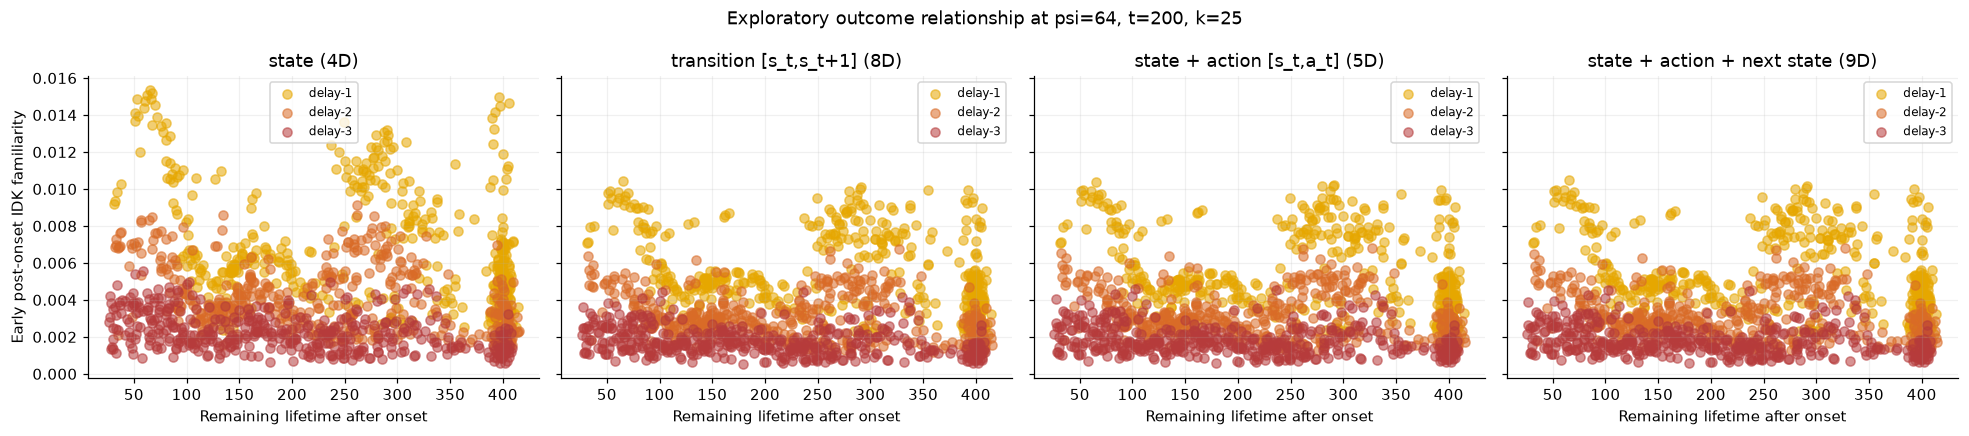

In [30]:
# Early post-onset familiarity versus eventual outcome.

failure_link_rows = []
focus_failure = focus_scores.query(
    "psi == @FOCUS_PSI and t == @FOCUS_T and window_length == @FOCUS_WINDOW "
    "and population in @DELAY_POPULATIONS "
    "and metric in ['idk-familiarity', 'outside-mass', 'support-rate']"
).copy()

episode_meta = episodes.loc[
    episodes.population.isin(DELAY_POPULATIONS),
    ["population", "trajectory_id", "onset", "length", "failure", "survived_500"],
].rename(columns={"trajectory_id": "episode_id"})

focus_failure = focus_failure.merge(
    episode_meta,
    on=["population", "episode_id"],
    how="left",
    suffixes=("", "_episode"),
)
focus_failure = focus_failure[focus_failure.start_step >= focus_failure.onset]
focus_failure = (
    focus_failure.sort_values(["representation", "metric", "population", "episode_id", "end_step"])
    .groupby(["representation", "metric", "population", "episode_id"], as_index=False)
    .head(1)
)
focus_failure["remaining_life_after_onset"] = focus_failure.length - focus_failure.onset

for (rep, metric), group in focus_failure.groupby(["representation", "metric"], sort=False):
    scopes = [("pooled", group)]
    scopes.extend(
        (population, values)
        for population, values in group.groupby("population")
    )

    for scope, values in scopes:
        values = values.dropna(subset=["anomaly", "remaining_life_after_onset"])
        n_failure = int(values.failure.sum())
        n_success = int((~values.failure.astype(bool)).sum())

        auc = np.nan
        if n_failure > 0 and n_success > 0:
            auc = roc_auc_score(values.failure.astype(int), values.anomaly)

        rho = np.nan
        pvalue = np.nan
        if len(values) >= 3 and values.anomaly.nunique() > 1:
            result = spearmanr(
                values.anomaly,
                -values.remaining_life_after_onset,
                nan_policy="omit",
            )
            rho = float(result.statistic)
            pvalue = float(result.pvalue)

        failure_link_rows.append(
            {
                "representation": rep,
                "metric": metric,
                "scope": scope,
                "n": len(values),
                "n_failure": n_failure,
                "n_success": n_success,
                "failure_auroc": auc,
                "spearman_anomaly_vs_shorter_remaining_life": rho,
                "spearman_p": pvalue,
            }
        )

failure_link = pd.DataFrame(failure_link_rows)
failure_link.to_csv(CACHE / "failure_link.csv", index=False)
display(failure_link.round(3))

# Plot pooled early scores only as a descriptive view; severity is shown explicitly.
fig, axes = plt.subplots(
    1,
    len(REPRESENTATIONS),
    figsize=(4.5 * len(REPRESENTATIONS), 4),
    sharey=True,
)
if len(REPRESENTATIONS) == 1:
    axes = [axes]

metric = "idk-familiarity"
for ax, rep in zip(axes, REPRESENTATIONS):
    g = focus_failure.query("representation == @rep and metric == @metric")
    for population in DELAY_POPULATIONS:
        h = g[g.population == population]
        ax.scatter(
            h.remaining_life_after_onset,
            h.score,
            alpha=0.55,
            label=population,
            color=COLORS[population],
        )
    ax.set(
        title=REP_LABELS[rep],
        xlabel="Remaining lifetime after onset",
        ylabel="Early post-onset IDK familiarity" if ax is axes[0] else None,
    )
    ax.legend(fontsize=8)

fig.suptitle(
    f"Exploratory outcome relationship at psi={FOCUS_PSI}, t={FOCUS_T}, k={FOCUS_WINDOW}"
)
figure_done("08_early_familiarity_vs_remaining_life")


### Findings: relationship to failure

All three severities contain both outcomes. The complete 25-step post-onset subset contains 469/456/439 delay-1/2/3 episodes, including 173/101/46 survivors. Earlier failures are excluded.

- Within each severity, failure AUROC for **negative familiarity** is only 0.17–0.26. Eventual failures tend to have *higher* early familiarity than survivors. This reverses the proposed low-familiarity failure signal.
- Outside mass has modest failure separation for delay-1 (0.66–0.68) and delay-2 in transition/action representations (0.65). Delay-3 is reversed or weak (0.39–0.46).
- Pooled outside-mass AUROC is 0.68–0.70, but severity also affects both scores and failure rates.

The scatter shows broad overlap in remaining lifetime. Survivors cluster near 400 steps after onset because of the cutoff. Departure sensitivity does not establish a general failure predictor, and choosing a reversed score after seeing these results would require fresh validation.


[↑ Back to top](#notebook-top)

<a id="section-8"></a>

## 8. $\psi$ operating-range view

The top row shows timely detection across $\psi$ at $t=200$, $k=25$. The bottom row shows measured nominal test FPR. Each representation, metric, and $\psi$ has its own calibrated threshold.

**Nominal FPR** is the fraction of all 500 nominal test episodes with at least one persistent alarm anywhere in the episode. Scores are computed every 5 steps. An alarm requires three consecutive anomaly-oriented scores strictly above threshold. Unscorable episodes remain in the denominator. Nominal includes unperturbed failures, so FPR here means an alarm in the unperturbed population, regardless of outcome.

**Threshold construction.** Take the minimum score in each group of three windows, then the maximum of those minima within each calibration episode. At $k=25$, 488 calibration episodes have scores; use their 441st smallest episode score as the threshold. Apply it unchanged to the test episodes. Familiarity is negated; outside mass keeps its sign. See [section 6](#section-6).

The dotted line is the 10% target, not a forced test result. Only this target is evaluated. All three severities use the same nominal FPR; their detection curves need not overlap.


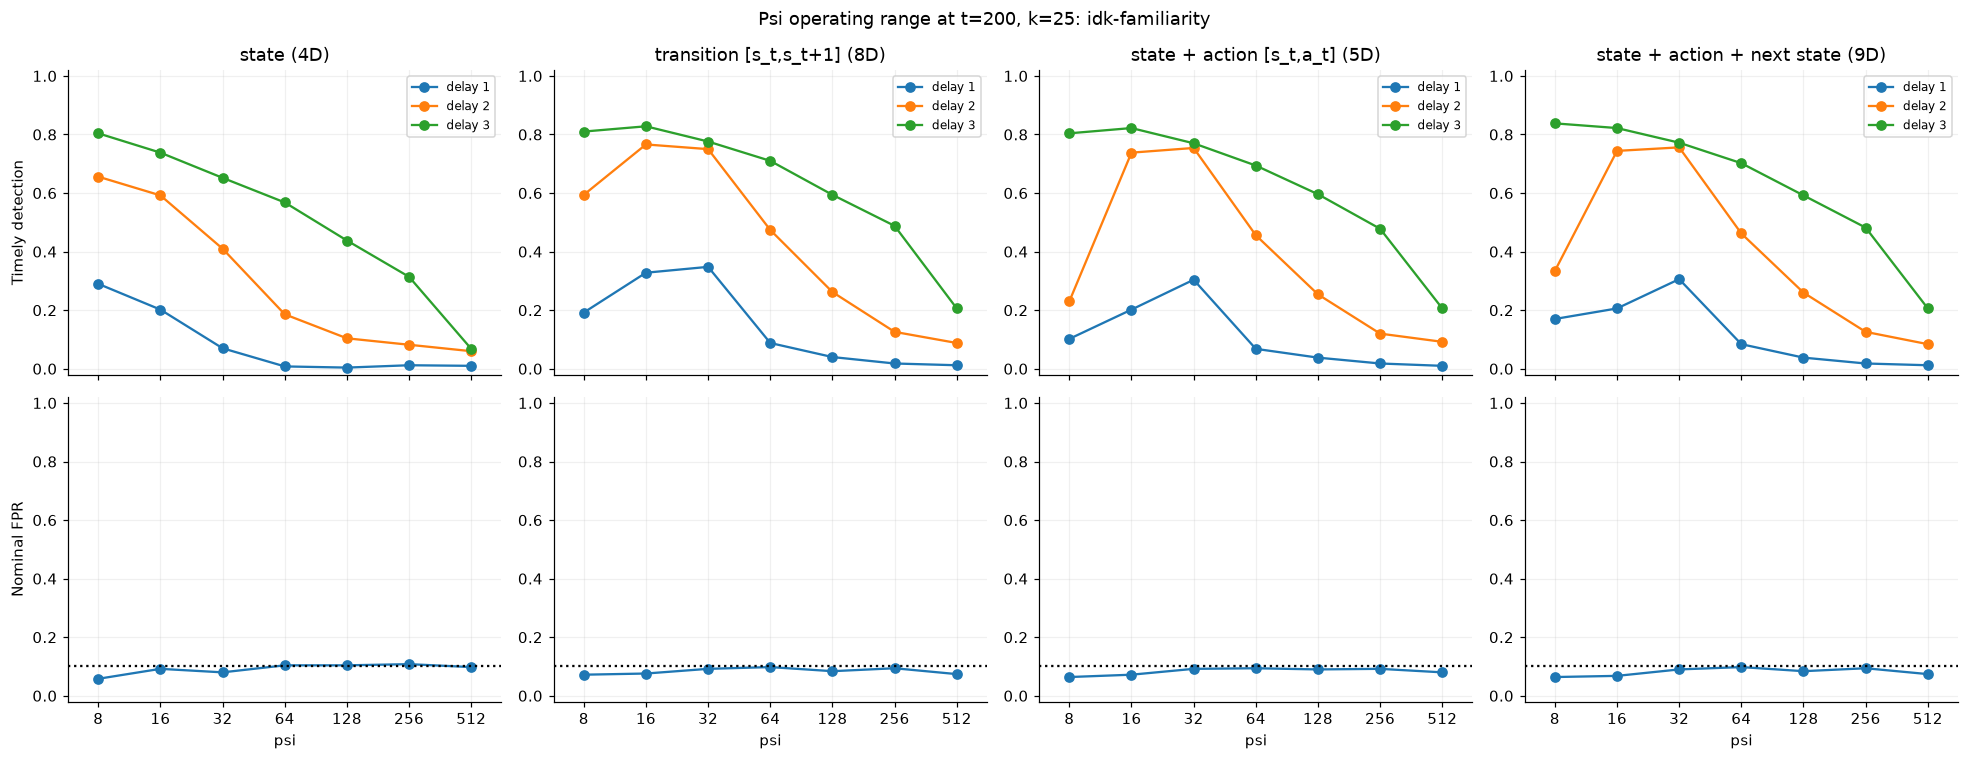

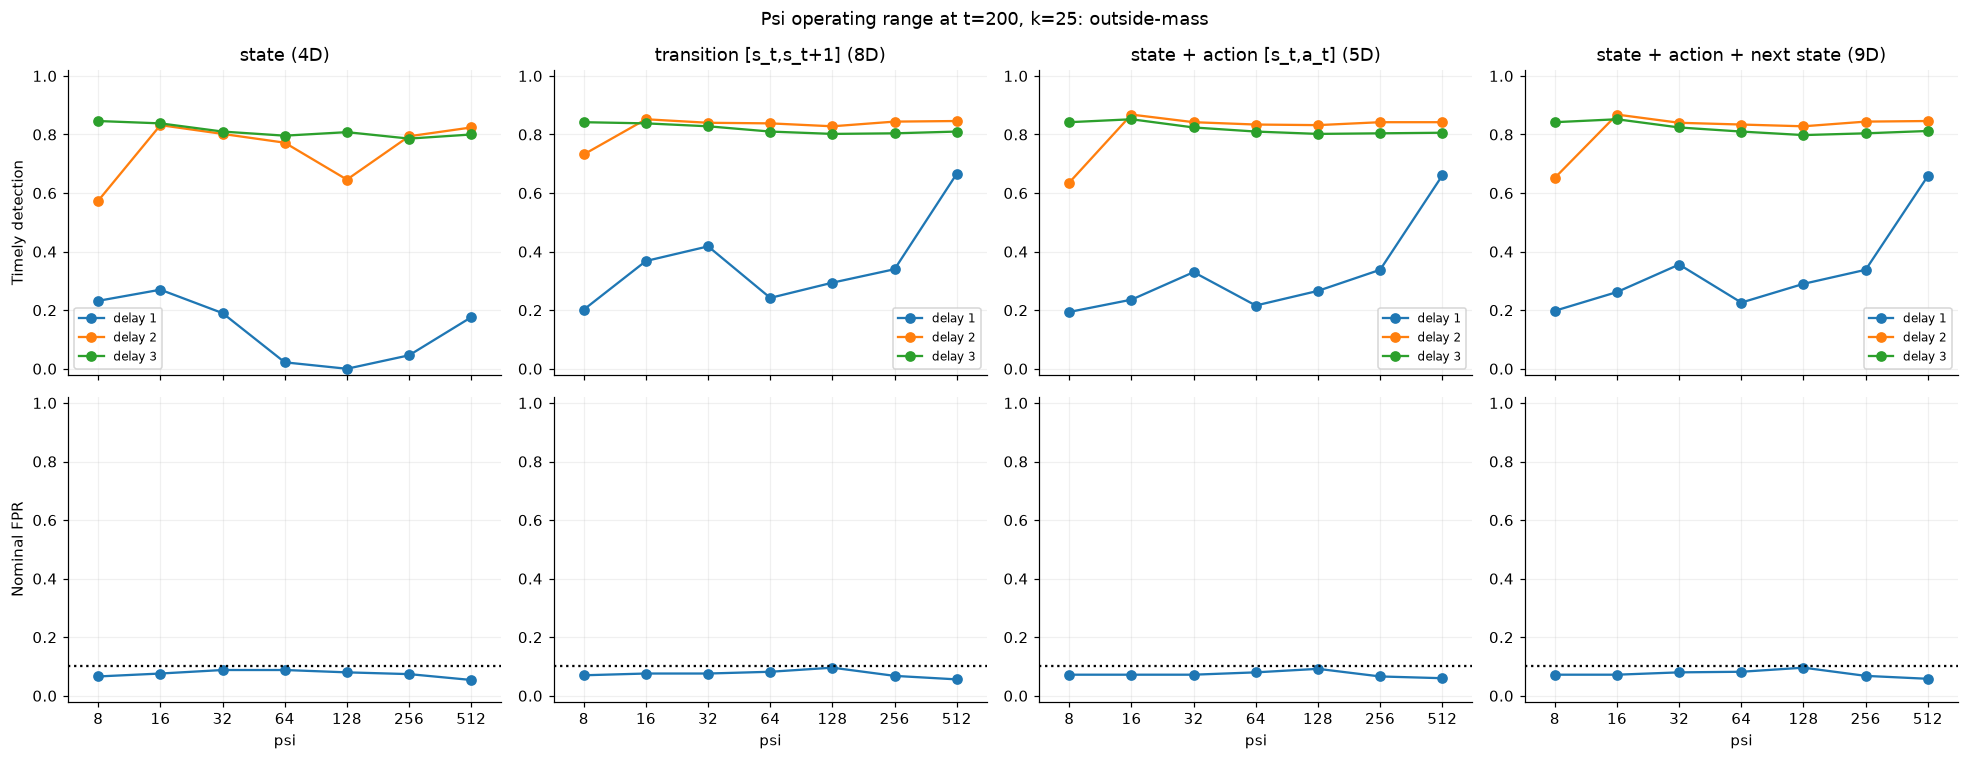

,representation,metric,psi,severity,detection,nominal_fpr,latency,unscorable
0,state,cosine,8,1,0.018,0.076,7.0,0.036
1,state,cosine,8,2,0.016,0.076,5.0,0.026
2,state,cosine,8,3,0.024,0.076,7.0,0.036
3,state,cosine,16,1,0.002,0.106,15.0,0.036
4,state,cosine,16,2,0.004,0.106,10.0,0.026
...,...,...,...,...,...,...,...,...
331,transition,outside-mass,256,2,0.844,0.068,35.0,0.026
332,transition,outside-mass,256,3,0.804,0.068,32.0,0.036
333,transition,outside-mass,512,1,0.666,0.056,98.0,0.036
334,transition,outside-mass,512,2,0.846,0.056,33.0,0.026


In [31]:
# Psi operating-range summaries at the focus window.

psi_summary = (
    alarm_summary.query("window_length == @FOCUS_WINDOW and t == @FOCUS_T")
    .groupby(["representation", "metric", "psi", "severity"], as_index=False)
    .agg(
        detection=("timely_detection_rate", "mean"),
        nominal_fpr=("nominal_fpr", "mean"),
        latency=("median_latency", "median"),
        unscorable=("unscorable_fraction", "mean"),
    )
)
psi_summary.to_csv(CACHE / "psi_operating_summary.csv", index=False)

for metric in ("idk-familiarity", "outside-mass"):
    fig, axes = plt.subplots(
        2,
        len(REPRESENTATIONS),
        figsize=(4.5 * len(REPRESENTATIONS), 7),
        sharex=True,
    )
    if len(REPRESENTATIONS) == 1:
        axes = np.asarray(axes).reshape(2, 1)

    for col, rep in enumerate(REPRESENTATIONS):
        for severity in (1, 2, 3):
            g = psi_summary.query(
                "representation == @rep and metric == @metric and severity == @severity"
            ).sort_values("psi")
            axes[0, col].plot(
                g.psi,
                g.detection,
                marker="o",
                label=f"delay {severity}",
            )

        fpr = (
            psi_summary.query("representation == @rep and metric == @metric")
            .groupby("psi", as_index=False)
            .nominal_fpr.first()
            .sort_values("psi")
        )
        axes[1, col].plot(fpr.psi, fpr.nominal_fpr, marker="o")
        axes[1, col].axhline(ALPHA, linestyle=":", color="black")

        axes[0, col].set(
            title=REP_LABELS[rep],
            ylabel="Timely detection" if col == 0 else None,
            ylim=(-0.02, 1.02),
        )
        axes[1, col].set(
            xlabel="psi",
            ylabel="Nominal FPR" if col == 0 else None,
            ylim=(-0.02, 1.02),
        )
        psi_axis(axes[1, col])
        axes[0, col].legend(fontsize=8)

    fig.suptitle(
        f"Psi operating range at t={FOCUS_T}, k={FOCUS_WINDOW}: {metric}"
    )
    figure_done(f"09_psi_operating_{metric.replace('-', '_')}")

display(psi_summary.round(3))


### Findings: $\psi$ operating range

- Familiarity alarms favor smaller $\psi$ here. State performs best at 8. Transition and action representations give their strongest mild-delay detection around 16–32, then decline sharply at 64 and above.
- Outside mass detects about 80–87% of delay-2/3 for most $\psi\ge16$. Mild delay remains harder. At 512, transition and action representations reach about 66% mild-delay detection, versus 18% for state.
- FPR is 5.4–9.6% for outside mass and 5.8–10.8% for familiarity. Detection is therefore compared at similar, but not identical, measured false-alarm rates.

There is no common best $\psi$ for both metrics. Large $\psi$ helps mild-delay outside-mass alarms in the richer representations but harms familiarity alarms. Window length also matters: section 6 shows much better mild-delay detection at $k=50$.


[↑ Back to top](#notebook-top)

<a id="section-9"></a>

## 9. Interpretation framework

### A. Does the score respond to delay?

Pre-onset score distributions are close. After onset, familiarity falls and outside mass rises, with stronger responses at greater delay. This supports departure detection in the randomized-start population.

### B. Is the response support loss or changed occupancy?

Outside mass separates the delayed populations strongly. Familiarity also changes, while cosine overlaps more. Support loss explains an important part of the response. These comparisons do not isolate its contribution from changes in occupied regions.

### C. Do representations differ?

State describes current experience. Transition adds the next state; the action representations add the recorded action. Transition and action representations improve mild-delay separation and alarms over state at the focus setting. The 9D representation shows little consistent gain over 8D or 5D.

### D. How much history helps?

Five to ten post-onset steps already give strong outside-mass separation. Useful episode-wide alarms often need longer windows. At $k=50$, transition and action representations detect far more mild delays than at $k=25$.

### E. Does departure imply failure?

No simple monotone relationship holds here. Every severity has both outcomes, and failures often have higher early familiarity than survivors within severity. Failure prediction requires its own validation.

### F. What does randomized initialization establish?

This run evaluates a broad nominal basis, reference bank, calibration set, and query populations together. It does not isolate the effect of broadening only the fitted basis. That comparison needs narrow and broad bases scored on the same evaluation populations.

Replicated RANDINIT bases, a $t$ sweep, other false-alarm targets, and unseen perturbations remain open. The summary below selects settings on these results; those choices need confirmation on new data.


In [32]:
# Produce a compact measured-results summary.

summary_lines = [
    f"**Primary grid:** {len(CONFIGURATIONS)} representation/psi fits at t={PRIMARY_T}.",
    f"**Raw populations:** "
    + ", ".join(
        f"{pop}={len(episodes[episodes.population == pop])}"
        for pop in ("reference", "calibration", *EVALUATION_POPULATIONS)
    )
    + ".",
]

# Nominal support range at focus t across psi.
for rep in REPRESENTATIONS:
    g = support_table.query(
        "representation == @rep and population == 'nominal'"
    ).sort_values("psi")
    if len(g):
        summary_lines.append(
            f"**{rep}:** held-out nominal mean support ranges from "
            f"{g.mean_support.min():.1%} to {g.mean_support.max():.1%} across psi."
        )

# Pre/post onset diagnostics at focus setting.
for rep in REPRESENTATIONS:
    g = onset_auc.query(
        "representation == @rep and metric == 'idk-familiarity' "
        "and delay_population == 'delay-3'"
    )
    if len(g):
        pre = g[g.relative_bin < 0]
        post = g[g.relative_bin >= 25]
        if len(pre) and len(post):
            summary_lines.append(
                f"**{rep}, delay-3 IDK familiarity:** median pre-onset AUROC "
                f"{pre.auroc.median():.3f}; median AUROC from +25 steps onward "
                f"{post.auroc.median():.3f}."
            )

# Best descriptive alarm setting per representation under nominal FPR target.
for rep in REPRESENTATIONS:
    feasible = alarm_summary.query(
        "representation == @rep and nominal_fpr <= @ALPHA"
    ).copy()
    if len(feasible):
        # Prefer performance across all severities, not one severity.
        ranked = (
            feasible.groupby(
                ["psi", "t", "window_length", "metric"],
                as_index=False,
            )
            .agg(
                mean_detection=("timely_detection_rate", "mean"),
                min_detection=("timely_detection_rate", "min"),
                nominal_fpr=("nominal_fpr", "first"),
                median_latency=("median_latency", "median"),
            )
            .sort_values(
                ["min_detection", "mean_detection", "nominal_fpr", "median_latency"],
                ascending=[False, False, True, True],
            )
        )
        best = ranked.iloc[0]
        summary_lines.append(
            f"**{rep}:** best observed development-setting under {ALPHA:.0%} held-out nominal FPR "
            f"was {best.metric}, psi={int(best.psi)}, k={int(best.window_length)}; "
            f"minimum detection across delay severities={best.min_detection:.1%}, "
            f"mean={best.mean_detection:.1%}. This is descriptive and requires confirmation on new data."
        )

# Outcome availability.
outcomes = (
    episodes[episodes.population.isin(DELAY_POPULATIONS)]
    .groupby("population")
    .survived_500.agg(["mean", "sum", "count"])
)
summary_lines.append(
    "**Outcome overlap:** "
    + "; ".join(
        f"{pop} survival={row['mean']:.1%}"
        for pop, row in outcomes.iterrows()
    )
    + "."
)

summary_text = "\n\n".join(summary_lines)
display(Markdown(summary_text))
(CACHE / "measured_summary.md").write_text(summary_text, encoding="utf-8")

print("Figures:", OUTPUT)
print("Tables/cache:", CACHE)


**Primary grid:** 28 representation/psi fits at t=200.

**Raw populations:** reference=500, calibration=500, nominal=500, delay-1=500, delay-2=500, delay-3=500.

**state:** held-out nominal mean support ranges from 55.3% to 56.9% across psi.

**transition:** held-out nominal mean support ranges from 55.3% to 57.8% across psi.

**state_action:** held-out nominal mean support ranges from 55.3% to 59.8% across psi.

**state_action_state:** held-out nominal mean support ranges from 55.3% to 59.4% across psi.

**state, delay-3 IDK familiarity:** median pre-onset AUROC 0.508; median AUROC from +25 steps onward 0.995.

**transition, delay-3 IDK familiarity:** median pre-onset AUROC 0.509; median AUROC from +25 steps onward 0.999.

**state_action, delay-3 IDK familiarity:** median pre-onset AUROC 0.509; median AUROC from +25 steps onward 0.999.

**state_action_state, delay-3 IDK familiarity:** median pre-onset AUROC 0.509; median AUROC from +25 steps onward 0.999.

**state:** best observed development-setting under 10% held-out nominal FPR was idk-familiarity, psi=8, k=50; minimum detection across delay severities=33.2%, mean=62.6%. This is descriptive and requires confirmation on new data.

**transition:** best observed development-setting under 10% held-out nominal FPR was outside-mass, psi=32, k=50; minimum detection across delay severities=81.6%, mean=83.9%. This is descriptive and requires confirmation on new data.

**state_action:** best observed development-setting under 10% held-out nominal FPR was outside-mass, psi=64, k=50; minimum detection across delay severities=80.4%, mean=84.0%. This is descriptive and requires confirmation on new data.

**state_action_state:** best observed development-setting under 10% held-out nominal FPR was outside-mass, psi=64, k=50; minimum detection across delay severities=80.6%, mean=84.3%. This is descriptive and requires confirmation on new data.

**Outcome overlap:** delay-1 survival=34.6%; delay-2 survival=20.2%; delay-3 survival=9.2%.

Figures: /Users/dma0523/code/research/cartpole-idk/artifacts/analysis/idk-familiarity-action-delay-v3
Tables/cache: /Users/dma0523/code/research/cartpole-idk/artifacts/analysis/idk-familiarity-action-delay-v3/d3b90acef455d000


[↑ Back to top](#notebook-top)

<a id="section-10"></a>

## 10. Current answers to the project questions

These findings describe the randomized-start experiment at $t=200$.

| Question | Finding |
| --- | --- |
| Can IDK detect same-policy departure? | Yes. Pre-onset scores largely overlap; familiarity and outside mass separate after delay starts. Mild delay is harder. |
| Can it detect departure online? | Yes, with a strong window-size effect. At $\psi=64$, $k=50$, transition/action outside-mass alarms detect about 80–87% across severities, with 5.6–6.0% nominal FPR. |
| Do representations differ? | Transition and action representations improve mild-delay detection over state. The 9D representation has no consistent advantage. |
| What is a useful $\psi$? | It depends on the score and window. At $k=25$, familiarity favors smaller values; outside mass benefits from 512 for mild delay in transition/action representations. |
| What is a useful $t$? | Unresolved. Saved for another notebook. |
| How much history is needed? | Five to ten steps give strong post-onset outside-mass separation. Longer windows can greatly improve calibrated mild-delay alarms. |
| Which metric is useful? | Outside mass gives the strongest alarm results here. Distance reverses its expected direction in post-onset windows. Cosine and whole-segment divergences need separate interpretation. |
| Does familiarity predict failure? | Low early familiarity is not a reliable failure signal. Within severity, eventual failures tend to have higher early familiarity than survivors. |
| Does a broader nominal basis help? | Support metric grades perturbations more nicely with the overlapping populations; this is less of a trivial separation.  Detection / alarm task is more difficult with broader range of nominal / recovering behavior. |

Next steps: compare narrow and broad bases on fixed evaluation populations, replicate promising settings, and sweep false-alarm targets to assess detection versus latency. Validate any failure-specific score on new episodes.


[↑ Back to top](#notebook-top)